# Imports

## Import the folder for compatibility (if running local)

In [20]:
import os
import sys

project_root = "Incremental-Learning-MycroftMinds"
cwd = os.path.abspath(os.getcwd())
while True:
    if os.path.basename(cwd) == project_root:
        if cwd not in sys.path:
            sys.path.insert(0, cwd)
        break
    parent = os.path.dirname(cwd)
    if parent == cwd:
        raise FileNotFoundError(f"Project root '{project_root}' not found in any parent directory.")
    cwd = parent

## Import external libs and internal models

In [101]:
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.notebook import tqdm
import importlib

from src.data.io import load_dataset
from src.utils.memory import calculate_memory_usage
from src.utils.utils import get_device_data
from src.evaluation.metrics import calculate_metrics, all_time_aggregation_metrics
from src.evaluation.visualization import plot_part_predictions, plot_hourly_predictions, plot_date_range
from src.evaluation.training import all_valid_splits_seq_fit_predict, test_set_seq_fit_predict

from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from river.forest import ARFRegressor
from river.tree import HoeffdingTreeRegressor
from src.evaluation.baseline import PreviousValueRegressor, SeasonalMeanRegressor
from src.trees import fastodt
from src.bagging import ARFRegressorFODT
from src.boosting import IncubationBoost
from src.elastic_boosting_experimental import IncubationBoost_experimental
importlib.reload(sys.modules['src.elastic_boosting_experimental'])
from src.elastic_boosting_experimental import IncubationBoost_experimental
from src.ensemble_methods import elasticGBDT

import ipywidgets as widgets
widgets.IntSlider()

IntSlider(value=0)

# Download the splitted data

In [22]:
# check you data dir and file prefixes
data_dir = '../../data/second_batch/commercial'

## Evaluation Settings

In [23]:
DATA_FREQUENCY = 'H'  # Hour frequency
USE_RESIDUAL = True  # If True, model the residuals (1-step differencing) instead of the original target.
FORECAST_HORIZON = '1h'
SPIKE_PROMINENCE = 2.0  # For commercial data

In [24]:
# Measure loading time
start_time = time.time()

# Load data
train, valid, test = load_dataset(data_dir=data_dir, prefix='sb_com_hour_wfv', use_numpy=True)
ALL_FEATURES = ['time', 'device_id', 'hour', 'weekday', 'month', 
           'consumption_lag_1h', 'consumption_lag_2h', 'consumption_lag_3h', 'consumption_lag_24h']

loading_time = time.time() - start_time
print(f"Data loaded in {loading_time/60:.2f} minutes")

[INFO] Loading train data...
[INFO] Train data loaded: 2 samples
[INFO] Loading valid data...
[INFO] Valid data loaded: 2 samples
[INFO] Loading test data...
[INFO] Test data loaded: 2 samples
Data loaded in 0.00 minutes


## Data structure information

The data structure is as follows:
- For walk-forward validation:
  - `train` is a list of tuples, where each tuple is (X, y) for one split
  - `valid` is a list of tuples, where each tuple is (X, y) for one split
  - `test` is a tuple of (X, y)
- Each X array contains:
  - Column 0: `time` (`pandas.Timedelta`)
  - Column 1: `device_id` (`str`)
  - Other columns: time-related features and lag features

The memory usage of the loaded data is printed below:

In [25]:
train[0][0]

array([[Timestamp('2024-06-07 00:00:00+0200', tz='Europe/Prague'),
        'sub1', 22.0, ..., 0.625, 0.6275000000000546, 0.621818181818195],
       [Timestamp('2024-06-07 00:00:00+0200', tz='Europe/Prague'),
        'sub3', 22.0, ..., 0.31666666666660603, 0.32416666666669397,
        0.3072727272727372],
       [Timestamp('2024-06-07 00:00:00+0200', tz='Europe/Prague'),
        'sub2', 22.0, ..., 0.004166666666662877, 0.0033333333333303017,
        0.003636363636370664],
       ...,
       [Timestamp('2024-07-04 23:00:00+0200', tz='Europe/Prague'),
        'sub2', 21.0, ..., 0.004166666666662877, 0.004166666666662877,
        0.0033333333333397754],
       [Timestamp('2024-07-04 23:00:00+0200', tz='Europe/Prague'),
        'sub1', 21.0, ..., 0.5883333333334425, 0.6208333333330908,
        0.6091666666667758],
       [Timestamp('2024-07-04 23:00:00+0200', tz='Europe/Prague'),
        'sub3', 21.0, ..., 0.3674999999999879, 0.37333333333344854,
        0.3758333333333515]], shape=(2016, 9

In [26]:
# Print data structure and memory usage information
if isinstance(train, list):
    print(f"Training data: {len(train)} splits")
    print(f"Validation data: {len(valid)} splits")
    
    # Show first split shape
    print(f"First train split shape: X={train[0][0].shape}, y={train[0][1].shape}")
    print(f"First valid split shape: X={valid[0][0].shape}, y={valid[0][1].shape}")
    
    # Memory usage
    train_mem = sum(calculate_memory_usage(ts) for ts in train)
    valid_mem = sum(calculate_memory_usage(vs) for vs in valid)
    test_mem = calculate_memory_usage(test)
    
    print(f"\nMemory usage:")
    print(f"Train: {train_mem:.2f} MB")
    print(f"Valid: {valid_mem:.2f} MB")
    print(f"Test: {test_mem:.2f} MB")
    print(f"Total: {train_mem + valid_mem + test_mem:.2f} MB")
else:
    # For non-list structure
    print(f"Training data shape: X={train[0].shape}, y={train[1].shape}")
    print(f"Validation data shape: X={valid[0].shape}, y={valid[1].shape}")
    print(f"Test data shape: X={test[0].shape}, y={test[1].shape}")

Training data: 2 splits
Validation data: 2 splits
First train split shape: X=(2016, 9), y=(2016,)
First valid split shape: X=(2016, 9), y=(2016,)

Memory usage:
Train: 0.46 MB
Valid: 0.21 MB
Test: 0.09 MB
Total: 0.77 MB


# WFV Model Evaluation
(train+valid WFV)
- (1) `train[0]` vs `valid[0]`
- (2) `train[1]` vs `valid[1]`
- ...
- (n) `train[n]` vs `valid[n]`

, where: 
$$ train[1] = train[0]+valid[0] $$
$$...$$
$$ train[n] = train[0]+valid[0]+valid[1]+...+valid[n-1] $$

### Baseline model (seasonal averages)

In [27]:
update_freq = "14D"
bl_mean = SeasonalMeanRegressor
bl_mean_params = {}

In [28]:
bl_mean_train_period_predictions, bl_mean_valid_period_predictions,\
bl_mean_train_period_metrics, bl_mean_valid_period_metrics = all_valid_splits_seq_fit_predict(
    model_class=bl_mean,
    model_params=bl_mean_params,
    train=train,
    valid=valid,
    use_residuals=USE_RESIDUAL,
    incremental=False,
    data_freq=DATA_FREQUENCY,
    forecast_horizon=FORECAST_HORIZON,
    features=ALL_FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE,
    start_split=0,
    verbose=True
)

Processing splits:   0%|          | 0/2 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/3 [00:00<?, ?it/s]


Retraining model on data from 2024-06-07 01:00:00+02:00 to 2024-07-04 23:00:00+02:00

Time: 0.01 seconds
Predicting for chunk from 2024-07-05 00:00:00+02:00 to 2024-07-19 00:00:00+02:00

-------------------------

Retraining model on data from 2024-06-07 01:00:00+02:00 to 2024-07-19 00:00:00+02:00

Time: 0.01 seconds
Predicting for chunk from 2024-07-19 01:00:00+02:00 to 2024-08-01 23:00:00+02:00

-------------------------
Model's memory usage: 0.025169 MB
Metrics for Device: sub3 | Period: 2024-07-05 00:00:00+02:00 - 2024-08-01 23:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0119
	MAE: 0.0068
	MAPE: 1.5969%

Directional Metrics:
	Directional Accuracy: 53.0551%
	First-Diff Correlation: 0.1764

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.1818
		Recall: 0.1667
		F1: 0.1739
	Drops:
		Precision: 0.1364
		Recall: 0.1200
		F1: 0.1277

Delayed Detection (delta=1 

c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\evaluation\metrics.py:356: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  if freq_td > pd.Timedelta(C.Freq.H1):
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  return x1.resample(freq).agg(aggregation), x2.resample(freq).agg(aggregation)
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\evaluation\metrics.py:356: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  if freq_td > pd.Timedelta(C.Freq.H1):
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  return x1.resample(freq).agg(aggregation), x2.resample(f

Metrics for Device: sub2 | Period: 2024-07-05 00:00:00+02:00 - 2024-08-01 23:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0652
	MAE: 0.0440
	MAPE: 469.6044%

Directional Metrics:
	Directional Accuracy: 53.3532%
	First-Diff Correlation: 0.0892

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.1169
		Recall: 0.1250
		F1: 0.1208
	Drops:
		Precision: 0.2763
		Recall: 0.1579
		F1: 0.2010

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.7532
		Recall: 0.8056
		F1: 0.7785
	Drops:
		Precision: 0.7763
		Recall: 0.4436
		F1: 0.5646
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0680
	MAE: 0.0504
	MAPE: 4.1581%

Directional Metrics:
	Directional Accuracy: 96.2963%
	First-Diff Correlation: 0.9768

Immediate Detection (del

c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\evaluation\metrics.py:356: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  if freq_td > pd.Timedelta(C.Freq.H1):
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  return x1.resample(freq).agg(aggregation), x2.resample(freq).agg(aggregation)
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\evaluation\metrics.py:356: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  if freq_td > pd.Timedelta(C.Freq.H1):
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  return x1.resample(freq).agg(aggregation), x2.resample(f

... (3 outputs left out)

Model's memory usage: 0.024979 MB
Metrics for Device: sub2 | Period: 2024-08-02 00:00:00+02:00 - 2024-08-12 14:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0593
	MAE: 0.0386
	MAPE: 427.9335%

Directional Metrics:
	Directional Accuracy: 50.7874%
	First-Diff Correlation: 0.0736

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0800
		Recall: 0.0833
		F1: 0.0816
	Drops:
		Precision: 0.3200
		Recall: 0.1509
		F1: 0.2051

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.7200
		Recall: 0.7500
		F1: 0.7347
	Drops:
		Precision: 0.8000
		Recall: 0.3774
		F1: 0.5128
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.1068
	MAE: 0.0732
	MAPE: 5.7832%

Directional Metrics:
	Directional Accuracy: 100.0000%
	First-Diff Correlatio

c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\evaluation\metrics.py:356: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  if freq_td > pd.Timedelta(C.Freq.H1):
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  return x1.resample(freq).agg(aggregation), x2.resample(freq).agg(aggregation)
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\evaluation\metrics.py:356: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  if freq_td > pd.Timedelta(C.Freq.H1):
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  return x1.resample(freq).agg(aggregation), x2.resample(f

Predicting for chunk from 2024-08-02 00:00:00+02:00 to 2024-08-12 14:00:00+02:00

-------------------------
Model's memory usage: 0.024963 MB
Metrics for Device: sub1 | Period: 2024-08-02 00:00:00+02:00 - 2024-08-12 14:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0244
	MAE: 0.0174
	MAPE: 2.4188%

Directional Metrics:
	Directional Accuracy: 49.2126%
	First-Diff Correlation: 0.0525

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0778

c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\evaluation\metrics.py:356: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  if freq_td > pd.Timedelta(C.Freq.H1):
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  return x1.resample(freq).agg(aggregation), x2.resample(freq).agg(aggregation)
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\evaluation\metrics.py:356: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  if freq_td > pd.Timedelta(C.Freq.H1):
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  return x1.resample(freq).agg(aggregation), x2.resample(f

#### Results

In [29]:
print("\n\nValid period metrics:")
bl_mean_all_time_valid_metrics = all_time_aggregation_metrics(bl_mean_valid_period_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Valid period metrics:


Aggregated Metrics Across Periods
Device ID: sub3
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.0109 ± 0.0009
	MAE: 0.0067 ± 0.0001
	MAPE: 1.5401% ± 0.0568%

	Directional Metrics:
		Directional Accuracy: 52.1181% ± 0.9370%
		First-Diff Correlation: 0.2748 ± 0.0984

	Immediate Detection (delta=0):
		Spike Precision: 0.0909 ± 0.0909
		Spike Recall: 0.0833 ± 0.0833
		Spike F1: 0.0870 ± 0.0870
		Drop Precision: 0.2110 ± 0.0747
		Drop Recall: 0.2029 ± 0.0829
		Drop F1: 0.2067 ± 0.0790

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.7890 ± 0.0747
		Spike Recall: 0.8125 ± 0.0208
		Spike F1: 0.7977 ± 0.0284
		Drop Precision: 0.6299 ± 0.0844
		Drop Recall: 0.5971 ± 0.1171
		Drop F1: 0.6125 ± 0.1018
Daily Metrics:
	RMSE: 0.0107 ± 0.0001
	MAE: 0.0086 ± 0.0003
	MAPE: 0.0893% ± 0.0008%

	Directional Metrics:
		Directional Accuracy: 100.0000% ± 0.0000%
		First-Diff Correlation: 0.9993 ± 0.0007

	Immediate Detection (delta=0):
		Spike

#### Validation plots

C:\Users\stros\AppData\Local\Temp\ipykernel_24896\2150036773.py:8: FutureWarning: The behavior of array concatenation with empty entries is deprecated. In a future version, this will no longer exclude empty items when determining the result dtype. To retain the old behavior, exclude the empty entries before the concat operation.
  y_valid = pd.concat([y_valid, bl_mean_valid_period_predictions[device_id][i]['y_true']], axis=0)
C:\Users\stros\AppData\Local\Temp\ipykernel_24896\2150036773.py:9: FutureWarning: The behavior of array concatenation with empty entries is deprecated. In a future version, this will no longer exclude empty items when determining the result dtype. To retain the old behavior, exclude the empty entries before the concat operation.
  y_pred_valid = pd.concat([y_pred_valid, bl_mean_valid_period_predictions[device_id][i]['y_pred']], axis=0)
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and wil

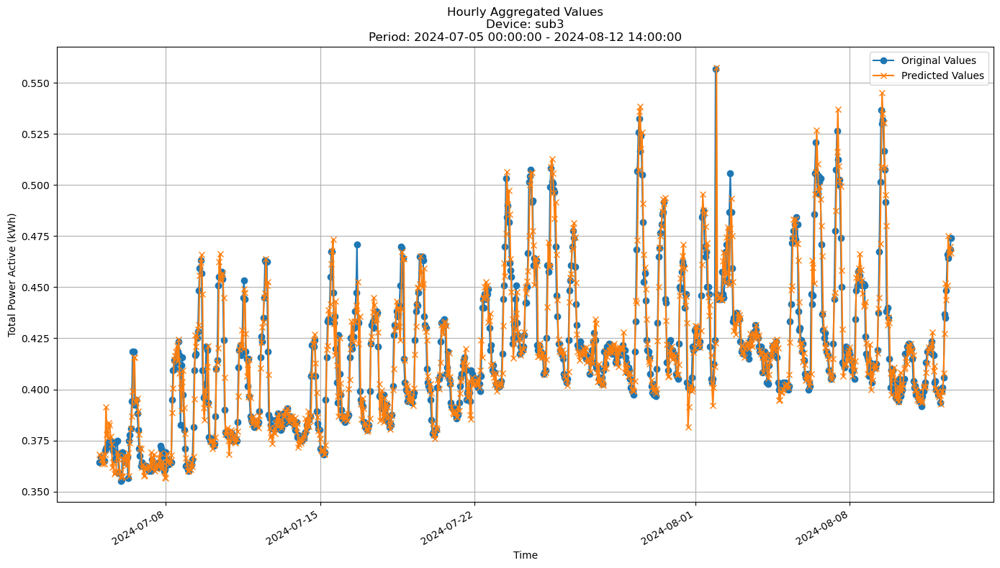


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0114
MAE: 0.0067
MAPE: 1.5656%

Directional Metrics:
Directional Accuracy: 52.5918%
First-Diff Correlation: 0.2170

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


C:\Users\stros\AppData\Local\Temp\ipykernel_24896\2150036773.py:8: FutureWarning: The behavior of array concatenation with empty entries is deprecated. In a future version, this will no longer exclude empty items when determining the result dtype. To retain the old behavior, exclude the empty entries before the concat operation.
  y_valid = pd.concat([y_valid, bl_mean_valid_period_predictions[device_id][i]['y_true']], axis=0)
C:\Users\stros\AppData\Local\Temp\ipykernel_24896\2150036773.py:9: FutureWarning: The behavior of array concatenation with empty entries is deprecated. In a future version, this will no longer exclude empty items when determining the result dtype. To retain the old behavior, exclude the empty entries before the concat operation.
  y_pred_valid = pd.concat([y_pred_valid, bl_mean_valid_period_predictions[device_id][i]['y_pred']], axis=0)
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and wil

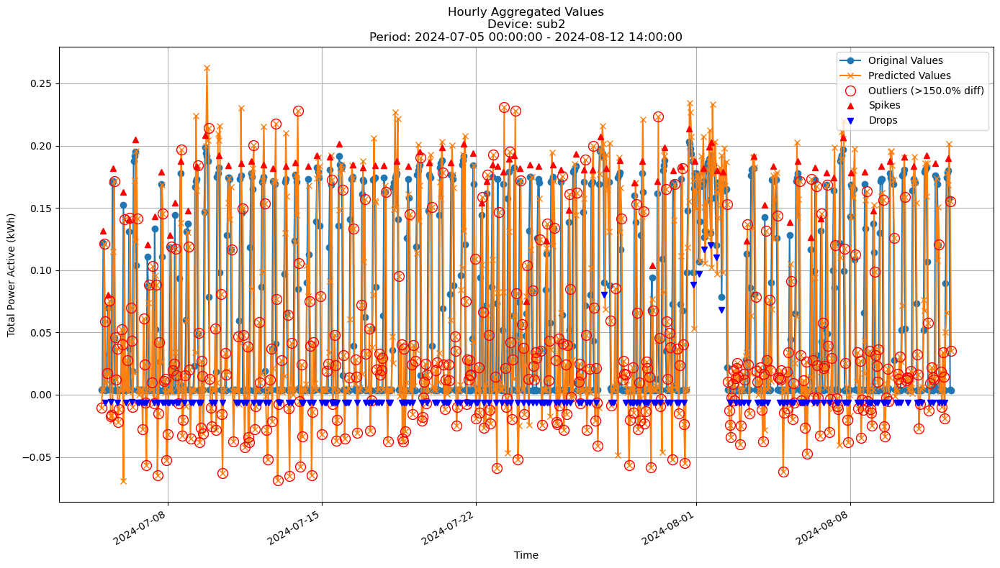


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0636
MAE: 0.0425
MAPE: 458.1416%

Directional Metrics:
Directional Accuracy: 52.5918%
First-Diff Correlation: 0.0855

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


C:\Users\stros\AppData\Local\Temp\ipykernel_24896\2150036773.py:8: FutureWarning: The behavior of array concatenation with empty entries is deprecated. In a future version, this will no longer exclude empty items when determining the result dtype. To retain the old behavior, exclude the empty entries before the concat operation.
  y_valid = pd.concat([y_valid, bl_mean_valid_period_predictions[device_id][i]['y_true']], axis=0)
C:\Users\stros\AppData\Local\Temp\ipykernel_24896\2150036773.py:9: FutureWarning: The behavior of array concatenation with empty entries is deprecated. In a future version, this will no longer exclude empty items when determining the result dtype. To retain the old behavior, exclude the empty entries before the concat operation.
  y_pred_valid = pd.concat([y_pred_valid, bl_mean_valid_period_predictions[device_id][i]['y_pred']], axis=0)
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and wil

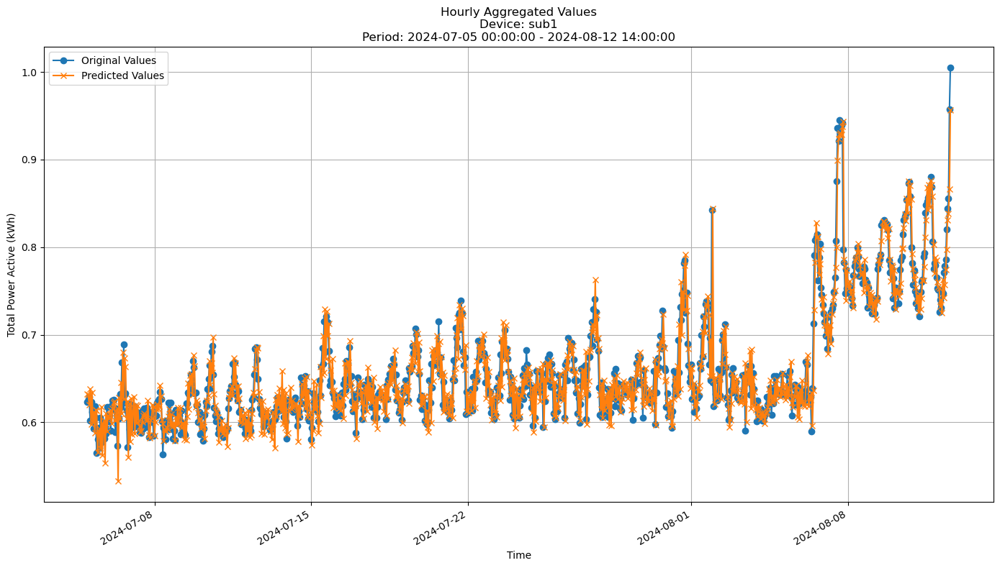


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0260
MAE: 0.0190
MAPE: 2.8926%

Directional Metrics:
Directional Accuracy: 39.3089%
First-Diff Correlation: -0.2948

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [30]:
join_periods = [-2, -1]
# Device iteration
for device_id in bl_mean_valid_period_predictions.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, bl_mean_valid_period_predictions[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, bl_mean_valid_period_predictions[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid,
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id,
                            outlier_threshold=1.5,
                            )

### Baseline model (predict previous value)

In [31]:
update_freq = "1H"
bl_prev = PreviousValueRegressor
bl_prev_params = {'is_residual': USE_RESIDUAL}

In [32]:
bl_prev_train_period_predictions, bl_prev_valid_period_predictions,\
bl_prev_train_period_metrics, bl_prev_valid_period_metrics = all_valid_splits_seq_fit_predict(
    model_class=bl_prev,
    model_params=bl_prev_params,
    train=train,
    valid=valid,
    use_residuals=USE_RESIDUAL,
    incremental=True,
    data_freq=DATA_FREQUENCY,
    forecast_horizon=FORECAST_HORIZON,
    features=ALL_FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE,
    start_split=0,
    verbose=True
)

Processing splits:   0%|          | 0/2 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/3 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2024-06-07 01:00:00+02:00 to 2024-07-04 23:00:00+02:00
Model's memory usage: 0.000488 MB
Metrics for Device: sub3 | Period: 2024-07-05 00:00:00+02:00 - 2024-08-01 23:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0131
	MAE: 0.0073
	MAPE: 1.7045%

Directional Metrics:
	Directional Accuracy: 51.1177%
	First-Diff Correlation: 0.1186

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 0.9583
		F1: 0.9787
	Drops:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
--------------------------------------------------
Daily

c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\evaluation\metrics.py:356: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  if freq_td > pd.Timedelta(C.Freq.H1):
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  return x1.resample(freq).agg(aggregation), x2.resample(freq).agg(aggregation)
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\evaluation\metrics.py:356: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  if freq_td > pd.Timedelta(C.Freq.H1):
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  return x1.resample(freq).agg(aggregation), x2.resample(f

Model's memory usage: 0.000481 MB
Metrics for Device: sub2 | Period: 2024-07-05 00:00:00+02:00 - 2024-08-01 23:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0601
	MAE: 0.0335
	MAPE: 258.9494%

Directional Metrics:
	Directional Accuracy: 42.1759%
	First-Diff Correlation: 0.1024

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
	Drops:
		Precision: 1.0000
		Recall: 0.9925
		F1: 0.9962
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0668
	MAE: 0.0398
	MAPE: 3.0573%

Directional Metrics:
	Directional Accuracy: 96.2963%
	First-Diff Correlation

c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\evaluation\metrics.py:356: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  if freq_td > pd.Timedelta(C.Freq.H1):
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  return x1.resample(freq).agg(aggregation), x2.resample(freq).agg(aggregation)
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\evaluation\metrics.py:356: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  if freq_td > pd.Timedelta(C.Freq.H1):
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  return x1.resample(freq).agg(aggregation), x2.resample(f

... (5 outputs left out)

Model's memory usage: 0.000458 MB
Metrics for Device: sub2 | Period: 2024-08-02 00:00:00+02:00 - 2024-08-12 14:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0556
	MAE: 0.0292
	MAPE: 228.5929%

Directional Metrics:
	Directional Accuracy: 40.1575%
	First-Diff Correlation: 0.1059

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
	Drops:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0888
	MAE: 0.0538
	MAPE: 4.1233%

Directional Metrics:
	Directional Accuracy: 100.0000%
	First-Diff Correlatio

c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\evaluation\metrics.py:356: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  if freq_td > pd.Timedelta(C.Freq.H1):
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  return x1.resample(freq).agg(aggregation), x2.resample(freq).agg(aggregation)
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\evaluation\metrics.py:356: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  if freq_td > pd.Timedelta(C.Freq.H1):
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  return x1.resample(freq).agg(aggregation), x2.resample(f

Model's memory usage: 0.000450 MB
Metrics for Device: sub1 | Period: 2024-08-02 00:00:00+02:00 - 2024-08-12 14:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0244
	MAE: 0.0170
	MAPE: 2.3582%

Directional Metrics:
	Directional Accuracy: 50.7874%
	First-Diff Correlation: 0.0308

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
	Drops:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0786
	MAE: 0.0408
	MAPE: 0.2912%

Directional Metrics:
	Directional Accuracy: 100.0000%
	First-Diff Correlation:

c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\evaluation\metrics.py:356: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  if freq_td > pd.Timedelta(C.Freq.H1):
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  return x1.resample(freq).agg(aggregation), x2.resample(freq).agg(aggregation)
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\evaluation\metrics.py:356: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  if freq_td > pd.Timedelta(C.Freq.H1):
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  return x1.resample(freq).agg(aggregation), x2.resample(f

#### Results

In [33]:
print("\n\nValid period metrics:")
bl_prev_all_time_valid_metrics = all_time_aggregation_metrics(bl_prev_valid_period_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Valid period metrics:


Aggregated Metrics Across Periods
Device ID: sub3
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.0125 ± 0.0006
	MAE: 0.0072 ± 0.0001
	MAPE: 1.6495% ± 0.0550%

	Directional Metrics:
		Directional Accuracy: 50.9526% ± 0.1652%
		First-Diff Correlation: 0.2498 ± 0.1312

	Immediate Detection (delta=0):
		Spike Precision: 0.0000 ± 0.0000
		Spike Recall: 0.0000 ± 0.0000
		Spike F1: 0.0000 ± 0.0000
		Drop Precision: 0.0000 ± 0.0000
		Drop Recall: 0.0000 ± 0.0000
		Drop F1: 0.0000 ± 0.0000

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 1.0000 ± 0.0000
		Spike Recall: 0.9792 ± 0.0208
		Spike F1: 0.9894 ± 0.0106
		Drop Precision: 1.0000 ± 0.0000
		Drop Recall: 1.0000 ± 0.0000
		Drop F1: 1.0000 ± 0.0000
Daily Metrics:
	RMSE: 0.0167 ± 0.0076
	MAE: 0.0106 ± 0.0034
	MAPE: 0.1238% ± 0.0515%

	Directional Metrics:
		Directional Accuracy: 100.0000% ± 0.0000%
		First-Diff Correlation: 0.9996 ± 0.0003

	Immediate Detection (delta=0):
		Spike

#### Validation plots

C:\Users\stros\AppData\Local\Temp\ipykernel_24896\2606948080.py:8: FutureWarning: The behavior of array concatenation with empty entries is deprecated. In a future version, this will no longer exclude empty items when determining the result dtype. To retain the old behavior, exclude the empty entries before the concat operation.
  y_valid = pd.concat([y_valid, bl_prev_valid_period_predictions[device_id][i]['y_true']], axis=0)
C:\Users\stros\AppData\Local\Temp\ipykernel_24896\2606948080.py:9: FutureWarning: The behavior of array concatenation with empty entries is deprecated. In a future version, this will no longer exclude empty items when determining the result dtype. To retain the old behavior, exclude the empty entries before the concat operation.
  y_pred_valid = pd.concat([y_pred_valid, bl_prev_valid_period_predictions[device_id][i]['y_pred']], axis=0)
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and wil

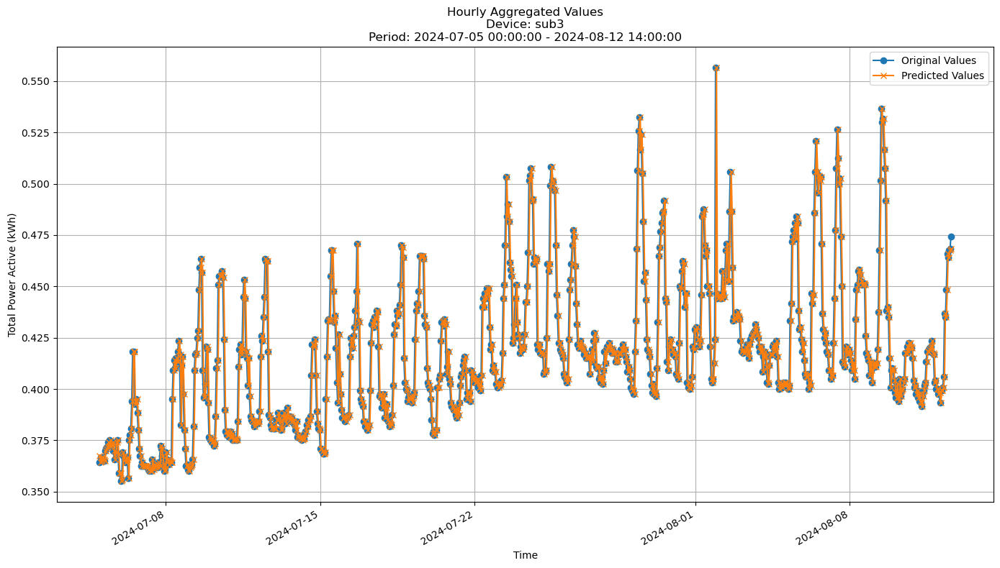


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0128
MAE: 0.0072
MAPE: 1.6742%

Directional Metrics:
Directional Accuracy: 51.0799%
First-Diff Correlation: 0.1775

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


C:\Users\stros\AppData\Local\Temp\ipykernel_24896\2606948080.py:8: FutureWarning: The behavior of array concatenation with empty entries is deprecated. In a future version, this will no longer exclude empty items when determining the result dtype. To retain the old behavior, exclude the empty entries before the concat operation.
  y_valid = pd.concat([y_valid, bl_prev_valid_period_predictions[device_id][i]['y_true']], axis=0)
C:\Users\stros\AppData\Local\Temp\ipykernel_24896\2606948080.py:9: FutureWarning: The behavior of array concatenation with empty entries is deprecated. In a future version, this will no longer exclude empty items when determining the result dtype. To retain the old behavior, exclude the empty entries before the concat operation.
  y_pred_valid = pd.concat([y_pred_valid, bl_prev_valid_period_predictions[device_id][i]['y_pred']], axis=0)
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and wil

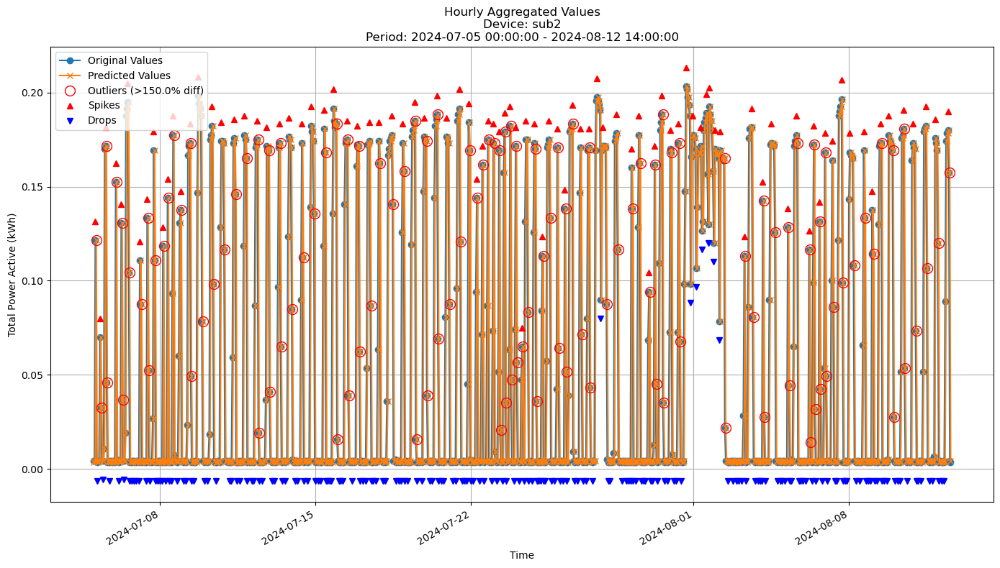


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0589
MAE: 0.0323
MAPE: 250.5989%

Directional Metrics:
Directional Accuracy: 41.5767%
First-Diff Correlation: 0.1032

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 1.0000
  Recall: 1.0000
  F1 Score: 1.0000
Drops:
  Precision: 1.0000
  Recall: 1.0000
  F1 Score: 1.0000


C:\Users\stros\AppData\Local\Temp\ipykernel_24896\2606948080.py:8: FutureWarning: The behavior of array concatenation with empty entries is deprecated. In a future version, this will no longer exclude empty items when determining the result dtype. To retain the old behavior, exclude the empty entries before the concat operation.
  y_valid = pd.concat([y_valid, bl_prev_valid_period_predictions[device_id][i]['y_true']], axis=0)
C:\Users\stros\AppData\Local\Temp\ipykernel_24896\2606948080.py:9: FutureWarning: The behavior of array concatenation with empty entries is deprecated. In a future version, this will no longer exclude empty items when determining the result dtype. To retain the old behavior, exclude the empty entries before the concat operation.
  y_pred_valid = pd.concat([y_pred_valid, bl_prev_valid_period_predictions[device_id][i]['y_pred']], axis=0)
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and wil

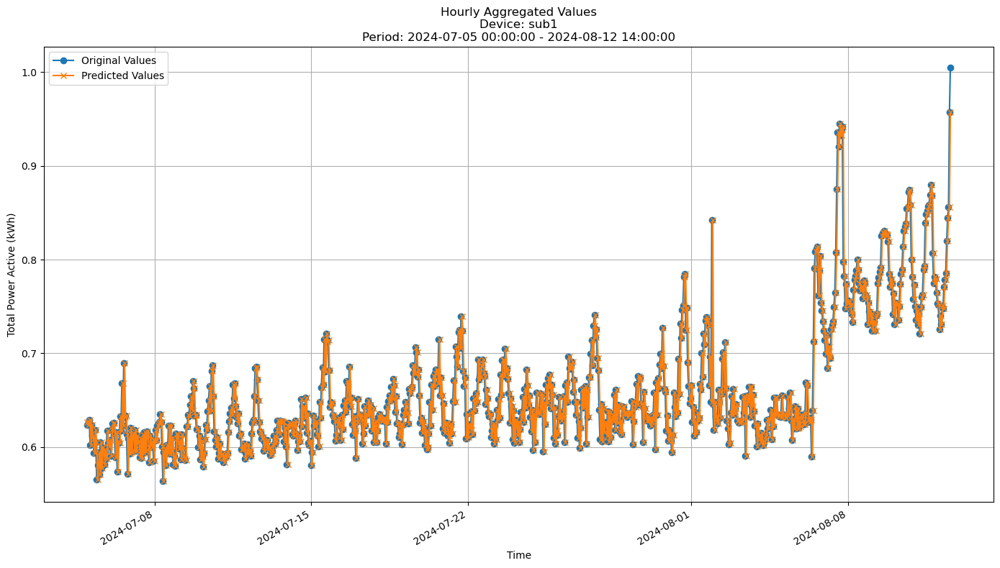


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0250
MAE: 0.0181
MAPE: 2.7465%

Directional Metrics:
Directional Accuracy: 37.0410%
First-Diff Correlation: -0.3698

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [34]:
join_periods = [-2, -1]
# Device iteration
for device_id in bl_prev_valid_period_predictions.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, bl_prev_valid_period_predictions[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, bl_prev_valid_period_predictions[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid,
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id,
                            outlier_threshold=1.5,
                            )

### GBDT

In [35]:
update_freq = "14D"  # Update the model every 14 days
gbdt = GradientBoostingRegressor
# gbdt_params = {
#     'n_estimators': 100,
#     'learning_rate': 0.03,
#     'subsample': 0.8,
#     'max_depth': 10,
#     'random_state': 42
# }
gbdt_params = {'n_estimators': 100, 
 'learning_rate': 0.05, 
 'max_depth': 3, 
 'subsample': 0.6, 
 'random_state': 42}

In [36]:
gbdt_train_period_predictions, gbdt_valid_period_predictions, \
gbdt_train_period_metrics, gbdt_valid_period_metrics = all_valid_splits_seq_fit_predict(
    model_class=gbdt,
    model_params=gbdt_params,
    train=train, 
    valid=valid, 
    incremental=False,
    use_residuals=USE_RESIDUAL,
    data_freq=DATA_FREQUENCY, 
    forecast_horizon=FORECAST_HORIZON,
    features=ALL_FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE,
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=1
)

Processing splits:   0%|          | 0/2 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/3 [00:00<?, ?it/s]


Retraining model on data from 2024-06-07 01:00:00+02:00 to 2024-07-04 23:00:00+02:00

Time: 0.18 seconds
Predicting for chunk from 2024-07-05 00:00:00+02:00 to 2024-07-19 00:00:00+02:00

-------------------------

Retraining model on data from 2024-06-07 01:00:00+02:00 to 2024-07-19 00:00:00+02:00

Time: 0.17 seconds
Predicting for chunk from 2024-07-19 01:00:00+02:00 to 2024-08-01 23:00:00+02:00

-------------------------
Model's memory usage: 0.010368 MB


c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\evaluation\metrics.py:356: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  if freq_td > pd.Timedelta(C.Freq.H1):
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  return x1.resample(freq).agg(aggregation), x2.resample(freq).agg(aggregation)
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\evaluation\metrics.py:356: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  if freq_td > pd.Timedelta(C.Freq.H1):
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  return x1.resample(freq).agg(aggregation), x2.resample(f

Metrics for Device: sub3 | Period: 2024-07-05 00:00:00+02:00 - 2024-08-01 23:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0129
	MAE: 0.0080
	MAPE: 1.8516%

Directional Metrics:
	Directional Accuracy: 51.2668%
	First-Diff Correlation: 0.1148

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.1429
		Recall: 0.1250
		F1: 0.1333
	Drops:
		Precision: 0.0952
		Recall: 0.0800
		F1: 0.0870

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.7143
		Recall: 0.6250
		F1: 0.6667
	Drops:
		Precision: 0.3810
		Recall: 0.3200
		F1: 0.3478
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.1110
	MAE: 0.0877
	MAPE: 0.8605%

Directional Metrics:
	Directional Accuracy: 100.0000%
	First-Diff Correlation: 0.9880

Immediate Detection (delt

c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\evaluation\metrics.py:356: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  if freq_td > pd.Timedelta(C.Freq.H1):
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  return x1.resample(freq).agg(aggregation), x2.resample(freq).agg(aggregation)
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\evaluation\metrics.py:356: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  if freq_td > pd.Timedelta(C.Freq.H1):
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  return x1.resample(freq).agg(aggregation), x2.resample(f

... (5 outputs left out)


Time: 0.18 seconds
Predicting for chunk from 2024-08-02 00:00:00+02:00 to 2024-08-12 14:00:00+02:00

-------------------------
Model's memory usage: 0.010139 MB
Metrics for Device: sub2 | Period: 2024-08-02 00:00:00+02:00 - 2024-08-12 14:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0466
	MAE: 0.0339
	MAPE: 415.2691%

Directional Metrics:
	Directional Accuracy: 58.2677%
	First-Diff Correlation: 0.2331

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.3043
		Recall: 0.2917
		F1: 0.2979
	Drops:
		Precision: 0.4783
		Recall: 0.2075
		F1: 0.2895

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.9130
		Recall: 0.8750
		F1: 0.8936
	Drops:
		Precision: 1.0000
		Recall: 0.4340
		F1: 0.6053
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
Basic Prediction 

c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\evaluation\metrics.py:356: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  if freq_td > pd.Timedelta(C.Freq.H1):
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  return x1.resample(freq).agg(aggregation), x2.resample(freq).agg(aggregation)
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\evaluation\metrics.py:356: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  if freq_td > pd.Timedelta(C.Freq.H1):
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  return x1.resample(freq).agg(aggregation), x2.resample(f


Time: 0.20 seconds
Predicting for chunk from 2024-08-02 00:00:00+02:00 to 2024-08-12 14:00:00+02:00

-------------------------
Model's memory usage: 0.010101 MB
Metrics for Device: sub1 | Period: 2024-08-02 00:00:00+02:00 - 2024-08-12 14:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0271
	MAE: 0.0195
	MAPE: 2.7199%

Directional Metrics:
	Directional Accuracy: 51.9685%
	First-Diff Correlation: 0.0423

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.5000
		Recall: 1.0000
		F1: 0.6667
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
Basic Prediction Me

c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\evaluation\metrics.py:356: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  if freq_td > pd.Timedelta(C.Freq.H1):
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  return x1.resample(freq).agg(aggregation), x2.resample(freq).agg(aggregation)
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\evaluation\metrics.py:356: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  if freq_td > pd.Timedelta(C.Freq.H1):
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  return x1.resample(freq).agg(aggregation), x2.resample(f

#### Results

In [37]:
print("\n\nTrain period metrics:")
gbdt_all_time_train_metrics = all_time_aggregation_metrics(gbdt_train_period_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\nValid period metrics:")
gbdt_all_time_valid_metrics = all_time_aggregation_metrics(gbdt_valid_period_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: sub3
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.0073 ± 0.0009
	MAE: 0.0049 ± 0.0005
	MAPE: 1.2675% ± 0.0835%

	Directional Metrics:
		Directional Accuracy: 53.8779% ± 0.3012%
		First-Diff Correlation: 0.4752 ± 0.0516

	Immediate Detection (delta=0):
		Spike Precision: 0.2488 ± 0.0215
		Spike Recall: 0.2386 ± 0.0114
		Spike F1: 0.2435 ± 0.0162
		Drop Precision: 0.1152 ± 0.0199
		Drop Recall: 0.0972 ± 0.0139
		Drop F1: 0.1054 ± 0.0165

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.8053 ± 0.0326
		Spike Recall: 0.7739 ± 0.0011
		Spike F1: 0.7890 ± 0.0162
		Drop Precision: 0.7864 ± 0.0245
		Drop Recall: 0.6667 ± 0.0000
		Drop F1: 0.7214 ± 0.0103
Daily Metrics:
	RMSE: 0.0264 ± 0.0022
	MAE: 0.0218 ± 0.0013
	MAPE: 0.2366% ± 0.0085%

	Directional Metrics:
		Directional Accuracy: 100.0000% ± 0.0000%
		First-Diff Correlation: 0.9967 ± 0.0005

	Immediate Detection (delta=0):
		Spike

#### Training plots

c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  return x1.resample(freq).agg(aggregation), x2.resample(freq).agg(aggregation)
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\evaluation\metrics.py:356: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  if freq_td > pd.Timedelta(C.Freq.H1):
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  return x1.resample(freq).agg(aggregation), x2.resample(freq).agg(aggregation)
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\evaluation\metrics.py:356: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  if freq_td > pd.

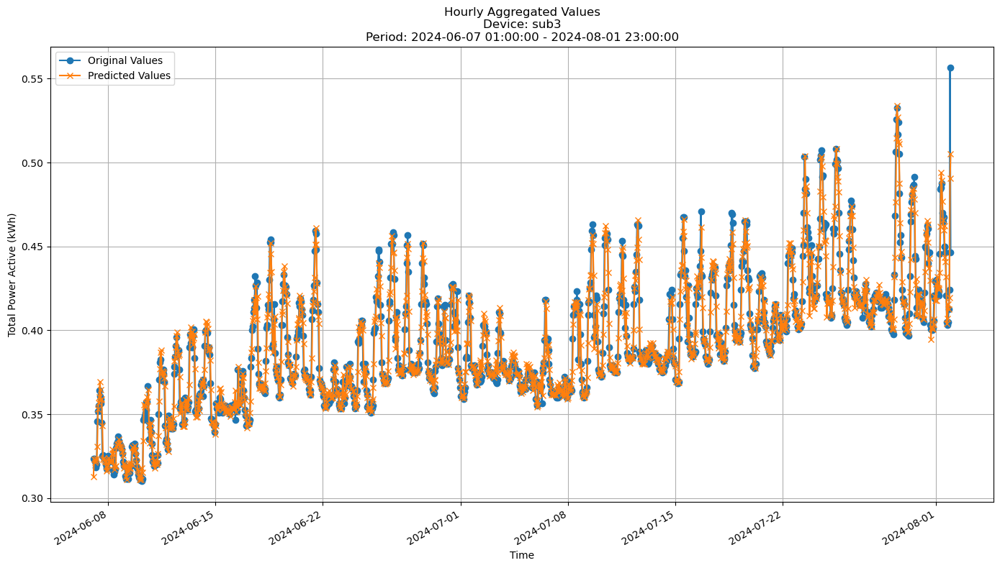


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0082
MAE: 0.0054
MAPE: 1.3510%

Directional Metrics:
Directional Accuracy: 53.5768%
First-Diff Correlation: 0.4236

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  return x1.resample(freq).agg(aggregation), x2.resample(freq).agg(aggregation)
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\evaluation\metrics.py:356: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  if freq_td > pd.Timedelta(C.Freq.H1):
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  return x1.resample(freq).agg(aggregation), x2.resample(freq).agg(aggregation)
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\evaluation\metrics.py:356: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  if freq_td > pd.

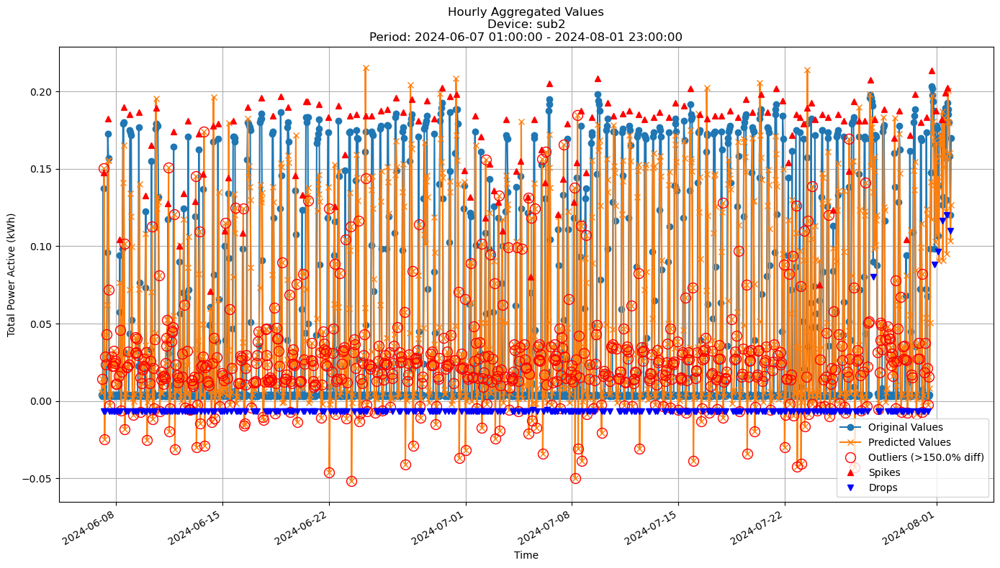


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0426
MAE: 0.0298
MAPE: 345.8716%

Directional Metrics:
Directional Accuracy: 59.0909%
First-Diff Correlation: 0.3334

Immediate Detection (delta=0):
Spikes:
  Precision: 0.3750
  Recall: 0.0219
  F1 Score: 0.0414
Drops:
  Precision: 0.3333
  Recall: 0.0111
  F1 Score: 0.0214

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.7500
  Recall: 0.0438
  F1 Score: 0.0828
Drops:
  Precision: 0.6667
  Recall: 0.0221
  F1 Score: 0.0429


c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  return x1.resample(freq).agg(aggregation), x2.resample(freq).agg(aggregation)
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\evaluation\metrics.py:356: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  if freq_td > pd.Timedelta(C.Freq.H1):
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  return x1.resample(freq).agg(aggregation), x2.resample(freq).agg(aggregation)
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\evaluation\metrics.py:356: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  if freq_td > pd.

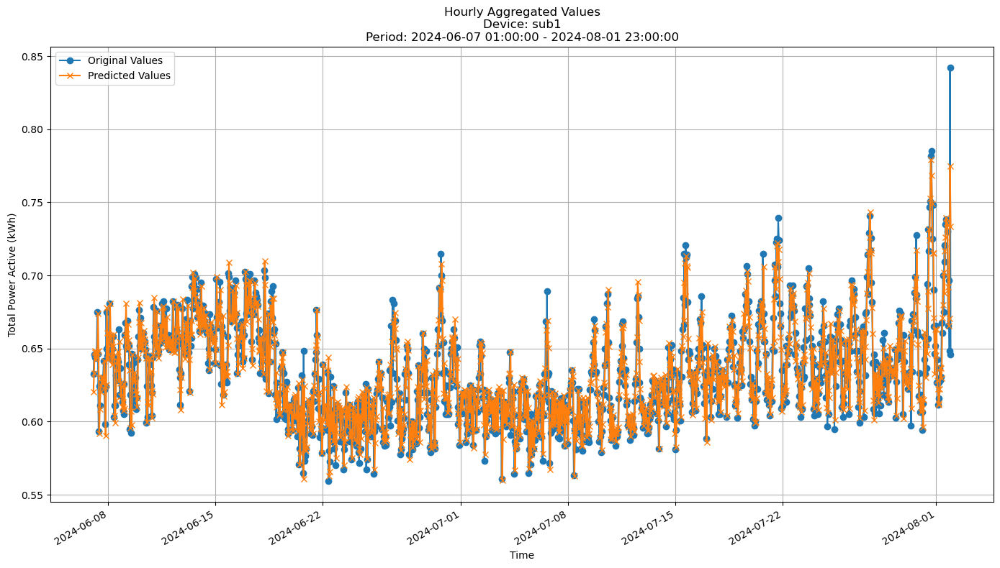


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0203
MAE: 0.0158
MAPE: 2.5010%

Directional Metrics:
Directional Accuracy: 36.5127%
First-Diff Correlation: -0.2886

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [38]:
for device_id in gbdt_train_period_predictions.keys():
    y_train = gbdt_train_period_predictions[device_id][-1]['y_true']
    y_pred_train = gbdt_train_period_predictions[device_id][-1]['y_pred']
    
    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train, 
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id,
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last few periods of predictions

C:\Users\stros\AppData\Local\Temp\ipykernel_24896\215882064.py:8: FutureWarning: The behavior of array concatenation with empty entries is deprecated. In a future version, this will no longer exclude empty items when determining the result dtype. To retain the old behavior, exclude the empty entries before the concat operation.
  y_valid = pd.concat([y_valid, gbdt_valid_period_predictions[device_id][i]['y_true']], axis=0)
C:\Users\stros\AppData\Local\Temp\ipykernel_24896\215882064.py:9: FutureWarning: The behavior of array concatenation with empty entries is deprecated. In a future version, this will no longer exclude empty items when determining the result dtype. To retain the old behavior, exclude the empty entries before the concat operation.
  y_pred_valid = pd.concat([y_pred_valid, gbdt_valid_period_predictions[device_id][i]['y_pred']], axis=0)
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be rem

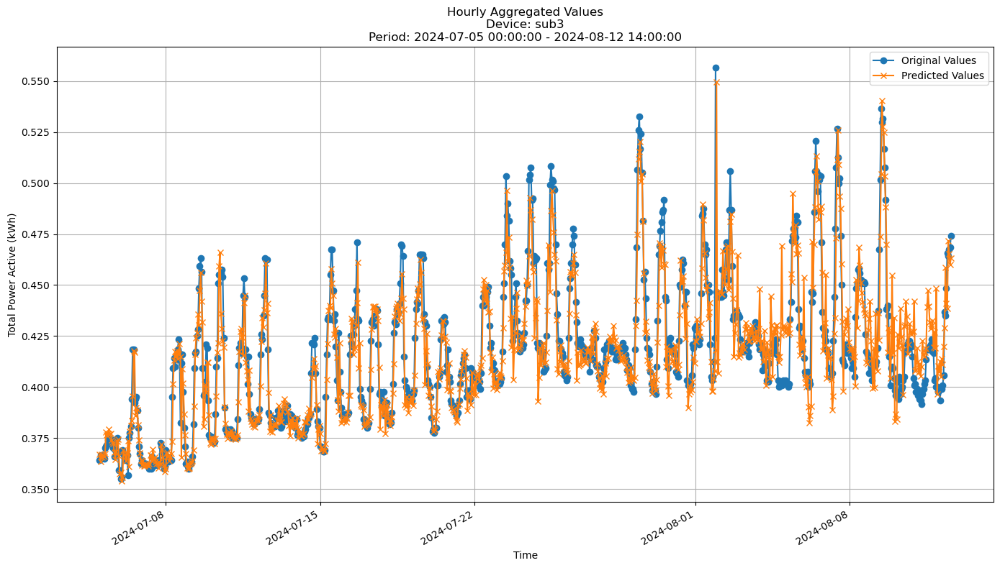


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0144
MAE: 0.0096
MAPE: 2.2331%

Directional Metrics:
Directional Accuracy: 50.1080%
First-Diff Correlation: 0.1457

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


C:\Users\stros\AppData\Local\Temp\ipykernel_24896\215882064.py:8: FutureWarning: The behavior of array concatenation with empty entries is deprecated. In a future version, this will no longer exclude empty items when determining the result dtype. To retain the old behavior, exclude the empty entries before the concat operation.
  y_valid = pd.concat([y_valid, gbdt_valid_period_predictions[device_id][i]['y_true']], axis=0)
C:\Users\stros\AppData\Local\Temp\ipykernel_24896\215882064.py:9: FutureWarning: The behavior of array concatenation with empty entries is deprecated. In a future version, this will no longer exclude empty items when determining the result dtype. To retain the old behavior, exclude the empty entries before the concat operation.
  y_pred_valid = pd.concat([y_pred_valid, gbdt_valid_period_predictions[device_id][i]['y_pred']], axis=0)
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be rem

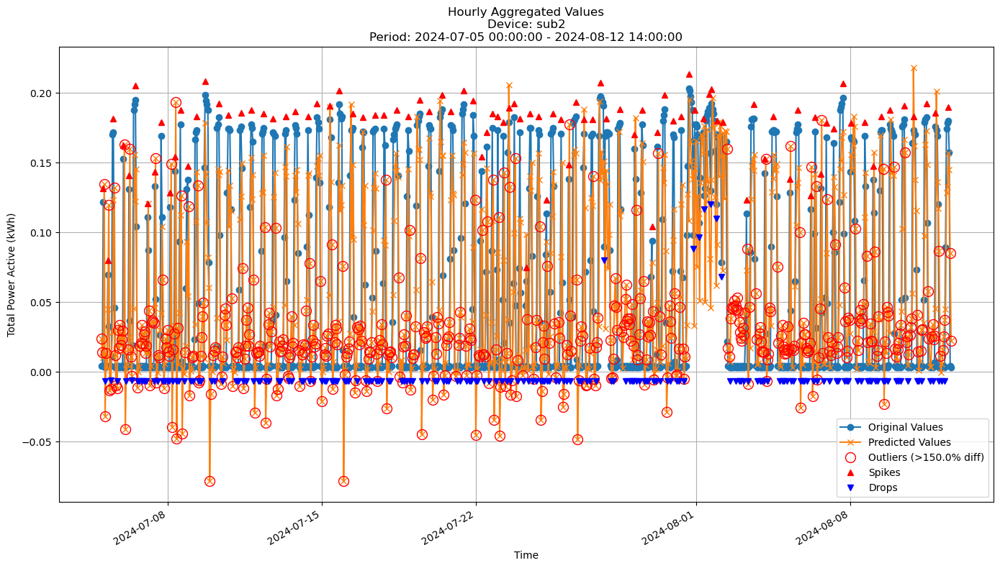


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0485
MAE: 0.0348
MAPE: 370.1699%

Directional Metrics:
Directional Accuracy: 57.7754%
First-Diff Correlation: 0.2705

Immediate Detection (delta=0):
Spikes:
  Precision: 1.0000
  Recall: 0.0104
  F1 Score: 0.0206
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 1.0000
  Recall: 0.0104
  F1 Score: 0.0206
Drops:
  Precision: 0.5000
  Recall: 0.0054
  F1 Score: 0.0106


C:\Users\stros\AppData\Local\Temp\ipykernel_24896\215882064.py:8: FutureWarning: The behavior of array concatenation with empty entries is deprecated. In a future version, this will no longer exclude empty items when determining the result dtype. To retain the old behavior, exclude the empty entries before the concat operation.
  y_valid = pd.concat([y_valid, gbdt_valid_period_predictions[device_id][i]['y_true']], axis=0)
C:\Users\stros\AppData\Local\Temp\ipykernel_24896\215882064.py:9: FutureWarning: The behavior of array concatenation with empty entries is deprecated. In a future version, this will no longer exclude empty items when determining the result dtype. To retain the old behavior, exclude the empty entries before the concat operation.
  y_pred_valid = pd.concat([y_pred_valid, gbdt_valid_period_predictions[device_id][i]['y_pred']], axis=0)
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be rem

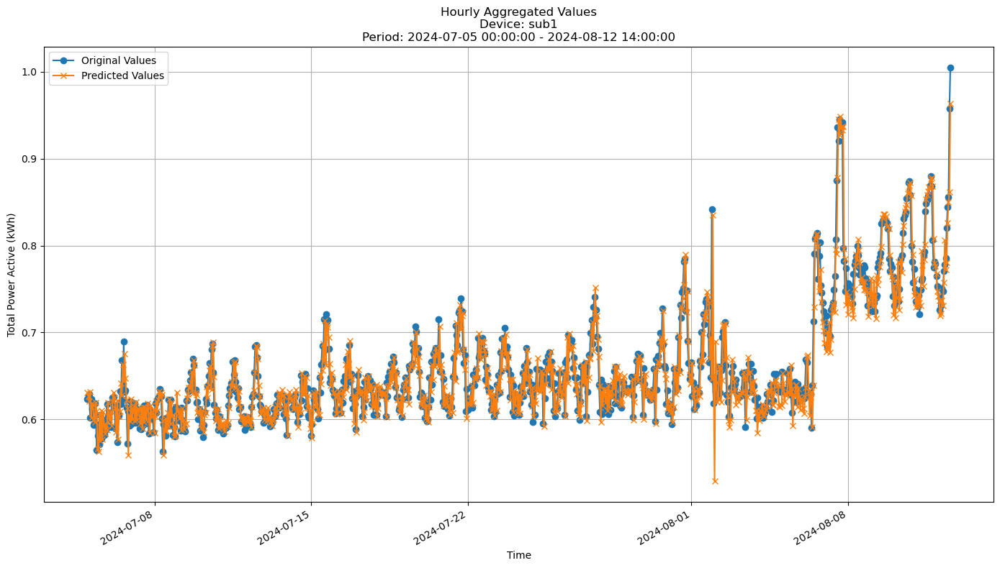


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0255
MAE: 0.0187
MAPE: 2.8214%

Directional Metrics:
Directional Accuracy: 37.6890%
First-Diff Correlation: -0.3266

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [39]:
join_periods = [-2, -1]
# Device iteration
for device_id in gbdt_valid_period_predictions.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, gbdt_valid_period_predictions[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, gbdt_valid_period_predictions[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid, 
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id, 
                            outlier_threshold=1.5)

### Random Forest model

In [40]:
update_freq = "14D"  # Update the model every 14 days
rf = RandomForestRegressor
rf_params = {'n_estimators': 300, 
 'max_depth': 7, 
 'max_features': 1.0, 
 'random_state': 42, 
 'n_jobs': -1}

In [41]:
rf_train_period_predictions, rf_valid_period_predictions, \
rf_train_period_metrics, rf_valid_period_metrics = all_valid_splits_seq_fit_predict(
    model_class=rf, 
    model_params=rf_params,
    train=train, 
    valid=valid, 
    use_residuals=USE_RESIDUAL,
    incremental=False,
    data_freq=DATA_FREQUENCY, 
    forecast_horizon=FORECAST_HORIZON,
    features=ALL_FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE,
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=1
)

Processing splits:   0%|          | 0/2 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/3 [00:00<?, ?it/s]


Retraining model on data from 2024-06-07 01:00:00+02:00 to 2024-07-04 23:00:00+02:00

Time: 0.53 seconds
Predicting for chunk from 2024-07-05 00:00:00+02:00 to 2024-07-19 00:00:00+02:00

-------------------------

Retraining model on data from 2024-06-07 01:00:00+02:00 to 2024-07-19 00:00:00+02:00

Time: 0.51 seconds
Predicting for chunk from 2024-07-19 01:00:00+02:00 to 2024-08-01 23:00:00+02:00

-------------------------
Model's memory usage: 0.117340 MB
Metrics for Device: sub3 | Period: 2024-07-05 00:00:00+02:00 - 2024-08-01 23:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0124
	MAE: 0.0077
	MAPE: 1.7851%

Directional Metrics:
	Directional Accuracy: 50.9687%
	First-Diff Correlation: 0.1319

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.1429
		Recall: 0.1250
		F1: 0.1333
	Drops:
		Precision: 0.1429
		Recall: 0.1200
		F1: 0.1304

Delayed Detection (delta=1 

c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\evaluation\metrics.py:356: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  if freq_td > pd.Timedelta(C.Freq.H1):
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  return x1.resample(freq).agg(aggregation), x2.resample(freq).agg(aggregation)
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\evaluation\metrics.py:356: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  if freq_td > pd.Timedelta(C.Freq.H1):
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  return x1.resample(freq).agg(aggregation), x2.resample(f


Time: 0.48 seconds
Predicting for chunk from 2024-07-05 00:00:00+02:00 to 2024-07-19 00:00:00+02:00

-------------------------

Retraining model on data from 2024-06-07 01:00:00+02:00 to 2024-07-19 00:00:00+02:00

Time: 0.57 seconds
Predicting for chunk from 2024-07-19 01:00:00+02:00 to 2024-08-01 23:00:00+02:00

-------------------------
Model's memory usage: 0.117332 MB


c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\evaluation\metrics.py:356: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  if freq_td > pd.Timedelta(C.Freq.H1):
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  return x1.resample(freq).agg(aggregation), x2.resample(freq).agg(aggregation)
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\evaluation\metrics.py:356: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  if freq_td > pd.Timedelta(C.Freq.H1):
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  return x1.resample(freq).agg(aggregation), x2.resample(f

... (5 outputs left out)

Metrics for Device: sub3 | Period: 2024-08-02 00:00:00+02:00 - 2024-08-12 14:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0150
	MAE: 0.0110
	MAPE: 2.5571%

Directional Metrics:
	Directional Accuracy: 51.9685%
	First-Diff Correlation: 0.3319

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0909
		Recall: 0.1667
		F1: 0.1176
	Drops:
		Precision: 0.0909
		Recall: 0.1429
		F1: 0.1111

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.4545
		Recall: 0.8333
		F1: 0.5882
	Drops:
		Precision: 0.1818
		Recall: 0.2857
		F1: 0.2222
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.1465
	MAE: 0.1149
	MAPE: 1.1716%

Directional Metrics:
	Directional Accuracy: 90.0000%
	First-Diff Correlation: 0.9870

Immediate Detection (delta

c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\evaluation\metrics.py:356: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  if freq_td > pd.Timedelta(C.Freq.H1):
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  return x1.resample(freq).agg(aggregation), x2.resample(freq).agg(aggregation)
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\evaluation\metrics.py:356: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  if freq_td > pd.Timedelta(C.Freq.H1):
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  return x1.resample(freq).agg(aggregation), x2.resample(f

Metrics for Device: sub2 | Period: 2024-08-02 00:00:00+02:00 - 2024-08-12 14:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0488
	MAE: 0.0359
	MAPE: 444.9217%

Directional Metrics:
	Directional Accuracy: 53.5433%
	First-Diff Correlation: 0.2094

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.3478
		Recall: 0.3333
		F1: 0.3404
	Drops:
		Precision: 0.3913
		Recall: 0.1698
		F1: 0.2368

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.9565
		Recall: 0.9167
		F1: 0.9362
	Drops:
		Precision: 1.0000
		Recall: 0.4340
		F1: 0.6053
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2752
	MAE: 0.2034
	MAPE: 15.5153%

Directional Metrics:
	Directional Accuracy: 70.0000%
	First-Diff Correlation: 0.7764

Immediate Detection (de

c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\evaluation\metrics.py:356: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  if freq_td > pd.Timedelta(C.Freq.H1):
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  return x1.resample(freq).agg(aggregation), x2.resample(freq).agg(aggregation)
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\evaluation\metrics.py:356: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  if freq_td > pd.Timedelta(C.Freq.H1):
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  return x1.resample(freq).agg(aggregation), x2.resample(f

#### Results

In [42]:
print("\n\nTrain period metrics:")
rf_all_time_train_metrics = all_time_aggregation_metrics(rf_train_period_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\nValid period metrics:")
rf_all_time_valid_metrics = all_time_aggregation_metrics(rf_valid_period_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: sub3
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.0060 ± 0.0009
	MAE: 0.0041 ± 0.0005
	MAPE: 1.0571% ± 0.0896%

	Directional Metrics:
		Directional Accuracy: 56.2282% ± 1.9808%
		First-Diff Correlation: 0.6137 ± 0.0633

	Immediate Detection (delta=0):
		Spike Precision: 0.2645 ± 0.0212
		Spike Recall: 0.2489 ± 0.0239
		Spike F1: 0.2564 ± 0.0227
		Drop Precision: 0.1176 ± 0.0176
		Drop Recall: 0.0972 ± 0.0139
		Drop F1: 0.1064 ± 0.0155

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.8340 ± 0.0232
		Spike Recall: 0.7841 ± 0.0341
		Spike F1: 0.8082 ± 0.0290
		Drop Precision: 0.8304 ± 0.0196
		Drop Recall: 0.6875 ± 0.0208
		Drop F1: 0.7522 ± 0.0205
Daily Metrics:
	RMSE: 0.0231 ± 0.0023
	MAE: 0.0188 ± 0.0019
	MAPE: 0.2047% ± 0.0161%

	Directional Metrics:
		Directional Accuracy: 100.0000% ± 0.0000%
		First-Diff Correlation: 0.9965 ± 0.0006

	Immediate Detection (delta=0):
		Spike

#### Training plots
Plot only the last period of predictions

c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  return x1.resample(freq).agg(aggregation), x2.resample(freq).agg(aggregation)
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\evaluation\metrics.py:356: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  if freq_td > pd.Timedelta(C.Freq.H1):
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  return x1.resample(freq).agg(aggregation), x2.resample(freq).agg(aggregation)
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\evaluation\metrics.py:356: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  if freq_td > pd.

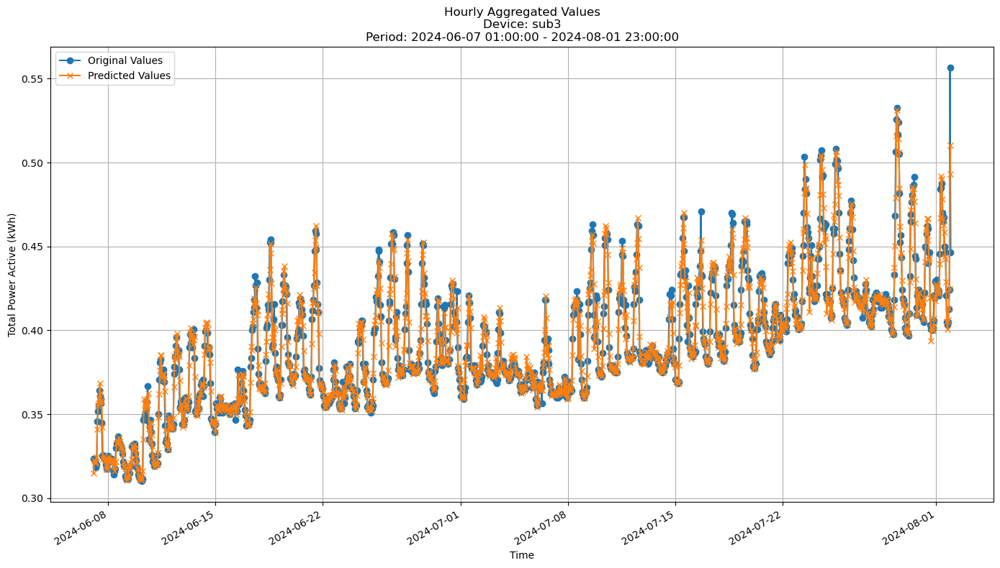


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0070
MAE: 0.0046
MAPE: 1.1468%

Directional Metrics:
Directional Accuracy: 54.2474%
First-Diff Correlation: 0.5505

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  return x1.resample(freq).agg(aggregation), x2.resample(freq).agg(aggregation)
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\evaluation\metrics.py:356: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  if freq_td > pd.Timedelta(C.Freq.H1):
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  return x1.resample(freq).agg(aggregation), x2.resample(freq).agg(aggregation)
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\evaluation\metrics.py:356: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  if freq_td > pd.

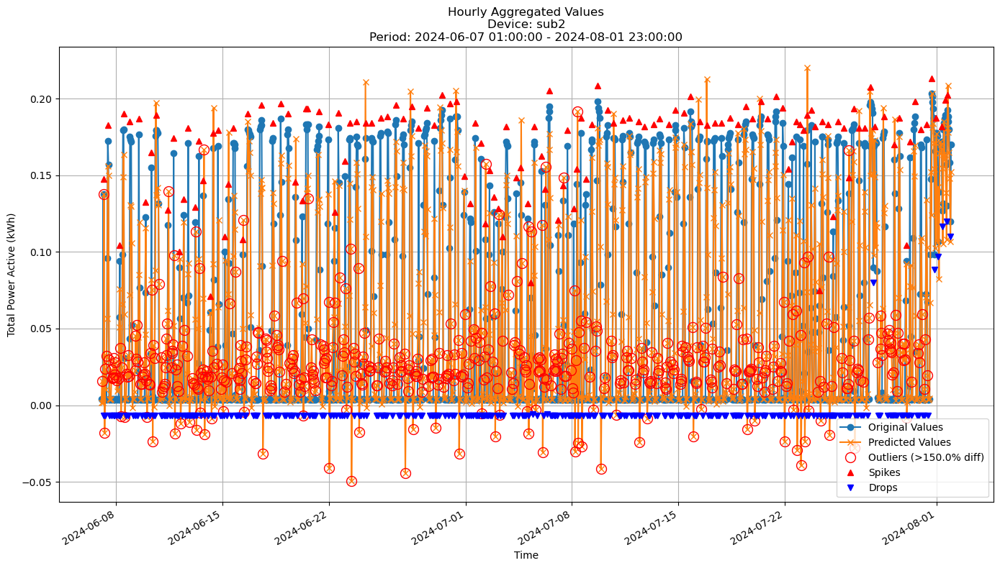


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0365
MAE: 0.0246
MAPE: 277.9912%

Directional Metrics:
Directional Accuracy: 59.0909%
First-Diff Correlation: 0.5069

Immediate Detection (delta=0):
Spikes:
  Precision: 0.4167
  Recall: 0.0365
  F1 Score: 0.0671
Drops:
  Precision: 0.3333
  Recall: 0.0148
  F1 Score: 0.0283

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.8333
  Recall: 0.0730
  F1 Score: 0.1342
Drops:
  Precision: 0.6667
  Recall: 0.0295
  F1 Score: 0.0565


c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  return x1.resample(freq).agg(aggregation), x2.resample(freq).agg(aggregation)
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\evaluation\metrics.py:356: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  if freq_td > pd.Timedelta(C.Freq.H1):
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  return x1.resample(freq).agg(aggregation), x2.resample(freq).agg(aggregation)
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\evaluation\metrics.py:356: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  if freq_td > pd.

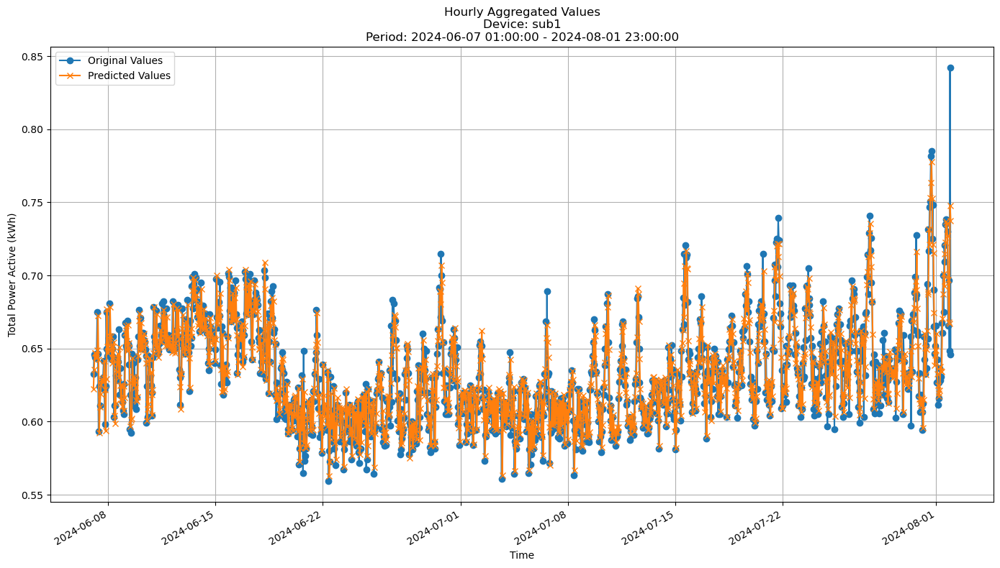


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0187
MAE: 0.0146
MAPE: 2.3068%

Directional Metrics:
Directional Accuracy: 40.3875%
First-Diff Correlation: -0.1899

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [43]:
for device_id in rf_train_period_predictions.keys():
    y_train = rf_train_period_predictions[device_id][-1]['y_true']
    y_pred_train = rf_train_period_predictions[device_id][-1]['y_pred']
    plot_hourly_predictions(y_train, 
                            y_pred_train,
                            data_freq=DATA_FREQUENCY, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last periods of predictions

C:\Users\stros\AppData\Local\Temp\ipykernel_24896\2923230023.py:8: FutureWarning: The behavior of array concatenation with empty entries is deprecated. In a future version, this will no longer exclude empty items when determining the result dtype. To retain the old behavior, exclude the empty entries before the concat operation.
  y_valid = pd.concat([y_valid, rf_valid_period_predictions[device_id][i]['y_true']], axis=0)
C:\Users\stros\AppData\Local\Temp\ipykernel_24896\2923230023.py:9: FutureWarning: The behavior of array concatenation with empty entries is deprecated. In a future version, this will no longer exclude empty items when determining the result dtype. To retain the old behavior, exclude the empty entries before the concat operation.
  y_pred_valid = pd.concat([y_pred_valid, rf_valid_period_predictions[device_id][i]['y_pred']], axis=0)
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be remov

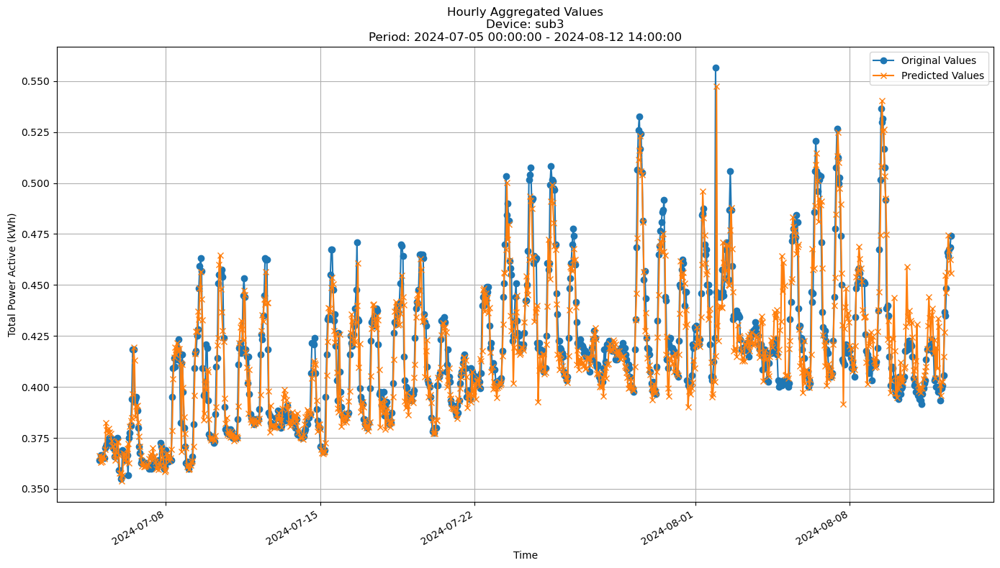


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0132
MAE: 0.0086
MAPE: 1.9974%

Directional Metrics:
Directional Accuracy: 51.2959%
First-Diff Correlation: 0.1815

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


C:\Users\stros\AppData\Local\Temp\ipykernel_24896\2923230023.py:8: FutureWarning: The behavior of array concatenation with empty entries is deprecated. In a future version, this will no longer exclude empty items when determining the result dtype. To retain the old behavior, exclude the empty entries before the concat operation.
  y_valid = pd.concat([y_valid, rf_valid_period_predictions[device_id][i]['y_true']], axis=0)
C:\Users\stros\AppData\Local\Temp\ipykernel_24896\2923230023.py:9: FutureWarning: The behavior of array concatenation with empty entries is deprecated. In a future version, this will no longer exclude empty items when determining the result dtype. To retain the old behavior, exclude the empty entries before the concat operation.
  y_pred_valid = pd.concat([y_pred_valid, rf_valid_period_predictions[device_id][i]['y_pred']], axis=0)
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be remov

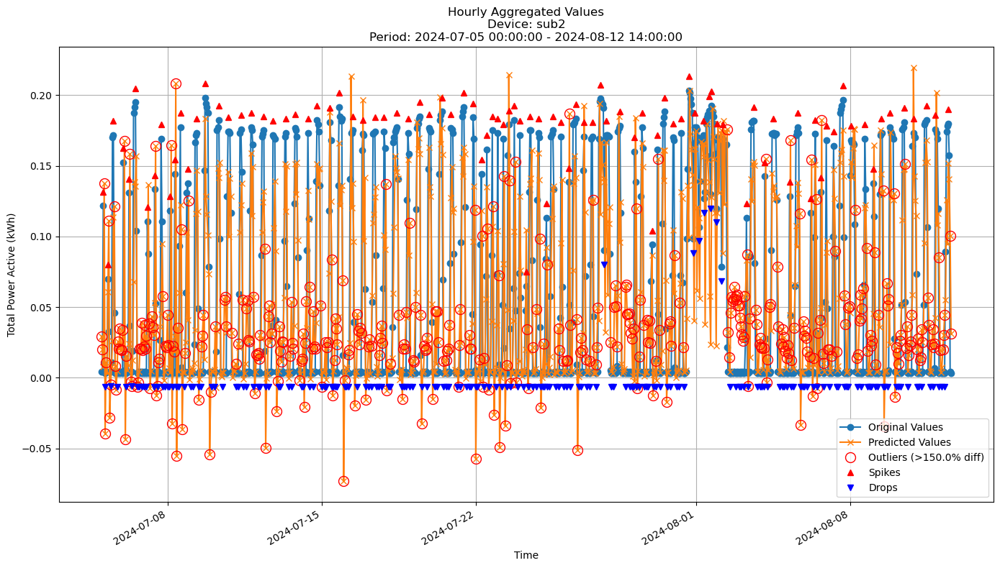


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0488
MAE: 0.0344
MAPE: 359.8878%

Directional Metrics:
Directional Accuracy: 54.5356%
First-Diff Correlation: 0.2853

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 1.0000
  Recall: 0.0054
  F1 Score: 0.0107


C:\Users\stros\AppData\Local\Temp\ipykernel_24896\2923230023.py:8: FutureWarning: The behavior of array concatenation with empty entries is deprecated. In a future version, this will no longer exclude empty items when determining the result dtype. To retain the old behavior, exclude the empty entries before the concat operation.
  y_valid = pd.concat([y_valid, rf_valid_period_predictions[device_id][i]['y_true']], axis=0)
C:\Users\stros\AppData\Local\Temp\ipykernel_24896\2923230023.py:9: FutureWarning: The behavior of array concatenation with empty entries is deprecated. In a future version, this will no longer exclude empty items when determining the result dtype. To retain the old behavior, exclude the empty entries before the concat operation.
  y_pred_valid = pd.concat([y_pred_valid, rf_valid_period_predictions[device_id][i]['y_pred']], axis=0)
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be remov

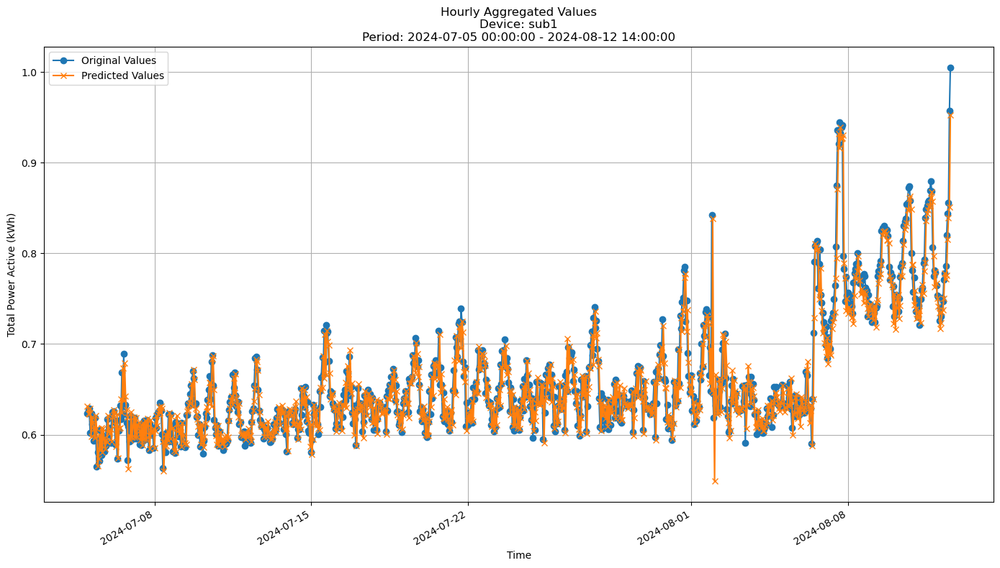


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0251
MAE: 0.0183
MAPE: 2.7670%

Directional Metrics:
Directional Accuracy: 38.1210%
First-Diff Correlation: -0.3474

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [44]:
join_periods = [-2, -1]
# Device iteration
for device_id in rf_valid_period_predictions.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, rf_valid_period_predictions[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, rf_valid_period_predictions[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid, 
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

### Hoeffding Tree

In [45]:
update_freq = "1h"  # for incremental models put the same as the data frequency to recreate real world scenario

hoef = HoeffdingTreeRegressor
# hoef_params = {
#     'grace_period': 10,
#     'delta': 0.5,
#     'max_depth': 10,
#     'tau': 0.05,
#     'leaf_prediction': 'mean'
# }
hoef_params = {'max_depth': 10,
'grace_period': 96,
'tau': 0.001,
'delta': 0.005}

In [46]:
hoef_all_train_preds, hoef_all_valid_preds, \
hoef_all_train_metrics, hoef_all_valid_metrics = all_valid_splits_seq_fit_predict(
    model_class=hoef, 
    model_params=hoef_params,
    train=train, 
    valid=valid, 
    use_residuals=USE_RESIDUAL,
    incremental=True,
    data_freq=DATA_FREQUENCY,
    forecast_horizon=FORECAST_HORIZON,
    features=ALL_FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE, 
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=1
)

Processing splits:   0%|          | 0/2 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/3 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2024-06-07 01:00:00+02:00 to 2024-07-04 23:00:00+02:00
Model's memory usage: 0.117111 MB
Metrics for Device: sub3 | Period: 2024-07-05 00:00:00+02:00 - 2024-08-01 23:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0120
	MAE: 0.0070
	MAPE: 1.6631%

Directional Metrics:
	Directional Accuracy: 50.9687%
	First-Diff Correlation: 0.1326

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.1364
		Recall: 0.1250
		F1: 0.1304
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.7727
		Recall: 0.7083
		F1: 0.7391
	Drops:
		Precision: 0.6364
		Recall: 0.5600
		F1: 0.5957
--------------------------------------------------
Daily

c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\evaluation\metrics.py:356: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  if freq_td > pd.Timedelta(C.Freq.H1):
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  return x1.resample(freq).agg(aggregation), x2.resample(freq).agg(aggregation)
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\evaluation\metrics.py:356: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  if freq_td > pd.Timedelta(C.Freq.H1):
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  return x1.resample(freq).agg(aggregation), x2.resample(f

Model's memory usage: 0.072304 MB
Metrics for Device: sub2 | Period: 2024-07-05 00:00:00+02:00 - 2024-08-01 23:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0553
	MAE: 0.0376
	MAPE: 328.9815%

Directional Metrics:
	Directional Accuracy: 48.1371%
	First-Diff Correlation: 0.1390

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.2639
		Recall: 0.2639
		F1: 0.2639
	Drops:
		Precision: 0.2113
		Recall: 0.1128
		F1: 0.1471

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.9444
		Recall: 0.9444
		F1: 0.9444
	Drops:
		Precision: 0.7324
		Recall: 0.3910
		F1: 0.5098
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.3028
	MAE: 0.2152
	MAPE: 13.6696%

Directional Metrics:
	Directional Accuracy: 88.8889%
	First-Diff Correlatio

c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\evaluation\metrics.py:356: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  if freq_td > pd.Timedelta(C.Freq.H1):
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  return x1.resample(freq).agg(aggregation), x2.resample(freq).agg(aggregation)
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\evaluation\metrics.py:356: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  if freq_td > pd.Timedelta(C.Freq.H1):
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  return x1.resample(freq).agg(aggregation), x2.resample(f

... (5 outputs left out)

Model's memory usage: 0.069687 MB
Metrics for Device: sub2 | Period: 2024-08-02 00:00:00+02:00 - 2024-08-12 14:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0513
	MAE: 0.0330
	MAPE: 257.7554%

Directional Metrics:
	Directional Accuracy: 43.3071%
	First-Diff Correlation: 0.1260

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.1304
		Recall: 0.1250
		F1: 0.1277
	Drops:
		Precision: 0.2609
		Recall: 0.1132
		F1: 0.1579

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.9565
		Recall: 0.9167
		F1: 0.9362
	Drops:
		Precision: 0.9130
		Recall: 0.3962
		F1: 0.5526
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2268
	MAE: 0.2018
	MAPE: 14.8212%

Directional Metrics:
	Directional Accuracy: 100.0000%
	First-Diff Correlati

c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\evaluation\metrics.py:356: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  if freq_td > pd.Timedelta(C.Freq.H1):
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  return x1.resample(freq).agg(aggregation), x2.resample(freq).agg(aggregation)
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\evaluation\metrics.py:356: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  if freq_td > pd.Timedelta(C.Freq.H1):
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  return x1.resample(freq).agg(aggregation), x2.resample(f

Model's memory usage: 0.154915 MB
Metrics for Device: sub1 | Period: 2024-08-02 00:00:00+02:00 - 2024-08-12 14:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0235
	MAE: 0.0162
	MAPE: 2.2604%

Directional Metrics:
	Directional Accuracy: 47.6378%
	First-Diff Correlation: 0.0265

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
	Drops:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0719
	MAE: 0.0402
	MAPE: 0.2802%

Directional Metrics:
	Directional Accuracy: 100.0000%
	First-Diff Correlation:

c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\evaluation\metrics.py:356: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  if freq_td > pd.Timedelta(C.Freq.H1):
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  return x1.resample(freq).agg(aggregation), x2.resample(freq).agg(aggregation)
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\evaluation\metrics.py:356: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  if freq_td > pd.Timedelta(C.Freq.H1):
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  return x1.resample(freq).agg(aggregation), x2.resample(f

#### Results

In [47]:
print("\n\nTrain period metrics:")
hoef_all_time_train_metrics = all_time_aggregation_metrics(hoef_all_train_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\nValid period metrics:")
hoef_all_time_valid_metrics = all_time_aggregation_metrics(hoef_all_valid_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: sub3
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.0095 ± 0.0009
	MAE: 0.0062 ± 0.0003
	MAPE: 1.6016% ± 0.0348%

	Directional Metrics:
		Directional Accuracy: 51.0060% ± 1.0060%
		First-Diff Correlation: 0.2517 ± 0.0518

	Immediate Detection (delta=0):
		Spike Precision: 0.1608 ± 0.0699
		Spike Recall: 0.1580 ± 0.0670
		Spike F1: 0.1594 ± 0.0685
		Drop Precision: 0.0693 ± 0.0216
		Drop Recall: 0.0639 ± 0.0194
		Drop F1: 0.0665 ± 0.0205

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.7197 ± 0.0530
		Spike Recall: 0.7114 ± 0.0614
		Spike F1: 0.7155 ± 0.0572
		Drop Precision: 0.7186 ± 0.0996
		Drop Recall: 0.6639 ± 0.0861
		Drop F1: 0.6902 ± 0.0925
Daily Metrics:
	RMSE: 0.0156 ± 0.0010
	MAE: 0.0116 ± 0.0004
	MAPE: 0.1264% ± 0.0069%

	Directional Metrics:
		Directional Accuracy: 99.0909% ± 0.9091%
		First-Diff Correlation: 0.9968 ± 0.0006

	Immediate Detection (delta=0):
		Spike 

#### Training plots
Plot only the last period of predictions

c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  return x1.resample(freq).agg(aggregation), x2.resample(freq).agg(aggregation)
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\evaluation\metrics.py:356: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  if freq_td > pd.Timedelta(C.Freq.H1):
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  return x1.resample(freq).agg(aggregation), x2.resample(freq).agg(aggregation)
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\evaluation\metrics.py:356: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  if freq_td > pd.

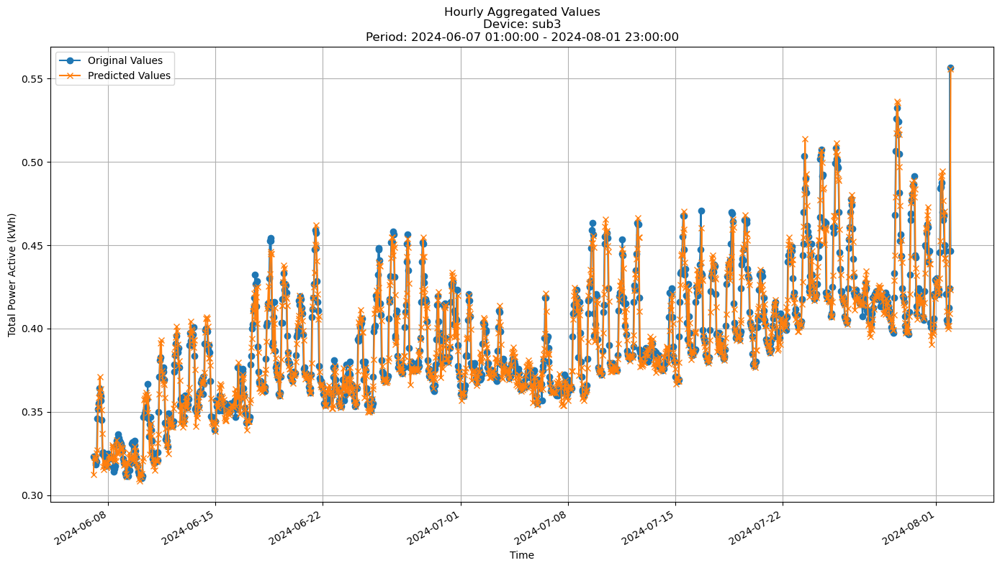


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0104
MAE: 0.0066
MAPE: 1.6364%

Directional Metrics:
Directional Accuracy: 52.0119%
First-Diff Correlation: 0.1999

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  return x1.resample(freq).agg(aggregation), x2.resample(freq).agg(aggregation)
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\evaluation\metrics.py:356: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  if freq_td > pd.Timedelta(C.Freq.H1):
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  return x1.resample(freq).agg(aggregation), x2.resample(freq).agg(aggregation)
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\evaluation\metrics.py:356: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  if freq_td > pd.

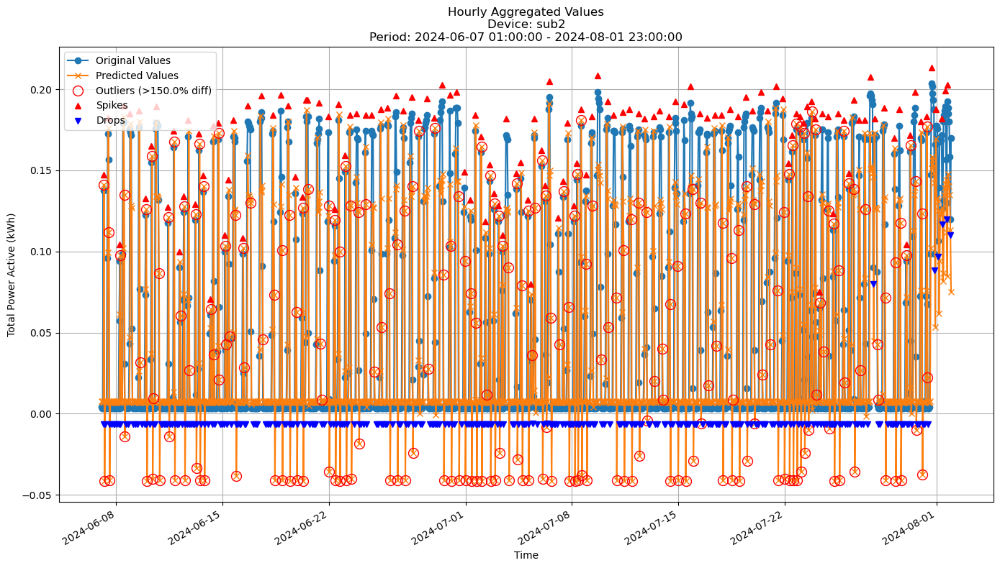


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0540
MAE: 0.0335
MAPE: 292.3146%

Directional Metrics:
Directional Accuracy: 42.3249%
First-Diff Correlation: 0.1028

Immediate Detection (delta=0):
Spikes:
  Precision: 0.1971
  Recall: 0.1971
  F1 Score: 0.1971
Drops:
  Precision: 0.1647
  Recall: 0.1033
  F1 Score: 0.1270

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.9489
  Recall: 0.9489
  F1 Score: 0.9489
Drops:
  Precision: 0.8353
  Recall: 0.5240
  F1 Score: 0.6440


c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  return x1.resample(freq).agg(aggregation), x2.resample(freq).agg(aggregation)
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\evaluation\metrics.py:356: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  if freq_td > pd.Timedelta(C.Freq.H1):
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  return x1.resample(freq).agg(aggregation), x2.resample(freq).agg(aggregation)
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\evaluation\metrics.py:356: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  if freq_td > pd.

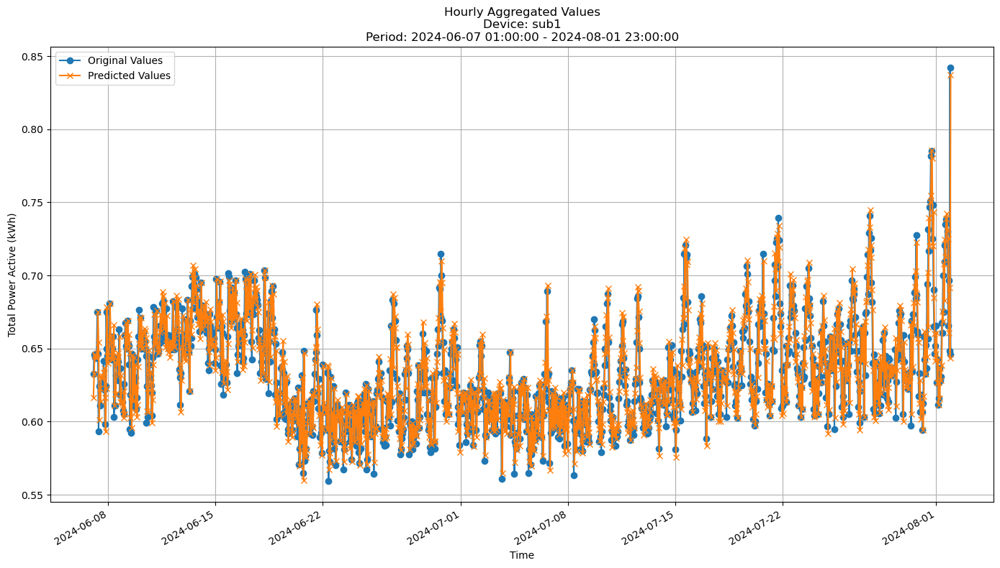


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0234
MAE: 0.0176
MAPE: 2.7799%

Directional Metrics:
Directional Accuracy: 34.1282%
First-Diff Correlation: -0.4972

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [48]:
for device_id in hoef_all_train_preds.keys():
    y_train = hoef_all_train_preds[device_id][-1]['y_true']
    y_pred_train = hoef_all_train_preds[device_id][-1]['y_pred']

    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last period of predictions

C:\Users\stros\AppData\Local\Temp\ipykernel_24896\3133680807.py:8: FutureWarning: The behavior of array concatenation with empty entries is deprecated. In a future version, this will no longer exclude empty items when determining the result dtype. To retain the old behavior, exclude the empty entries before the concat operation.
  y_valid = pd.concat([y_valid, hoef_all_valid_preds[device_id][i]['y_true']], axis=0)
C:\Users\stros\AppData\Local\Temp\ipykernel_24896\3133680807.py:9: FutureWarning: The behavior of array concatenation with empty entries is deprecated. In a future version, this will no longer exclude empty items when determining the result dtype. To retain the old behavior, exclude the empty entries before the concat operation.
  y_pred_valid = pd.concat([y_pred_valid, hoef_all_valid_preds[device_id][i]['y_pred']], axis=0)
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be removed in a future

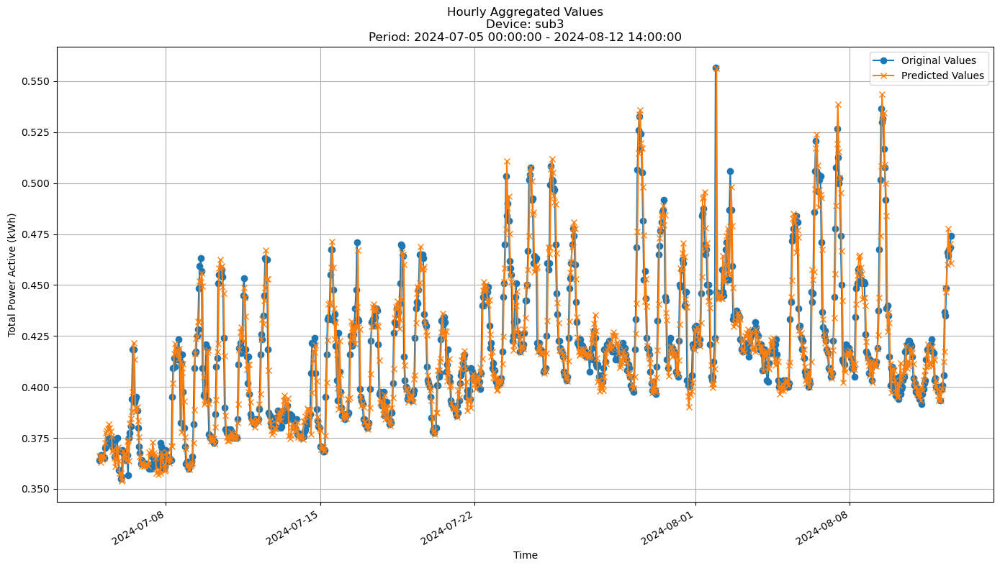


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0116
MAE: 0.0071
MAPE: 1.6457%

Directional Metrics:
Directional Accuracy: 51.1879%
First-Diff Correlation: 0.1896

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


C:\Users\stros\AppData\Local\Temp\ipykernel_24896\3133680807.py:8: FutureWarning: The behavior of array concatenation with empty entries is deprecated. In a future version, this will no longer exclude empty items when determining the result dtype. To retain the old behavior, exclude the empty entries before the concat operation.
  y_valid = pd.concat([y_valid, hoef_all_valid_preds[device_id][i]['y_true']], axis=0)
C:\Users\stros\AppData\Local\Temp\ipykernel_24896\3133680807.py:9: FutureWarning: The behavior of array concatenation with empty entries is deprecated. In a future version, this will no longer exclude empty items when determining the result dtype. To retain the old behavior, exclude the empty entries before the concat operation.
  y_pred_valid = pd.concat([y_pred_valid, hoef_all_valid_preds[device_id][i]['y_pred']], axis=0)
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be removed in a future

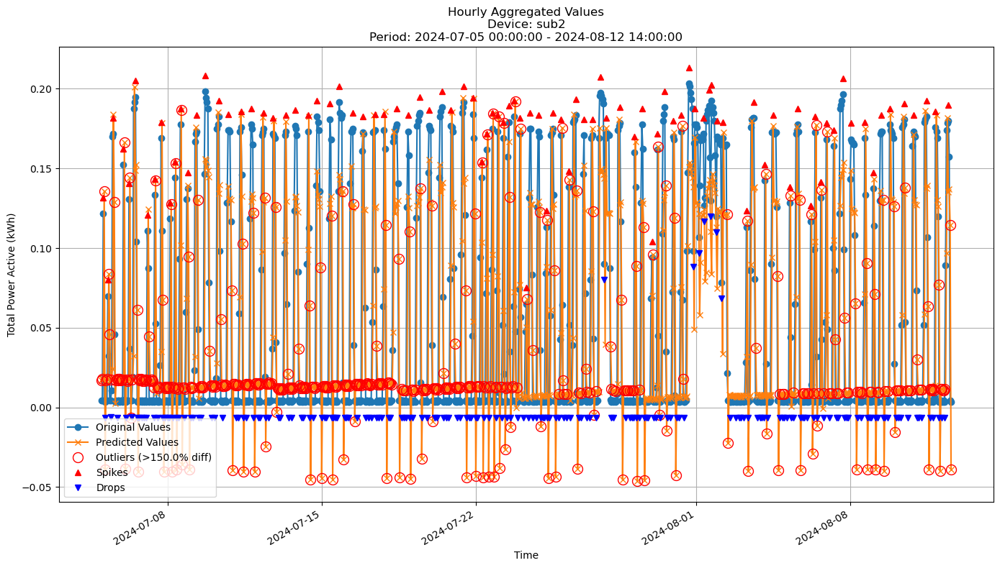


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0542
MAE: 0.0364
MAPE: 309.3886%

Directional Metrics:
Directional Accuracy: 46.7603%
First-Diff Correlation: 0.1357

Immediate Detection (delta=0):
Spikes:
  Precision: 0.2391
  Recall: 0.2292
  F1 Score: 0.2340
Drops:
  Precision: 0.2308
  Recall: 0.1129
  F1 Score: 0.1516

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.9457
  Recall: 0.9062
  F1 Score: 0.9255
Drops:
  Precision: 0.7802
  Recall: 0.3817
  F1 Score: 0.5126


C:\Users\stros\AppData\Local\Temp\ipykernel_24896\3133680807.py:8: FutureWarning: The behavior of array concatenation with empty entries is deprecated. In a future version, this will no longer exclude empty items when determining the result dtype. To retain the old behavior, exclude the empty entries before the concat operation.
  y_valid = pd.concat([y_valid, hoef_all_valid_preds[device_id][i]['y_true']], axis=0)
C:\Users\stros\AppData\Local\Temp\ipykernel_24896\3133680807.py:9: FutureWarning: The behavior of array concatenation with empty entries is deprecated. In a future version, this will no longer exclude empty items when determining the result dtype. To retain the old behavior, exclude the empty entries before the concat operation.
  y_pred_valid = pd.concat([y_pred_valid, hoef_all_valid_preds[device_id][i]['y_pred']], axis=0)
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be removed in a future

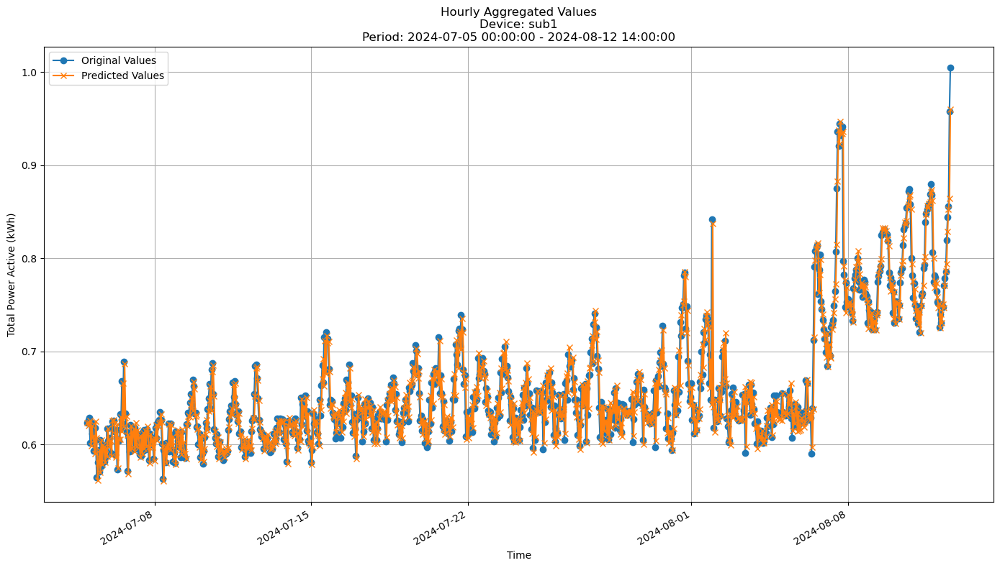


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0246
MAE: 0.0179
MAPE: 2.7182%

Directional Metrics:
Directional Accuracy: 36.0691%
First-Diff Correlation: -0.3705

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [49]:
join_periods = [-2, -1]
# Device iteration
for device_id in hoef_all_valid_preds.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, hoef_all_valid_preds[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, hoef_all_valid_preds[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid, 
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

### ARF (Hoeffding Tree)

In [50]:
update_freq = "1h"  # for incremental models put the same as the data frequency to recreate real world scenario

arf_hf = ARFRegressor
arf_hf_params = {
    'n_models': 10,
    'max_features': 0.8,
    'aggregation_method': 'median',
    'grace_period': 10,
    'max_depth': 10,
    'delta': 0.5,  # split confidence
    'tau': 0.01,  # break ties
    'seed': 42
}

In [51]:
arf_hf_all_train_preds, arf_hf_all_valid_preds, \
arf_hf_all_train_metrics, arf_hf_all_valid_metrics = all_valid_splits_seq_fit_predict(
    model_class=arf_hf,
    model_params=arf_hf_params,
    train=train,
    valid=valid,
    use_residuals=USE_RESIDUAL,
    incremental=True,
    data_freq=DATA_FREQUENCY,
    forecast_horizon=FORECAST_HORIZON,
    features=ALL_FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE,
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=1
)

Processing splits:   0%|          | 0/2 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/3 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2024-06-07 01:00:00+02:00 to 2024-07-04 23:00:00+02:00
Model's memory usage: 3.841240 MB
Metrics for Device: sub3 | Period: 2024-07-05 00:00:00+02:00 - 2024-08-01 23:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0117
	MAE: 0.0065
	MAPE: 1.5262%

Directional Metrics:
	Directional Accuracy: 51.8629%
	First-Diff Correlation: 0.1565

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.1364
		Recall: 0.1250
		F1: 0.1304
	Drops:
		Precision: 0.0455
		Recall: 0.0400
		F1: 0.0426

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.8182
		Recall: 0.7500
		F1: 0.7826
	Drops:
		Precision: 0.5909
		Recall: 0.5200
		F1: 0.5532
--------------------------------------------------
Daily

c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\evaluation\metrics.py:356: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  if freq_td > pd.Timedelta(C.Freq.H1):
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  return x1.resample(freq).agg(aggregation), x2.resample(freq).agg(aggregation)
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\evaluation\metrics.py:356: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  if freq_td > pd.Timedelta(C.Freq.H1):
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  return x1.resample(freq).agg(aggregation), x2.resample(f

Model's memory usage: 3.570671 MB
Metrics for Device: sub2 | Period: 2024-07-05 00:00:00+02:00 - 2024-08-01 23:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0562
	MAE: 0.0361
	MAPE: 340.9328%

Directional Metrics:
	Directional Accuracy: 55.4396%
	First-Diff Correlation: 0.1181

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.1216
		Recall: 0.1250
		F1: 0.1233
	Drops:
		Precision: 0.3288
		Recall: 0.1805
		F1: 0.2330

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.8649
		Recall: 0.8889
		F1: 0.8767
	Drops:
		Precision: 0.7945
		Recall: 0.4361
		F1: 0.5631
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.1343
	MAE: 0.0968
	MAPE: 6.7444%

Directional Metrics:
	Directional Accuracy: 92.5926%
	First-Diff Correlation

c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\evaluation\metrics.py:356: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  if freq_td > pd.Timedelta(C.Freq.H1):
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  return x1.resample(freq).agg(aggregation), x2.resample(freq).agg(aggregation)
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\evaluation\metrics.py:356: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  if freq_td > pd.Timedelta(C.Freq.H1):
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  return x1.resample(freq).agg(aggregation), x2.resample(f

... (5 outputs left out)

Model's memory usage: 3.861015 MB
Metrics for Device: sub2 | Period: 2024-08-02 00:00:00+02:00 - 2024-08-12 14:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0521
	MAE: 0.0330
	MAPE: 316.8548%

Directional Metrics:
	Directional Accuracy: 52.7559%
	First-Diff Correlation: 0.1052

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0769
		Recall: 0.0833
		F1: 0.0800
	Drops:
		Precision: 0.3600
		Recall: 0.1698
		F1: 0.2308

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.8077
		Recall: 0.8750
		F1: 0.8400
	Drops:
		Precision: 1.0000
		Recall: 0.4717
		F1: 0.6410
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0749
	MAE: 0.0636
	MAPE: 5.0688%

Directional Metrics:
	Directional Accuracy: 90.0000%
	First-Diff Correlation

c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\evaluation\metrics.py:356: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  if freq_td > pd.Timedelta(C.Freq.H1):
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  return x1.resample(freq).agg(aggregation), x2.resample(freq).agg(aggregation)
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\evaluation\metrics.py:356: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  if freq_td > pd.Timedelta(C.Freq.H1):
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  return x1.resample(freq).agg(aggregation), x2.resample(f

Model's memory usage: 5.286942 MB
Metrics for Device: sub1 | Period: 2024-08-02 00:00:00+02:00 - 2024-08-12 14:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0232
	MAE: 0.0160
	MAPE: 2.2359%

Directional Metrics:
	Directional Accuracy: 52.3622%
	First-Diff Correlation: 0.0549

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0773
	MAE: 0.0470
	MAPE: 0.3184%

Directional Metrics:
	Directional Accuracy: 90.0000%
	First-Diff Correlation: 

c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\evaluation\metrics.py:356: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  if freq_td > pd.Timedelta(C.Freq.H1):
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  return x1.resample(freq).agg(aggregation), x2.resample(freq).agg(aggregation)
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\evaluation\metrics.py:356: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  if freq_td > pd.Timedelta(C.Freq.H1):
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  return x1.resample(freq).agg(aggregation), x2.resample(f

#### Results

In [52]:
print("\n\nTrain period metrics:")
arf_hf_all_time_train_metrics = all_time_aggregation_metrics(arf_hf_all_train_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\Valid period metrics:")
arf_hf_all_time_valid_metrics = all_time_aggregation_metrics(arf_hf_all_valid_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: sub3
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.0087 ± 0.0010
	MAE: 0.0054 ± 0.0003
	MAPE: 1.3839% ± 0.0320%

	Directional Metrics:
		Directional Accuracy: 52.2368% ± 0.4458%
		First-Diff Correlation: 0.3144 ± 0.0753

	Immediate Detection (delta=0):
		Spike Precision: 0.0903 ± 0.0448
		Spike Recall: 0.0852 ± 0.0398
		Spike F1: 0.0877 ± 0.0422
		Drop Precision: 0.1255 ± 0.0174
		Drop Recall: 0.1069 ± 0.0181
		Drop F1: 0.1154 ± 0.0179

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.7150 ± 0.0123
		Spike Recall: 0.6886 ± 0.0386
		Spike F1: 0.7013 ± 0.0260
		Drop Precision: 0.7053 ± 0.0566
		Drop Recall: 0.6000 ± 0.0667
		Drop F1: 0.6482 ± 0.0629
Daily Metrics:
	RMSE: 0.0169 ± 0.0015
	MAE: 0.0131 ± 0.0021
	MAPE: 0.1436% ± 0.0254%

	Directional Metrics:
		Directional Accuracy: 100.0000% ± 0.0000%
		First-Diff Correlation: 0.9971 ± 0.0007

	Immediate Detection (delta=0):
		Spike

<>:3: SyntaxWarning: invalid escape sequence '\V'
<>:3: SyntaxWarning: invalid escape sequence '\V'
C:\Users\stros\AppData\Local\Temp\ipykernel_24896\3011148689.py:3: SyntaxWarning: invalid escape sequence '\V'
  print("\n\Valid period metrics:")


#### Training plots

c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  return x1.resample(freq).agg(aggregation), x2.resample(freq).agg(aggregation)
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\evaluation\metrics.py:356: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  if freq_td > pd.Timedelta(C.Freq.H1):
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  return x1.resample(freq).agg(aggregation), x2.resample(freq).agg(aggregation)
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\evaluation\metrics.py:356: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  if freq_td > pd.

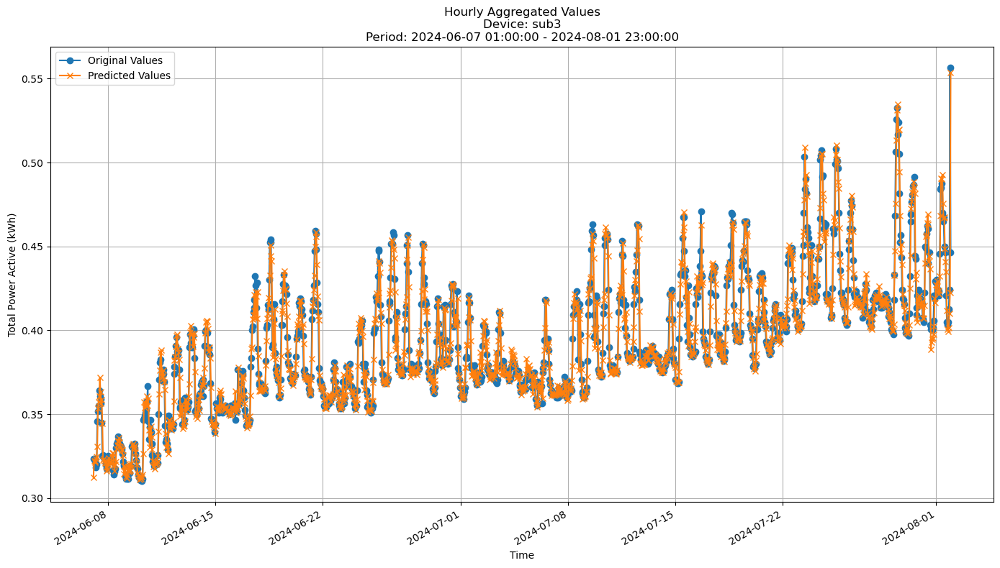


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0097
MAE: 0.0057
MAPE: 1.4158%

Directional Metrics:
Directional Accuracy: 52.6826%
First-Diff Correlation: 0.2391

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  return x1.resample(freq).agg(aggregation), x2.resample(freq).agg(aggregation)
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\evaluation\metrics.py:356: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  if freq_td > pd.Timedelta(C.Freq.H1):
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  return x1.resample(freq).agg(aggregation), x2.resample(freq).agg(aggregation)
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\evaluation\metrics.py:356: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  if freq_td > pd.

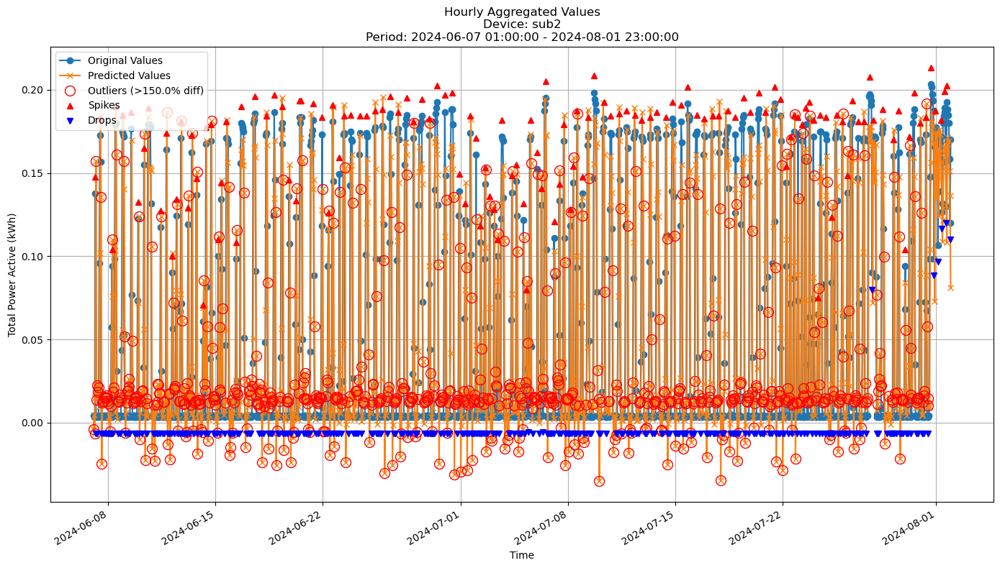


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0526
MAE: 0.0333
MAPE: 360.6463%

Directional Metrics:
Directional Accuracy: 56.3338%
First-Diff Correlation: 0.1211

Immediate Detection (delta=0):
Spikes:
  Precision: 0.1780
  Recall: 0.1533
  F1 Score: 0.1647
Drops:
  Precision: 0.3729
  Recall: 0.1624
  F1 Score: 0.2262

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.9153
  Recall: 0.7883
  F1 Score: 0.8471
Drops:
  Precision: 0.7797
  Recall: 0.3395
  F1 Score: 0.4730


c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  return x1.resample(freq).agg(aggregation), x2.resample(freq).agg(aggregation)
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\evaluation\metrics.py:356: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  if freq_td > pd.Timedelta(C.Freq.H1):
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  return x1.resample(freq).agg(aggregation), x2.resample(freq).agg(aggregation)
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\evaluation\metrics.py:356: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  if freq_td > pd.

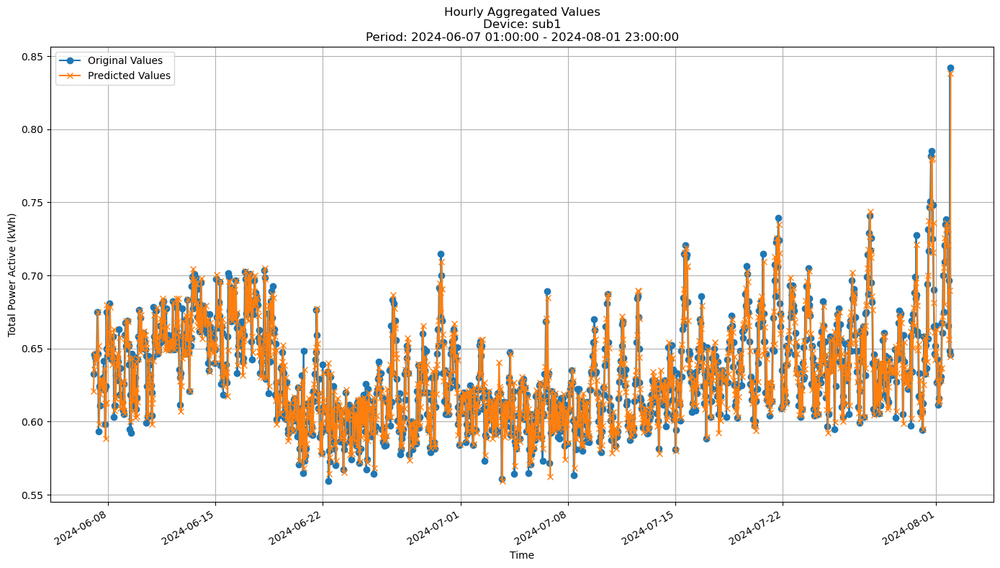


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0228
MAE: 0.0170
MAPE: 2.6843%

Directional Metrics:
Directional Accuracy: 34.2027%
First-Diff Correlation: -0.4797

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [53]:
for device_id in arf_hf_all_train_preds.keys():
    y_train = arf_hf_all_train_preds[device_id][-1]['y_true']
    y_pred_train = arf_hf_all_train_preds[device_id][-1]['y_pred']

    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train, 
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last period of predictions

C:\Users\stros\AppData\Local\Temp\ipykernel_24896\3334468469.py:8: FutureWarning: The behavior of array concatenation with empty entries is deprecated. In a future version, this will no longer exclude empty items when determining the result dtype. To retain the old behavior, exclude the empty entries before the concat operation.
  y_valid = pd.concat([y_valid, arf_hf_all_valid_preds[device_id][i]['y_true']], axis=0)
C:\Users\stros\AppData\Local\Temp\ipykernel_24896\3334468469.py:9: FutureWarning: The behavior of array concatenation with empty entries is deprecated. In a future version, this will no longer exclude empty items when determining the result dtype. To retain the old behavior, exclude the empty entries before the concat operation.
  y_pred_valid = pd.concat([y_pred_valid, arf_hf_all_valid_preds[device_id][i]['y_pred']], axis=0)
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be removed in a fu

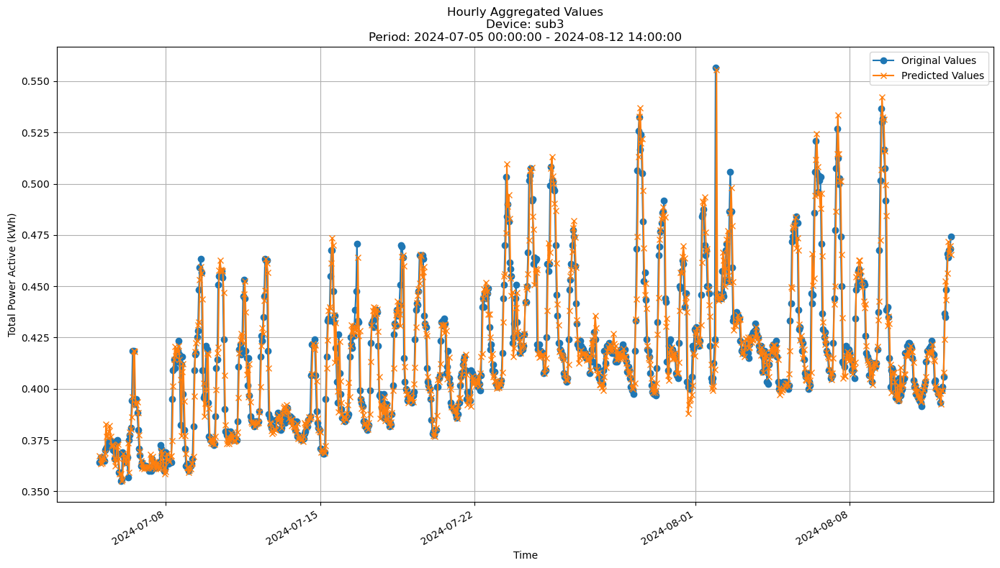


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0113
MAE: 0.0065
MAPE: 1.5106%

Directional Metrics:
Directional Accuracy: 51.8359%
First-Diff Correlation: 0.2054

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


C:\Users\stros\AppData\Local\Temp\ipykernel_24896\3334468469.py:8: FutureWarning: The behavior of array concatenation with empty entries is deprecated. In a future version, this will no longer exclude empty items when determining the result dtype. To retain the old behavior, exclude the empty entries before the concat operation.
  y_valid = pd.concat([y_valid, arf_hf_all_valid_preds[device_id][i]['y_true']], axis=0)
C:\Users\stros\AppData\Local\Temp\ipykernel_24896\3334468469.py:9: FutureWarning: The behavior of array concatenation with empty entries is deprecated. In a future version, this will no longer exclude empty items when determining the result dtype. To retain the old behavior, exclude the empty entries before the concat operation.
  y_pred_valid = pd.concat([y_pred_valid, arf_hf_all_valid_preds[device_id][i]['y_pred']], axis=0)
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be removed in a fu

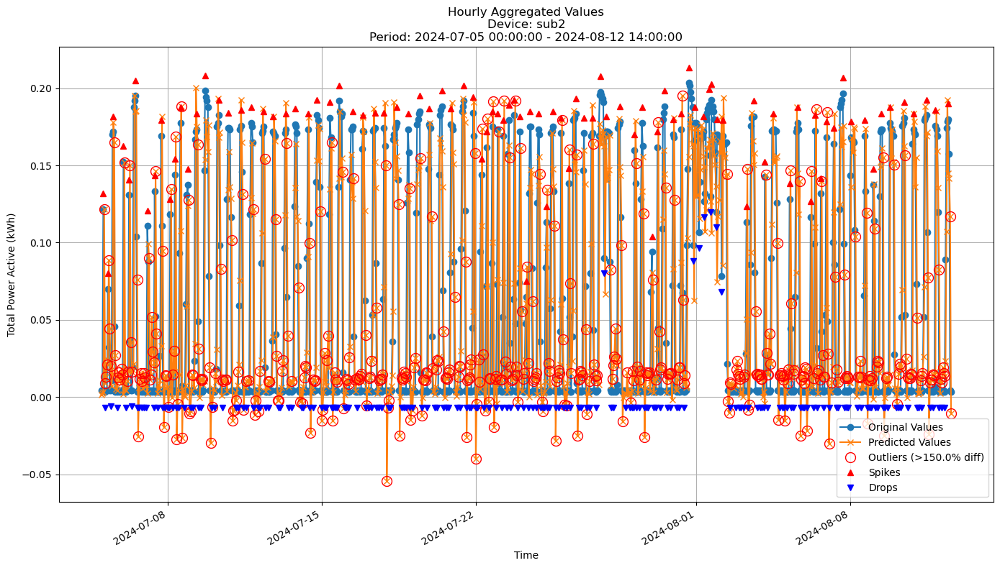


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0551
MAE: 0.0352
MAPE: 334.3094%

Directional Metrics:
Directional Accuracy: 54.6436%
First-Diff Correlation: 0.1149

Immediate Detection (delta=0):
Spikes:
  Precision: 0.1200
  Recall: 0.0938
  F1 Score: 0.1053
Drops:
  Precision: 0.3514
  Recall: 0.1398
  F1 Score: 0.2000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.9067
  Recall: 0.7083
  F1 Score: 0.7953
Drops:
  Precision: 0.8243
  Recall: 0.3280
  F1 Score: 0.4692


C:\Users\stros\AppData\Local\Temp\ipykernel_24896\3334468469.py:8: FutureWarning: The behavior of array concatenation with empty entries is deprecated. In a future version, this will no longer exclude empty items when determining the result dtype. To retain the old behavior, exclude the empty entries before the concat operation.
  y_valid = pd.concat([y_valid, arf_hf_all_valid_preds[device_id][i]['y_true']], axis=0)
C:\Users\stros\AppData\Local\Temp\ipykernel_24896\3334468469.py:9: FutureWarning: The behavior of array concatenation with empty entries is deprecated. In a future version, this will no longer exclude empty items when determining the result dtype. To retain the old behavior, exclude the empty entries before the concat operation.
  y_pred_valid = pd.concat([y_pred_valid, arf_hf_all_valid_preds[device_id][i]['y_pred']], axis=0)
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be removed in a fu

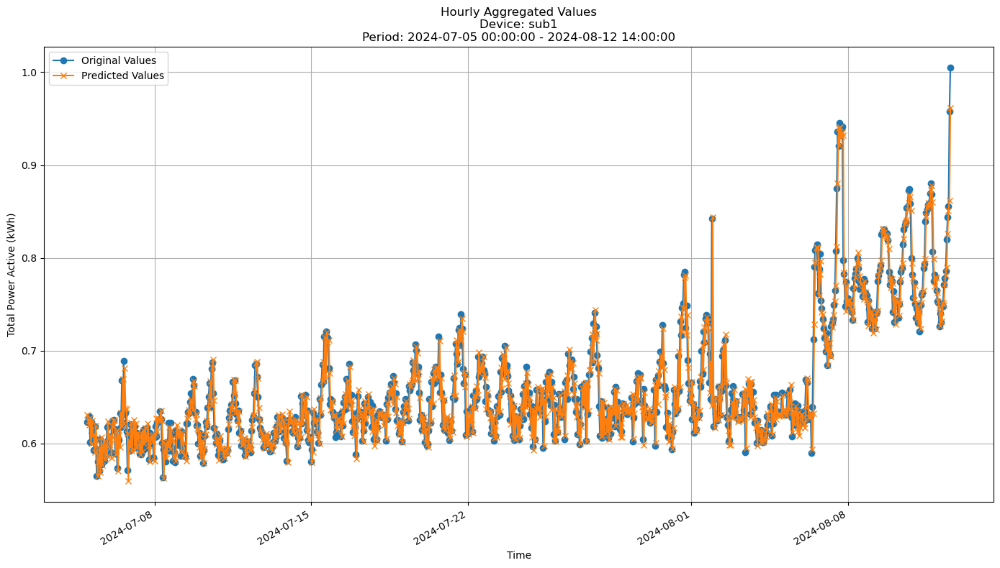


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0246
MAE: 0.0178
MAPE: 2.7124%

Directional Metrics:
Directional Accuracy: 36.7171%
First-Diff Correlation: -0.3610

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [54]:
join_periods = [-2, -1]
# Device iteration
for device_id in arf_hf_all_valid_preds.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, arf_hf_all_valid_preds[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, arf_hf_all_valid_preds[device_id][i]['y_pred']], axis=0)

    plot_hourly_predictions(y_valid,
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id,
                            outlier_threshold=1.5)

### FastODT

In [55]:
update_freq = "1h"  # for incremental models put the same as the data frequency to recreate real world scenario

fodt = fastodt.FastODT
fodt_params = {'depth': 30, 
               'grace_period': 96, 
               'grace_period_depth': 0, 
               'split_confidence': 0.1, 
               'max_feature': 0.7, 
               'tie_threshold': 0.05, 
               'bin_type': 'adaptive', 
               'max_bins': 16, 
               'split_criterion': 'vr_rel'}

In [56]:
fodt_all_train_preds, fodt_all_valid_preds, \
fodt_all_train_metrics, fodt_all_valid_metrics = all_valid_splits_seq_fit_predict(
    model_class=fodt,
    model_params=fodt_params,
    train=train, 
    valid=valid, 
    use_residuals=USE_RESIDUAL,
    incremental=True, 
    data_freq=DATA_FREQUENCY,
    forecast_horizon=FORECAST_HORIZON,
    features=ALL_FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE, 
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=1
)

Processing splits:   0%|          | 0/2 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/3 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2024-06-07 01:00:00+02:00 to 2024-07-04 23:00:00+02:00
Model's memory usage: 2.870766 MB
Metrics for Device: sub3 | Period: 2024-07-05 00:00:00+02:00 - 2024-08-01 23:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0152
	MAE: 0.0094
	MAPE: 2.2169%

Directional Metrics:
	Directional Accuracy: 52.0119%
	First-Diff Correlation: 0.0866

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.1600
		Recall: 0.1667
		F1: 0.1633
	Drops:
		Precision: 0.0833
		Recall: 0.0800
		F1: 0.0816

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.6400
		Recall: 0.6667
		F1: 0.6531
	Drops:
		Precision: 0.5000
		Recall: 0.4800
		F1: 0.4898
--------------------------------------------------
Daily

c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\evaluation\metrics.py:356: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  if freq_td > pd.Timedelta(C.Freq.H1):
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  return x1.resample(freq).agg(aggregation), x2.resample(freq).agg(aggregation)
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\evaluation\metrics.py:356: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  if freq_td > pd.Timedelta(C.Freq.H1):
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  return x1.resample(freq).agg(aggregation), x2.resample(f

Model's memory usage: 2.810989 MB
Metrics for Device: sub2 | Period: 2024-07-05 00:00:00+02:00 - 2024-08-01 23:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0678
	MAE: 0.0435
	MAPE: 531.7710%

Directional Metrics:
	Directional Accuracy: 50.6706%
	First-Diff Correlation: 0.1216

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.1786
		Recall: 0.2778
		F1: 0.2174
	Drops:
		Precision: 0.1964
		Recall: 0.1654
		F1: 0.1796

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.5357
		Recall: 0.8333
		F1: 0.6522
	Drops:
		Precision: 0.6429
		Recall: 0.5414
		F1: 0.5878
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2396
	MAE: 0.2033
	MAPE: 15.6054%

Directional Metrics:
	Directional Accuracy: 74.0741%
	First-Diff Correlatio

c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\evaluation\metrics.py:356: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  if freq_td > pd.Timedelta(C.Freq.H1):
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  return x1.resample(freq).agg(aggregation), x2.resample(freq).agg(aggregation)
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\evaluation\metrics.py:356: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  if freq_td > pd.Timedelta(C.Freq.H1):
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  return x1.resample(freq).agg(aggregation), x2.resample(f

... (5 outputs left out)

Model's memory usage: 3.636581 MB
Metrics for Device: sub2 | Period: 2024-08-02 00:00:00+02:00 - 2024-08-12 14:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0700
	MAE: 0.0446
	MAPE: 482.0653%

Directional Metrics:
	Directional Accuracy: 44.4882%
	First-Diff Correlation: 0.0795

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0600
		Recall: 0.1250
		F1: 0.0811
	Drops:
		Precision: 0.0980
		Recall: 0.0943
		F1: 0.0962

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.4600
		Recall: 0.9583
		F1: 0.6216
	Drops:
		Precision: 0.5686
		Recall: 0.5472
		F1: 0.5577
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.3023
	MAE: 0.2373
	MAPE: 19.4485%

Directional Metrics:
	Directional Accuracy: 60.0000%
	First-Diff Correlatio

c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\evaluation\metrics.py:356: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  if freq_td > pd.Timedelta(C.Freq.H1):
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  return x1.resample(freq).agg(aggregation), x2.resample(freq).agg(aggregation)
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\evaluation\metrics.py:356: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  if freq_td > pd.Timedelta(C.Freq.H1):
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  return x1.resample(freq).agg(aggregation), x2.resample(f

Model's memory usage: 3.657486 MB
Metrics for Device: sub1 | Period: 2024-08-02 00:00:00+02:00 - 2024-08-12 14:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0364
	MAE: 0.0246
	MAPE: 3.4986%

Directional Metrics:
	Directional Accuracy: 45.6693%
	First-Diff Correlation: -0.0430

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.1667
		Recall: 1.0000
		F1: 0.2857
	Drops:
		Precision: 0.1429
		Recall: 1.0000
		F1: 0.2500
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.1177
	MAE: 0.0881
	MAPE: 0.5622%

Directional Metrics:
	Directional Accuracy: 80.0000%
	First-Diff Correlation:

c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\evaluation\metrics.py:356: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  if freq_td > pd.Timedelta(C.Freq.H1):
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  return x1.resample(freq).agg(aggregation), x2.resample(freq).agg(aggregation)
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\evaluation\metrics.py:356: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  if freq_td > pd.Timedelta(C.Freq.H1):
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  return x1.resample(freq).agg(aggregation), x2.resample(f

#### Results

In [57]:
print("\n\nTrain period metrics:")
fodt_all_time_train_metrics = all_time_aggregation_metrics(fodt_all_train_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\Valid period metrics:")
fodt_all_time_valid_metrics = all_time_aggregation_metrics(fodt_all_valid_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: sub3
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.0113 ± 0.0008
	MAE: 0.0071 ± 0.0001
	MAPE: 1.8388% ± 0.0173%

	Directional Metrics:
		Directional Accuracy: 53.5426% ± 0.6365%
		First-Diff Correlation: 0.2390 ± 0.0308

	Immediate Detection (delta=0):
		Spike Precision: 0.1421 ± 0.0117
		Spike Recall: 0.1659 ± 0.0159
		Spike F1: 0.1531 ± 0.0136
		Drop Precision: 0.1177 ± 0.0361
		Drop Recall: 0.1278 ± 0.0389
		Drop F1: 0.1226 ± 0.0374

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.6204 ± 0.0334
		Spike Recall: 0.7239 ± 0.0489
		Spike F1: 0.6681 ± 0.0402
		Drop Precision: 0.5730 ± 0.0424
		Drop Recall: 0.6222 ± 0.0444
		Drop F1: 0.5966 ± 0.0434
Daily Metrics:
	RMSE: 0.0694 ± 0.0260
	MAE: 0.0583 ± 0.0241
	MAPE: 0.6501% ± 0.2883%

	Directional Metrics:
		Directional Accuracy: 97.2391% ± 0.9428%
		First-Diff Correlation: 0.9779 ± 0.0074

	Immediate Detection (delta=0):
		Spike 

<>:3: SyntaxWarning: invalid escape sequence '\V'
<>:3: SyntaxWarning: invalid escape sequence '\V'
C:\Users\stros\AppData\Local\Temp\ipykernel_24896\474330220.py:3: SyntaxWarning: invalid escape sequence '\V'
  print("\n\Valid period metrics:")


#### Training plots

c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  return x1.resample(freq).agg(aggregation), x2.resample(freq).agg(aggregation)
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\evaluation\metrics.py:356: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  if freq_td > pd.Timedelta(C.Freq.H1):
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  return x1.resample(freq).agg(aggregation), x2.resample(freq).agg(aggregation)
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\evaluation\metrics.py:356: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  if freq_td > pd.

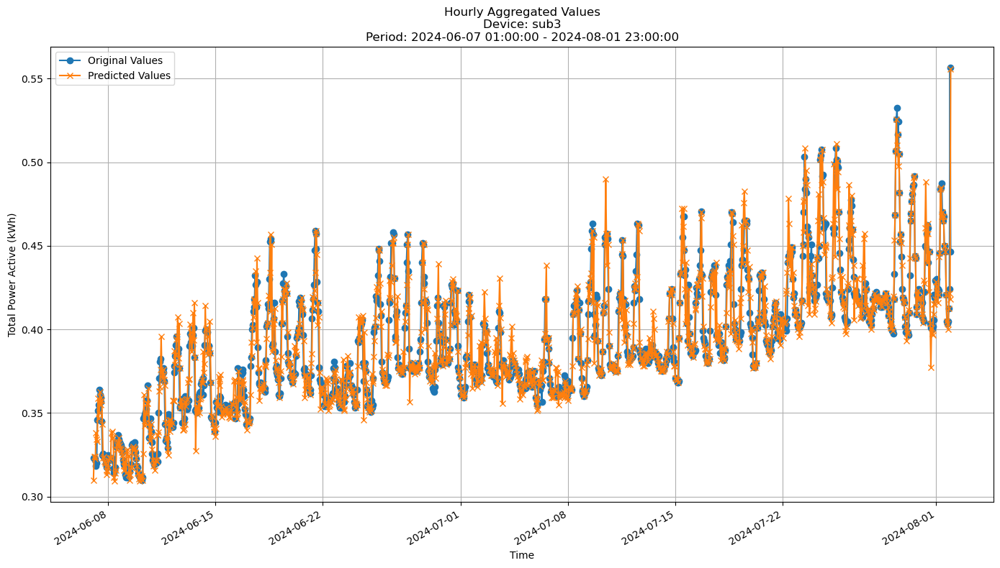


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0121
MAE: 0.0073
MAPE: 1.8215%

Directional Metrics:
Directional Accuracy: 52.9061%
First-Diff Correlation: 0.2082

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  return x1.resample(freq).agg(aggregation), x2.resample(freq).agg(aggregation)
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\evaluation\metrics.py:356: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  if freq_td > pd.Timedelta(C.Freq.H1):
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  return x1.resample(freq).agg(aggregation), x2.resample(freq).agg(aggregation)
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\evaluation\metrics.py:356: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  if freq_td > pd.

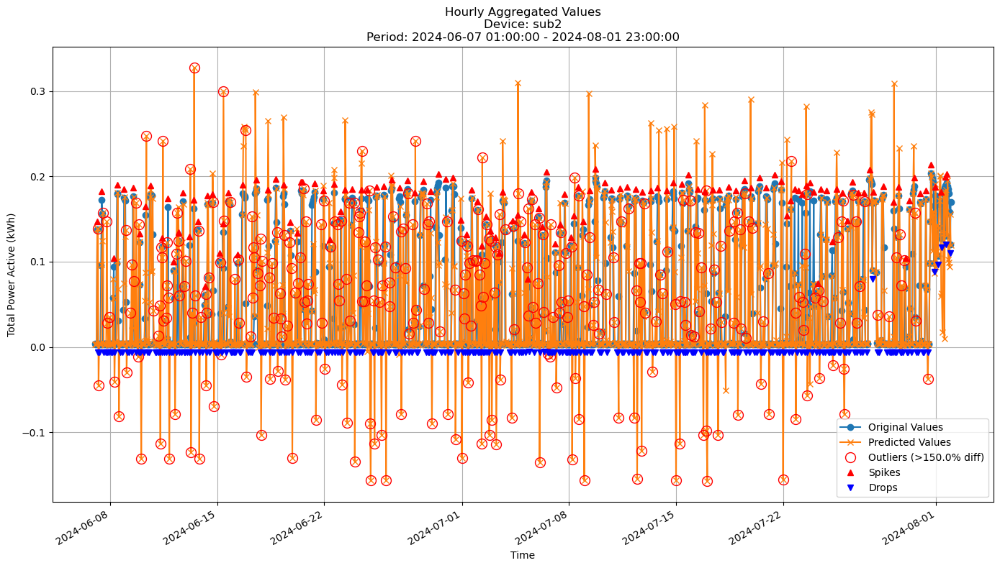


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0659
MAE: 0.0397
MAPE: 504.1829%

Directional Metrics:
Directional Accuracy: 55.2906%
First-Diff Correlation: 0.1937

Immediate Detection (delta=0):
Spikes:
  Precision: 0.3077
  Recall: 0.1460
  F1 Score: 0.1980
Drops:
  Precision: 0.3016
  Recall: 0.0701
  F1 Score: 0.1138

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.7846
  Recall: 0.3723
  F1 Score: 0.5050
Drops:
  Precision: 0.6825
  Recall: 0.1587
  F1 Score: 0.2575


c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  return x1.resample(freq).agg(aggregation), x2.resample(freq).agg(aggregation)
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\evaluation\metrics.py:356: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  if freq_td > pd.Timedelta(C.Freq.H1):
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  return x1.resample(freq).agg(aggregation), x2.resample(freq).agg(aggregation)
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\evaluation\metrics.py:356: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  if freq_td > pd.

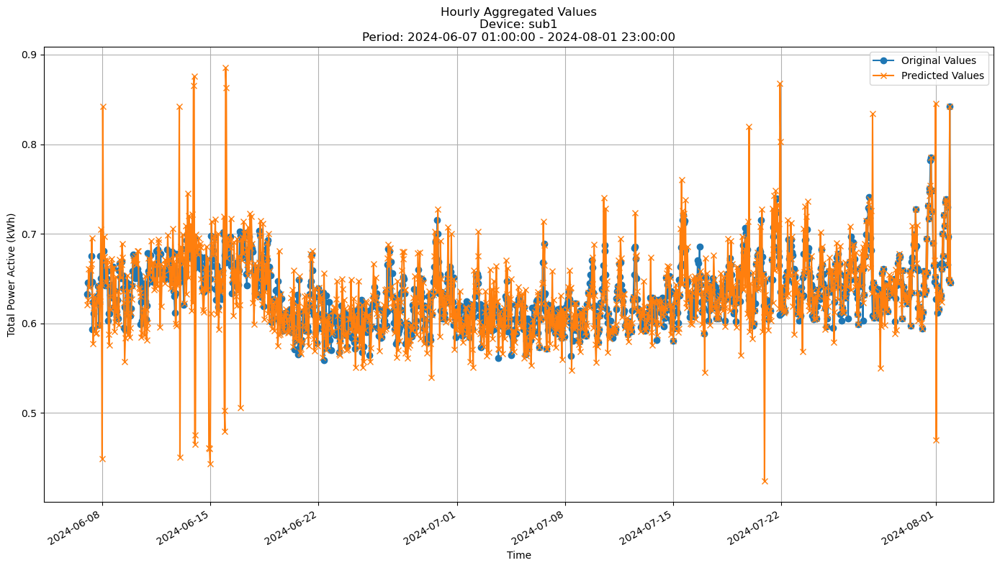


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0383
MAE: 0.0233
MAPE: 3.6544%

Directional Metrics:
Directional Accuracy: 47.7645%
First-Diff Correlation: -0.0427

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [58]:
for device_id in fodt_all_train_preds.keys():
    y_train = fodt_all_train_preds[device_id][-1]['y_true']
    y_pred_train = fodt_all_train_preds[device_id][-1]['y_pred']
    
    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train,
                            data_freq=DATA_FREQUENCY, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last period of predictions

C:\Users\stros\AppData\Local\Temp\ipykernel_24896\3986551682.py:8: FutureWarning: The behavior of array concatenation with empty entries is deprecated. In a future version, this will no longer exclude empty items when determining the result dtype. To retain the old behavior, exclude the empty entries before the concat operation.
  y_valid = pd.concat([y_valid, fodt_all_valid_preds[device_id][i]['y_true']], axis=0)
C:\Users\stros\AppData\Local\Temp\ipykernel_24896\3986551682.py:9: FutureWarning: The behavior of array concatenation with empty entries is deprecated. In a future version, this will no longer exclude empty items when determining the result dtype. To retain the old behavior, exclude the empty entries before the concat operation.
  y_pred_valid = pd.concat([y_pred_valid, fodt_all_valid_preds[device_id][i]['y_pred']], axis=0)
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be removed in a future

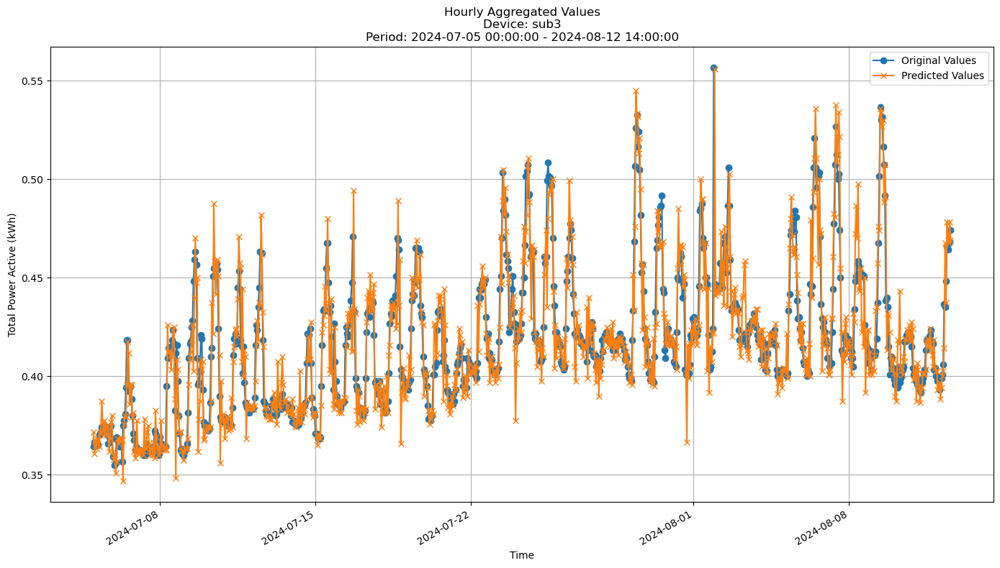


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0150
MAE: 0.0096
MAPE: 2.2481%

Directional Metrics:
Directional Accuracy: 52.0518%
First-Diff Correlation: 0.1299

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


C:\Users\stros\AppData\Local\Temp\ipykernel_24896\3986551682.py:8: FutureWarning: The behavior of array concatenation with empty entries is deprecated. In a future version, this will no longer exclude empty items when determining the result dtype. To retain the old behavior, exclude the empty entries before the concat operation.
  y_valid = pd.concat([y_valid, fodt_all_valid_preds[device_id][i]['y_true']], axis=0)
C:\Users\stros\AppData\Local\Temp\ipykernel_24896\3986551682.py:9: FutureWarning: The behavior of array concatenation with empty entries is deprecated. In a future version, this will no longer exclude empty items when determining the result dtype. To retain the old behavior, exclude the empty entries before the concat operation.
  y_pred_valid = pd.concat([y_pred_valid, fodt_all_valid_preds[device_id][i]['y_pred']], axis=0)
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be removed in a future

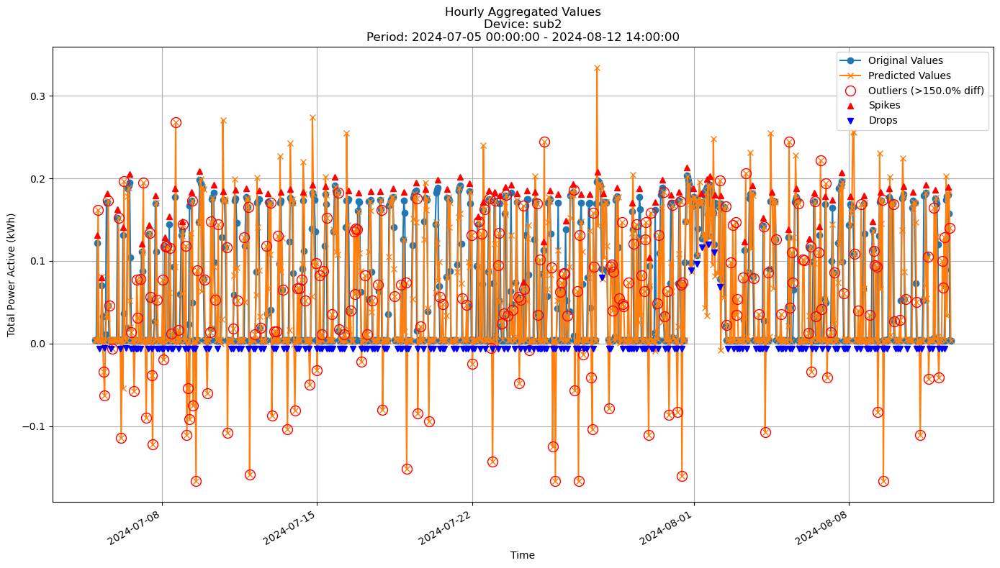


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0684
MAE: 0.0438
MAPE: 518.0979%

Directional Metrics:
Directional Accuracy: 48.9201%
First-Diff Correlation: 0.1104

Immediate Detection (delta=0):
Spikes:
  Precision: 0.2500
  Recall: 0.0625
  F1 Score: 0.1000
Drops:
  Precision: 0.2800
  Recall: 0.0376
  F1 Score: 0.0664

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.8333
  Recall: 0.2083
  F1 Score: 0.3333
Drops:
  Precision: 0.8000
  Recall: 0.1075
  F1 Score: 0.1896


C:\Users\stros\AppData\Local\Temp\ipykernel_24896\3986551682.py:8: FutureWarning: The behavior of array concatenation with empty entries is deprecated. In a future version, this will no longer exclude empty items when determining the result dtype. To retain the old behavior, exclude the empty entries before the concat operation.
  y_valid = pd.concat([y_valid, fodt_all_valid_preds[device_id][i]['y_true']], axis=0)
C:\Users\stros\AppData\Local\Temp\ipykernel_24896\3986551682.py:9: FutureWarning: The behavior of array concatenation with empty entries is deprecated. In a future version, this will no longer exclude empty items when determining the result dtype. To retain the old behavior, exclude the empty entries before the concat operation.
  y_pred_valid = pd.concat([y_pred_valid, fodt_all_valid_preds[device_id][i]['y_pred']], axis=0)
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be removed in a future

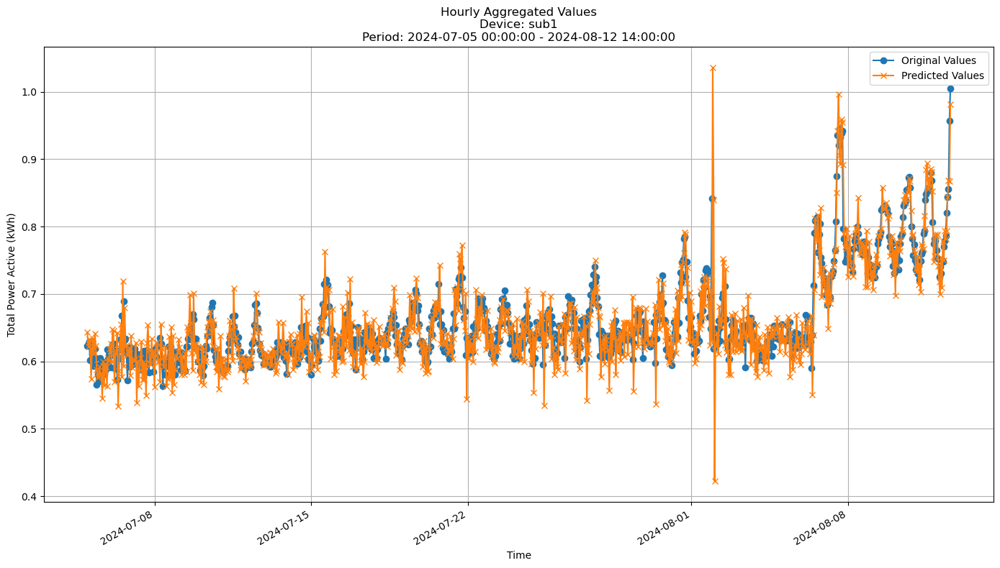


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0365
MAE: 0.0253
MAPE: 3.8541%

Directional Metrics:
Directional Accuracy: 39.3089%
First-Diff Correlation: -0.3335

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [59]:
join_periods = [-2, -1]
# Device iteration
for device_id in fodt_all_valid_preds.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, fodt_all_valid_preds[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, fodt_all_valid_preds[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid, 
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

### ARF (FastODT)

In [60]:
update_freq = "1h"  # for incremental models put the same as the data frequency to recreate real world scenario

arf = ARFRegressorFODT

arf_params = {
    'n_models': 5, 
    'max_features': 0.5, 
    'max_depth': 30, 
    'aggregation_method': 'mean', 
    'disable_weighted_vote': True, 
    # 'drift_detector': None, 
    # 'warning_detector': None, 
    'eagerness': 0, 
    'tau': 0.05, 
    'delta': 0.05, 
    'grace_period': 96, 
    'grace_period_depth': 0, 
    'bin_type': 'mean', 
    'split_criterion': 'vr_rel'}

# {'depth': 30, 
#                'grace_period': 96, 
#                'grace_period_depth': 0, 
#                'split_confidence': 0.1, 
#                'max_feature': 0.7, 
#                'tie_threshold': 0.05, 
#                'bin_type': 'adaptive', 
#                'max_bins': 16, 
#                'split_criterion': 'vr_rel'}

# arf_params = {
#     "n_models": 20,
#     "aggregation_method": "mean",
#     "grace_period": 0,  # by default works for all leaves
#     "max_depth": 100,
#     "delta": 0.1,  # split confidence
#     "tau": 0.01,  # break ties
#     "seed": 42,
#     "max_features": 0.7,  # maximum feature ratio for each model
# }

In [61]:
arf_all_train_preds, arf_all_valid_preds, \
arf_all_train_metrics, arf_all_valid_metrics = all_valid_splits_seq_fit_predict(
    model_class=arf,
    model_params=arf_params,
    train=train,
    valid=valid,
    use_residuals=USE_RESIDUAL,
    incremental=True,
    data_freq=DATA_FREQUENCY,
    forecast_horizon=FORECAST_HORIZON,
    features=ALL_FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE,
    start_split=0,
    #end_split=4,  # Use only the third and fourth splits
    verbose=1
)

Processing splits:   0%|          | 0/2 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/3 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2024-06-07 01:00:00+02:00 to 2024-07-04 23:00:00+02:00
Model's memory usage: 15.118965 MB
Metrics for Device: sub3 | Period: 2024-07-05 00:00:00+02:00 - 2024-08-01 23:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0143
	MAE: 0.0087
	MAPE: 2.0533%

Directional Metrics:
	Directional Accuracy: 51.2668%
	First-Diff Correlation: 0.1285

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.1200
		Recall: 0.1250
		F1: 0.1224
	Drops:
		Precision: 0.1154
		Recall: 0.1200
		F1: 0.1176

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.6000
		Recall: 0.6250
		F1: 0.6122
	Drops:
		Precision: 0.3846
		Recall: 0.4000
		F1: 0.3922
--------------------------------------------------
Dail

c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\evaluation\metrics.py:356: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  if freq_td > pd.Timedelta(C.Freq.H1):
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  return x1.resample(freq).agg(aggregation), x2.resample(freq).agg(aggregation)
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\evaluation\metrics.py:356: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  if freq_td > pd.Timedelta(C.Freq.H1):
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  return x1.resample(freq).agg(aggregation), x2.resample(f

Model's memory usage: 20.992683 MB
Metrics for Device: sub2 | Period: 2024-07-05 00:00:00+02:00 - 2024-08-01 23:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0639
	MAE: 0.0447
	MAPE: 542.7285%

Directional Metrics:
	Directional Accuracy: 55.4396%
	First-Diff Correlation: 0.1473

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.2110
		Recall: 0.3194
		F1: 0.2541
	Drops:
		Precision: 0.2407
		Recall: 0.1955
		F1: 0.2158

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.5780
		Recall: 0.8750
		F1: 0.6961
	Drops:
		Precision: 0.6759
		Recall: 0.5489
		F1: 0.6058
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2332
	MAE: 0.1712
	MAPE: 12.2471%

Directional Metrics:
	Directional Accuracy: 66.6667%
	First-Diff Correlati

c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\evaluation\metrics.py:356: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  if freq_td > pd.Timedelta(C.Freq.H1):
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  return x1.resample(freq).agg(aggregation), x2.resample(freq).agg(aggregation)
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\evaluation\metrics.py:356: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  if freq_td > pd.Timedelta(C.Freq.H1):
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  return x1.resample(freq).agg(aggregation), x2.resample(f

... (5 outputs left out)

Model's memory usage: 25.319817 MB
Metrics for Device: sub2 | Period: 2024-08-02 00:00:00+02:00 - 2024-08-12 14:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0662
	MAE: 0.0426
	MAPE: 515.2935%

Directional Metrics:
	Directional Accuracy: 50.3937%
	First-Diff Correlation: 0.0613

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0667
		Recall: 0.1250
		F1: 0.0870
	Drops:
		Precision: 0.3556
		Recall: 0.3019
		F1: 0.3265

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.4889
		Recall: 0.9167
		F1: 0.6377
	Drops:
		Precision: 0.6889
		Recall: 0.5849
		F1: 0.6327
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2355
	MAE: 0.2001
	MAPE: 15.7626%

Directional Metrics:
	Directional Accuracy: 60.0000%
	First-Diff Correlati

c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\evaluation\metrics.py:356: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  if freq_td > pd.Timedelta(C.Freq.H1):
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  return x1.resample(freq).agg(aggregation), x2.resample(freq).agg(aggregation)
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\evaluation\metrics.py:356: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  if freq_td > pd.Timedelta(C.Freq.H1):
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  return x1.resample(freq).agg(aggregation), x2.resample(f

Model's memory usage: 16.792511 MB
Metrics for Device: sub1 | Period: 2024-08-02 00:00:00+02:00 - 2024-08-12 14:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0343
	MAE: 0.0238
	MAPE: 3.3183%

Directional Metrics:
	Directional Accuracy: 45.2756%
	First-Diff Correlation: -0.0023

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.2000
		Recall: 1.0000
		F1: 0.3333
	Drops:
		Precision: 0.1667
		Recall: 1.0000
		F1: 0.2857
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.1253
	MAE: 0.1057
	MAPE: 0.6537%

Directional Metrics:
	Directional Accuracy: 100.0000%
	First-Diff Correlatio

c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\evaluation\metrics.py:356: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  if freq_td > pd.Timedelta(C.Freq.H1):
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  return x1.resample(freq).agg(aggregation), x2.resample(freq).agg(aggregation)
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\evaluation\metrics.py:356: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  if freq_td > pd.Timedelta(C.Freq.H1):
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  return x1.resample(freq).agg(aggregation), x2.resample(f

#### Results

In [62]:
print("\n\nTrain period metrics:")
arf_all_time_train_metrics = all_time_aggregation_metrics(arf_all_train_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\Valid period metrics:")
arf_all_time_valid_metrics = all_time_aggregation_metrics(arf_all_valid_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: sub3
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.0140 ± 0.0034
	MAE: 0.0079 ± 0.0009
	MAPE: 2.0385% ± 0.1896%

	Directional Metrics:
		Directional Accuracy: 52.7950% ± 1.8995%
		First-Diff Correlation: 0.2113 ± 0.0091

	Immediate Detection (delta=0):
		Spike Precision: 0.2383 ± 0.0383
		Spike Recall: 0.2761 ± 0.0489
		Spike F1: 0.2558 ± 0.0430
		Drop Precision: 0.1051 ± 0.0199
		Drop Recall: 0.1069 ± 0.0181
		Drop F1: 0.1060 ± 0.0190

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.5566 ± 0.0034
		Spike Recall: 0.6432 ± 0.0068
		Spike F1: 0.5967 ± 0.0010
		Drop Precision: 0.4619 ± 0.1215
		Drop Recall: 0.4694 ± 0.1139
		Drop F1: 0.4656 ± 0.1178
Daily Metrics:
	RMSE: 0.0289 ± 0.0032
	MAE: 0.0219 ± 0.0010
	MAPE: 0.2416% ± 0.0025%

	Directional Metrics:
		Directional Accuracy: 96.3300% ± 0.0337%
		First-Diff Correlation: 0.9896 ± 0.0018

	Immediate Detection (delta=0):
		Spike 

<>:3: SyntaxWarning: invalid escape sequence '\V'
<>:3: SyntaxWarning: invalid escape sequence '\V'
C:\Users\stros\AppData\Local\Temp\ipykernel_24896\3741900594.py:3: SyntaxWarning: invalid escape sequence '\V'
  print("\n\Valid period metrics:")


#### Training plots

c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  return x1.resample(freq).agg(aggregation), x2.resample(freq).agg(aggregation)
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\evaluation\metrics.py:356: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  if freq_td > pd.Timedelta(C.Freq.H1):
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  return x1.resample(freq).agg(aggregation), x2.resample(freq).agg(aggregation)
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\evaluation\metrics.py:356: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  if freq_td > pd.

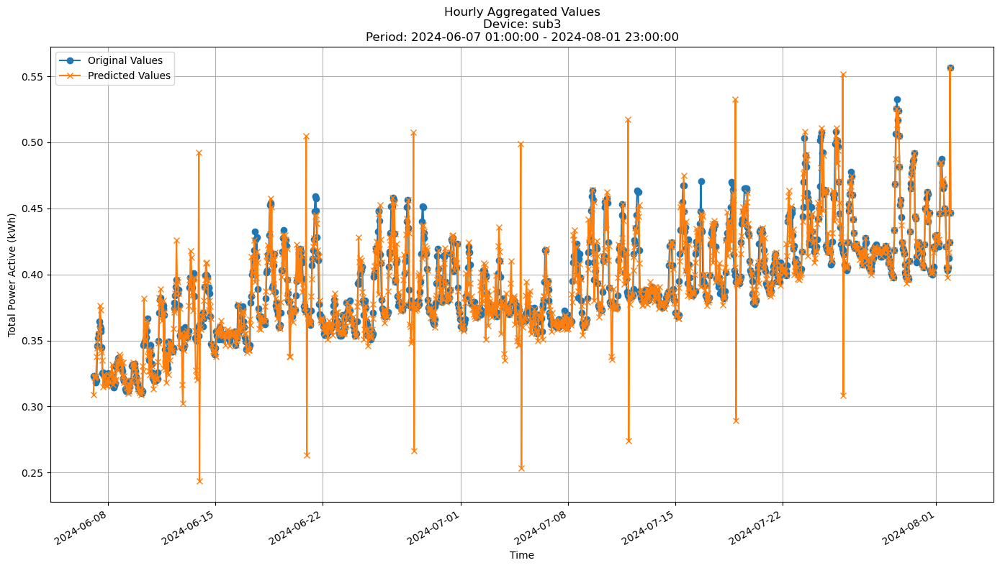


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0174
MAE: 0.0088
MAPE: 2.2281%

Directional Metrics:
Directional Accuracy: 54.6945%
First-Diff Correlation: 0.2022

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  return x1.resample(freq).agg(aggregation), x2.resample(freq).agg(aggregation)
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\evaluation\metrics.py:356: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  if freq_td > pd.Timedelta(C.Freq.H1):
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  return x1.resample(freq).agg(aggregation), x2.resample(freq).agg(aggregation)
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\evaluation\metrics.py:356: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  if freq_td > pd.

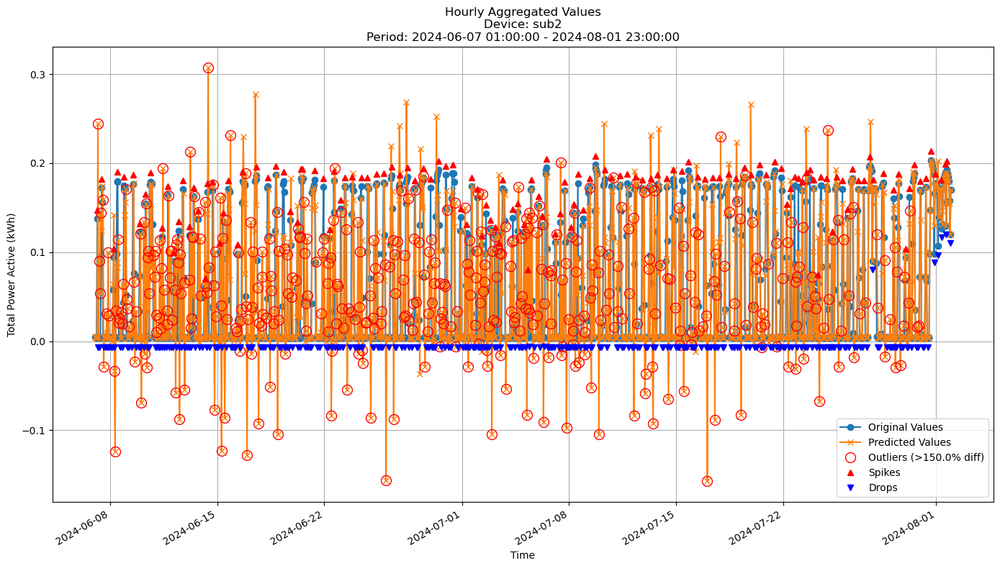


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0599
MAE: 0.0373
MAPE: 521.4090%

Directional Metrics:
Directional Accuracy: 55.2161%
First-Diff Correlation: 0.1643

Immediate Detection (delta=0):
Spikes:
  Precision: 0.1250
  Recall: 0.0292
  F1 Score: 0.0473
Drops:
  Precision: 0.1613
  Recall: 0.0185
  F1 Score: 0.0331

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.6250
  Recall: 0.1460
  F1 Score: 0.2367
Drops:
  Precision: 0.5161
  Recall: 0.0590
  F1 Score: 0.1060


c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  return x1.resample(freq).agg(aggregation), x2.resample(freq).agg(aggregation)
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\evaluation\metrics.py:356: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  if freq_td > pd.Timedelta(C.Freq.H1):
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  return x1.resample(freq).agg(aggregation), x2.resample(freq).agg(aggregation)
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\evaluation\metrics.py:356: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  if freq_td > pd.

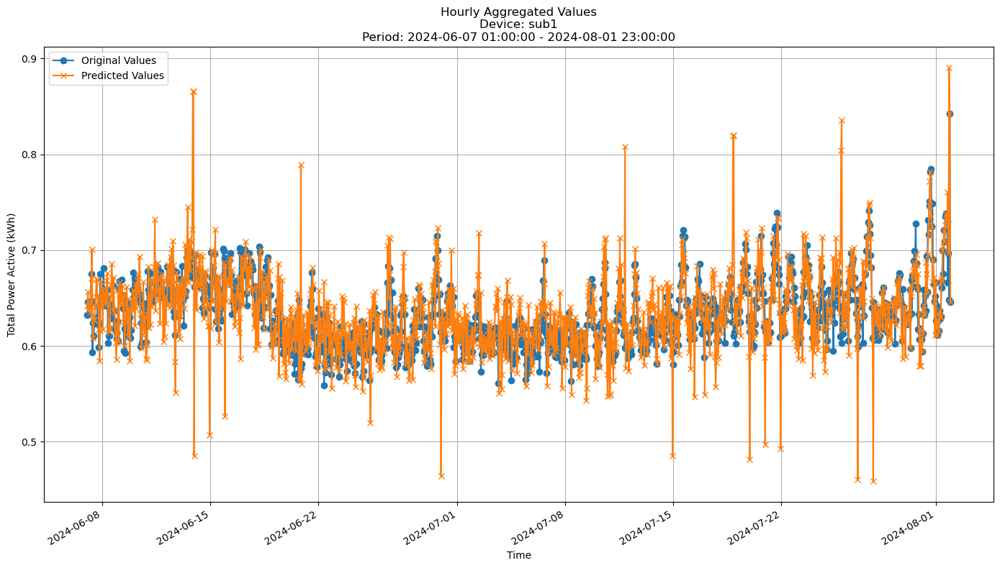


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0359
MAE: 0.0241
MAPE: 3.8272%

Directional Metrics:
Directional Accuracy: 40.6110%
First-Diff Correlation: -0.1969

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [63]:
for device_id in arf_all_train_preds.keys():
    y_train = arf_all_train_preds[device_id][-1]['y_true']
    y_pred_train = arf_all_train_preds[device_id][-1]['y_pred']

    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train, 
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last period of predictions

C:\Users\stros\AppData\Local\Temp\ipykernel_24896\3061694740.py:8: FutureWarning: The behavior of array concatenation with empty entries is deprecated. In a future version, this will no longer exclude empty items when determining the result dtype. To retain the old behavior, exclude the empty entries before the concat operation.
  y_valid = pd.concat([y_valid, arf_all_valid_preds[device_id][i]['y_true']], axis=0)
C:\Users\stros\AppData\Local\Temp\ipykernel_24896\3061694740.py:9: FutureWarning: The behavior of array concatenation with empty entries is deprecated. In a future version, this will no longer exclude empty items when determining the result dtype. To retain the old behavior, exclude the empty entries before the concat operation.
  y_pred_valid = pd.concat([y_pred_valid, arf_all_valid_preds[device_id][i]['y_pred']], axis=0)
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be removed in a future v

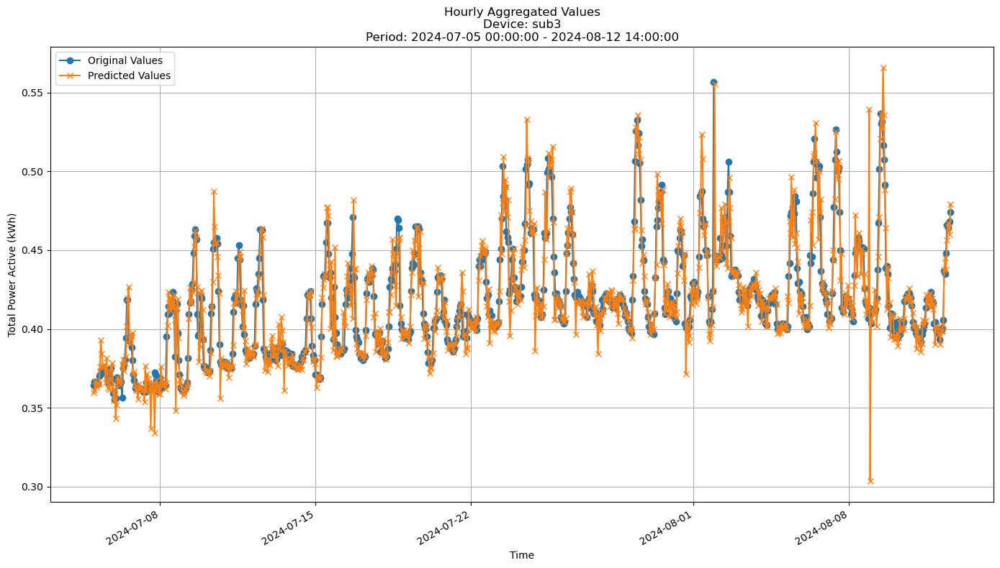


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0149
MAE: 0.0088
MAPE: 2.0535%

Directional Metrics:
Directional Accuracy: 51.5119%
First-Diff Correlation: 0.1517

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


C:\Users\stros\AppData\Local\Temp\ipykernel_24896\3061694740.py:8: FutureWarning: The behavior of array concatenation with empty entries is deprecated. In a future version, this will no longer exclude empty items when determining the result dtype. To retain the old behavior, exclude the empty entries before the concat operation.
  y_valid = pd.concat([y_valid, arf_all_valid_preds[device_id][i]['y_true']], axis=0)
C:\Users\stros\AppData\Local\Temp\ipykernel_24896\3061694740.py:9: FutureWarning: The behavior of array concatenation with empty entries is deprecated. In a future version, this will no longer exclude empty items when determining the result dtype. To retain the old behavior, exclude the empty entries before the concat operation.
  y_pred_valid = pd.concat([y_pred_valid, arf_all_valid_preds[device_id][i]['y_pred']], axis=0)
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be removed in a future v

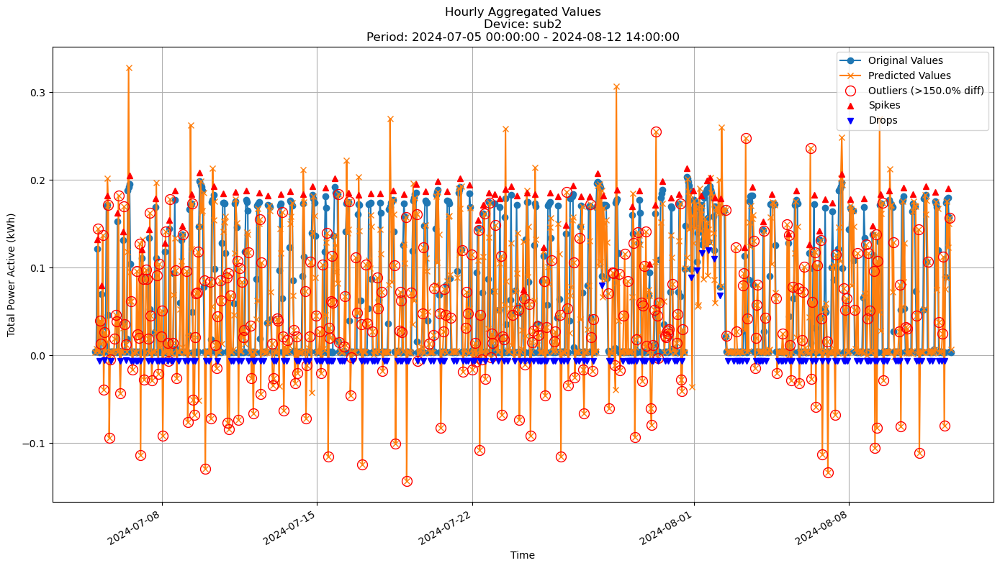


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0645
MAE: 0.0441
MAPE: 535.1817%

Directional Metrics:
Directional Accuracy: 53.9957%
First-Diff Correlation: 0.1244

Immediate Detection (delta=0):
Spikes:
  Precision: 0.2000
  Recall: 0.0208
  F1 Score: 0.0377
Drops:
  Precision: 0.4444
  Recall: 0.0215
  F1 Score: 0.0410

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.8000
  Recall: 0.0833
  F1 Score: 0.1509
Drops:
  Precision: 1.0000
  Recall: 0.0484
  F1 Score: 0.0923


C:\Users\stros\AppData\Local\Temp\ipykernel_24896\3061694740.py:8: FutureWarning: The behavior of array concatenation with empty entries is deprecated. In a future version, this will no longer exclude empty items when determining the result dtype. To retain the old behavior, exclude the empty entries before the concat operation.
  y_valid = pd.concat([y_valid, arf_all_valid_preds[device_id][i]['y_true']], axis=0)
C:\Users\stros\AppData\Local\Temp\ipykernel_24896\3061694740.py:9: FutureWarning: The behavior of array concatenation with empty entries is deprecated. In a future version, this will no longer exclude empty items when determining the result dtype. To retain the old behavior, exclude the empty entries before the concat operation.
  y_pred_valid = pd.concat([y_pred_valid, arf_all_valid_preds[device_id][i]['y_pred']], axis=0)
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be removed in a future v

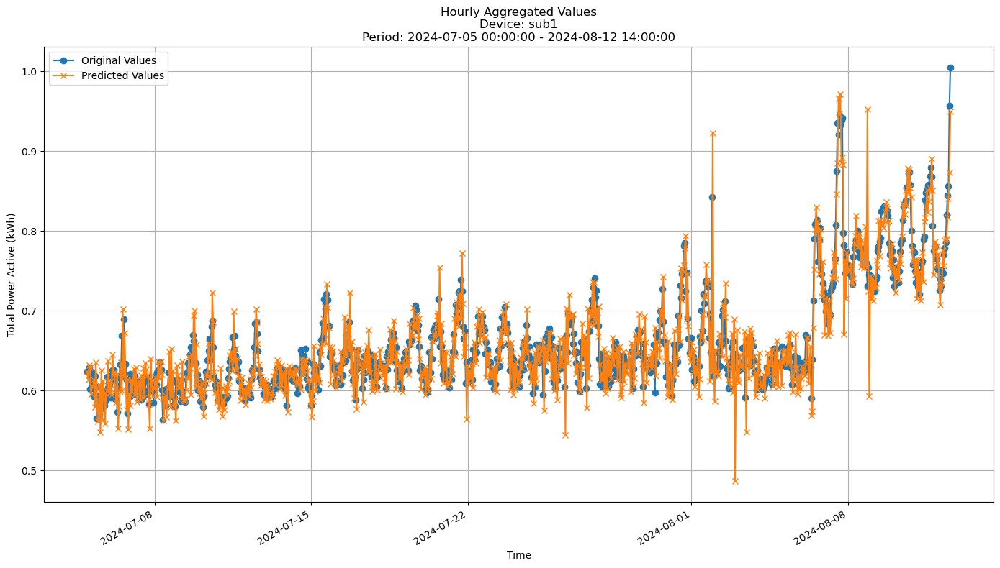


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0320
MAE: 0.0229
MAPE: 3.4703%

Directional Metrics:
Directional Accuracy: 37.5810%
First-Diff Correlation: -0.2893

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [64]:
join_periods = [-2, -1]
# Device iteration
for device_id in arf_all_valid_preds.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, arf_all_valid_preds[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, arf_all_valid_preds[device_id][i]['y_pred']], axis=0)

    plot_hourly_predictions(y_valid,
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id,
                            outlier_threshold=1.5)

### iNcubation Boost

In [102]:
update_freq = "1h"  # for incremental models put the same as the data frequency to recreate real world scenario:

incb = IncubationBoost

incb_params = {
    'length': 40, 
    'learning_rate': 0.5, 
    'depth': 10, 
    'grace_period': 0, 
    'grace_period_depth': 1, 
    'split_confidence': 0.05, 
    'max_feature': 1.0, 
    'tie_threshold': 0.01, 
    'bin_type': 'adaptive', 
    'max_bins': 16, 
    'split_criterion': 'vr_rel', 
    'verbose': False}


In [103]:
incb_all_train_preds, incb_all_valid_preds, \
incb_all_train_metrics, incb_all_valid_metrics = all_valid_splits_seq_fit_predict(
    model_class=incb, 
    model_params=incb_params,
    train=train, 
    valid=valid, 
    use_residuals=USE_RESIDUAL,
    incremental=True, 
    data_freq=DATA_FREQUENCY,
    forecast_horizon=FORECAST_HORIZON,
    features=ALL_FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE, 
    start_split=0, 
    # end_split=1,  # Use only the third and fourth splits
    verbose=1
)

Processing splits:   0%|          | 0/2 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/3 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2024-06-07 01:00:00+02:00 to 2024-07-04 23:00:00+02:00


c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\boosting.py:143: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  self._partial_fit(X[i], y[i])


Model's memory usage: 0.367485 MB
Metrics for Device: sub3 | Period: 2024-07-05 00:00:00+02:00 - 2024-08-01 23:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0147
	MAE: 0.0087
	MAPE: 2.0794%

Directional Metrics:
	Directional Accuracy: 50.9687%
	First-Diff Correlation: 0.0996

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.1667
		Recall: 0.1667
		F1: 0.1667
	Drops:
		Precision: 0.1250
		Recall: 0.1200
		F1: 0.1224

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.7917
		Recall: 0.7917
		F1: 0.7917
	Drops:
		Precision: 0.6667
		Recall: 0.6400
		F1: 0.6531
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0758
	MAE: 0.0753
	MAPE: 0.7660%

Directional Metrics:
	Directional Accuracy: 100.0000%
	First-Diff Correlation:

c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\evaluation\metrics.py:356: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  if freq_td > pd.Timedelta(C.Freq.H1):
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  return x1.resample(freq).agg(aggregation), x2.resample(freq).agg(aggregation)
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\evaluation\metrics.py:356: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  if freq_td > pd.Timedelta(C.Freq.H1):
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  return x1.resample(freq).agg(aggregation), x2.resample(f

... (9 outputs left out)

Model's memory usage: 0.436386 MB
Metrics for Device: sub2 | Period: 2024-08-02 00:00:00+02:00 - 2024-08-12 14:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.1405
	MAE: 0.0879
	MAPE: 1245.3638%

Directional Metrics:
	Directional Accuracy: 46.0630%
	First-Diff Correlation: 0.0976

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.1000
		Recall: 0.1250
		F1: 0.1111
	Drops:
		Precision: 0.0645
		Recall: 0.0377
		F1: 0.0476

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.6333
		Recall: 0.7917
		F1: 0.7037
	Drops:
		Precision: 0.6452
		Recall: 0.3774
		F1: 0.4762
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2137
	MAE: 0.1941
	MAPE: 15.9853%

Directional Metrics:
	Directional Accuracy: 100.0000%
	First-Diff Correlat

c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\evaluation\metrics.py:356: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  if freq_td > pd.Timedelta(C.Freq.H1):
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  return x1.resample(freq).agg(aggregation), x2.resample(freq).agg(aggregation)
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\evaluation\metrics.py:356: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  if freq_td > pd.Timedelta(C.Freq.H1):
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  return x1.resample(freq).agg(aggregation), x2.resample(f

Model's memory usage: 0.436958 MB
Metrics for Device: sub1 | Period: 2024-08-02 00:00:00+02:00 - 2024-08-12 14:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0448
	MAE: 0.0360
	MAPE: 5.1053%

Directional Metrics:
	Directional Accuracy: 52.3622%
	First-Diff Correlation: 0.0565

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.1111
		Recall: 1.0000
		F1: 0.2000
	Drops:
		Precision: 0.1111
		Recall: 1.0000
		F1: 0.2000
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.3419
	MAE: 0.3283
	MAPE: 1.9373%

Directional Metrics:
	Directional Accuracy: 90.0000%
	First-Diff Correlation: 

c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\evaluation\metrics.py:356: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  if freq_td > pd.Timedelta(C.Freq.H1):
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  return x1.resample(freq).agg(aggregation), x2.resample(freq).agg(aggregation)
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\evaluation\metrics.py:356: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  if freq_td > pd.Timedelta(C.Freq.H1):
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  return x1.resample(freq).agg(aggregation), x2.resample(f

#### Results

In [104]:
print("\n\nTrain period metrics:")
incb_all_time_train_metrics = all_time_aggregation_metrics(incb_all_train_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\nValid period metrics:")
incb_all_time_valid_metrics = all_time_aggregation_metrics(incb_all_valid_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: sub3
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.0133 ± 0.0005
	MAE: 0.0082 ± 0.0002
	MAPE: 2.1279% ± 0.0116%

	Directional Metrics:
		Directional Accuracy: 51.4543% ± 0.1875%
		First-Diff Correlation: 0.1449 ± 0.0213

	Immediate Detection (delta=0):
		Spike Precision: 0.1389 ± 0.0278
		Spike Recall: 0.1557 ± 0.0193
		Spike F1: 0.1466 ± 0.0241
		Drop Precision: 0.0357 ± 0.0357
		Drop Recall: 0.0333 ± 0.0333
		Drop F1: 0.0345 ± 0.0345

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.6772 ± 0.0847
		Spike Recall: 0.7636 ± 0.0364
		Spike F1: 0.7168 ± 0.0637
		Drop Precision: 0.5952 ± 0.0952
		Drop Recall: 0.5931 ± 0.0514
		Drop F1: 0.5933 ± 0.0733
Daily Metrics:
	RMSE: 0.0773 ± 0.0005
	MAE: 0.0760 ± 0.0002
	MAPE: 0.8341% ± 0.0230%

	Directional Metrics:
		Directional Accuracy: 100.0000% ± 0.0000%
		First-Diff Correlation: 0.9970 ± 0.0008

	Immediate Detection (delta=0):
		Spike

#### Train plots

c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  return x1.resample(freq).agg(aggregation), x2.resample(freq).agg(aggregation)
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\evaluation\metrics.py:356: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  if freq_td > pd.Timedelta(C.Freq.H1):
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  return x1.resample(freq).agg(aggregation), x2.resample(freq).agg(aggregation)
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\evaluation\metrics.py:356: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  if freq_td > pd.

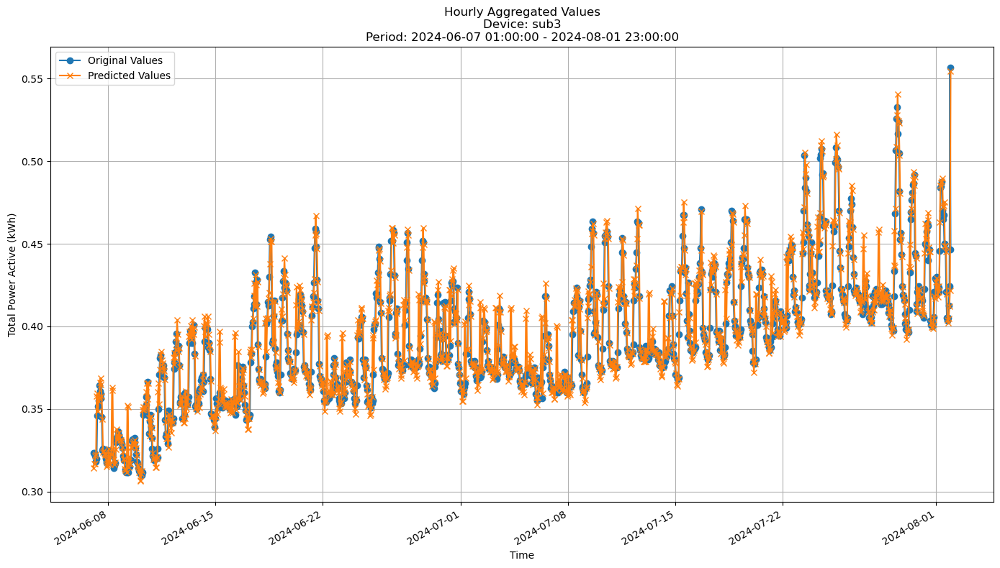


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0138
MAE: 0.0083
MAPE: 2.1163%

Directional Metrics:
Directional Accuracy: 51.2668%
First-Diff Correlation: 0.1236

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  return x1.resample(freq).agg(aggregation), x2.resample(freq).agg(aggregation)
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\evaluation\metrics.py:356: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  if freq_td > pd.Timedelta(C.Freq.H1):
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  return x1.resample(freq).agg(aggregation), x2.resample(freq).agg(aggregation)
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\evaluation\metrics.py:356: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  if freq_td > pd.

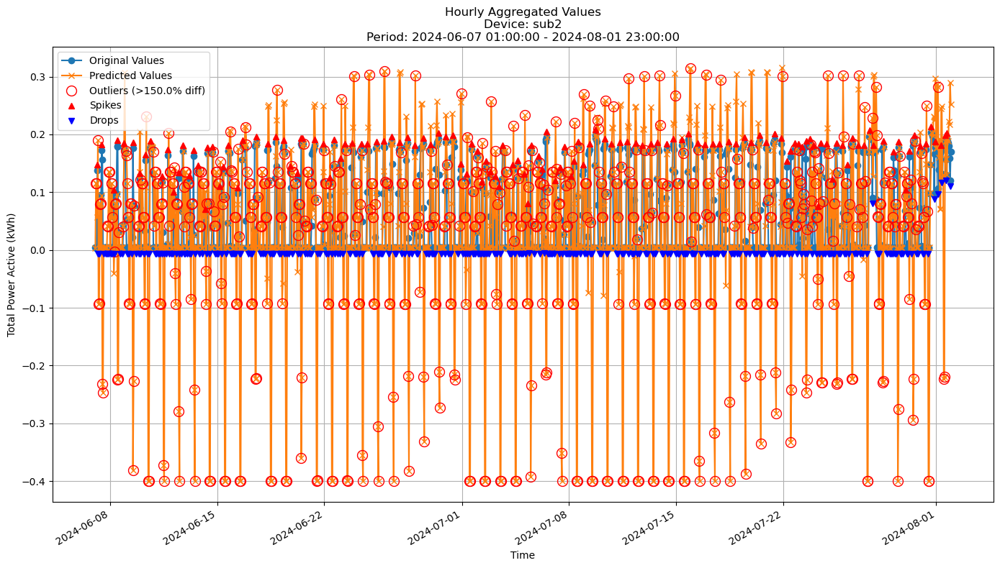


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.1418
MAE: 0.0914
MAPE: 1465.3294%

Directional Metrics:
Directional Accuracy: 43.5917%
First-Diff Correlation: 0.0695

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0526
  Recall: 0.0146
  F1 Score: 0.0229
Drops:
  Precision: 0.1316
  Recall: 0.0185
  F1 Score: 0.0324

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.7368
  Recall: 0.2044
  F1 Score: 0.3200
Drops:
  Precision: 0.7632
  Recall: 0.1070
  F1 Score: 0.1877


c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  return x1.resample(freq).agg(aggregation), x2.resample(freq).agg(aggregation)
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\evaluation\metrics.py:356: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  if freq_td > pd.Timedelta(C.Freq.H1):
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  return x1.resample(freq).agg(aggregation), x2.resample(freq).agg(aggregation)
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\evaluation\metrics.py:356: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  if freq_td > pd.

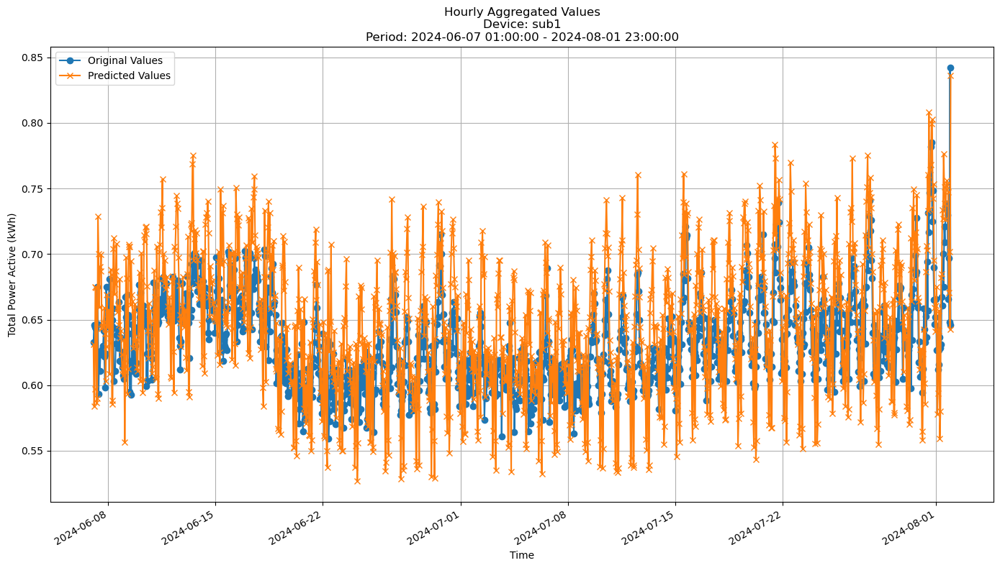


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0465
MAE: 0.0379
MAPE: 6.0239%

Directional Metrics:
Directional Accuracy: 38.2265%
First-Diff Correlation: -0.2674

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [105]:
for device_id in incb_all_train_preds.keys():
    y_train = incb_all_train_preds[device_id][-1]['y_true']
    y_pred_train = incb_all_train_preds[device_id][-1]['y_pred']
    plot_hourly_predictions(y_train, 
                            y_pred_train, 
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last period of predictions

C:\Users\stros\AppData\Local\Temp\ipykernel_24896\4111314728.py:8: FutureWarning: The behavior of array concatenation with empty entries is deprecated. In a future version, this will no longer exclude empty items when determining the result dtype. To retain the old behavior, exclude the empty entries before the concat operation.
  y_valid = pd.concat([y_valid, incb_all_valid_preds[device_id][i]['y_true']], axis=0)
C:\Users\stros\AppData\Local\Temp\ipykernel_24896\4111314728.py:9: FutureWarning: The behavior of array concatenation with empty entries is deprecated. In a future version, this will no longer exclude empty items when determining the result dtype. To retain the old behavior, exclude the empty entries before the concat operation.
  y_pred_valid = pd.concat([y_pred_valid, incb_all_valid_preds[device_id][i]['y_pred']], axis=0)
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be removed in a future

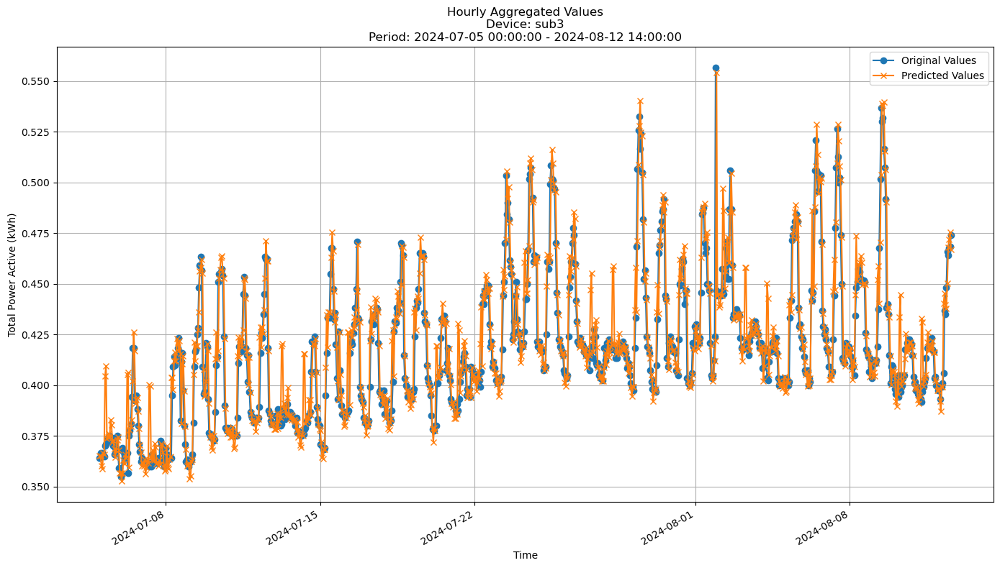


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0146
MAE: 0.0088
MAPE: 2.0742%

Directional Metrics:
Directional Accuracy: 50.6479%
First-Diff Correlation: 0.1444

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


C:\Users\stros\AppData\Local\Temp\ipykernel_24896\4111314728.py:8: FutureWarning: The behavior of array concatenation with empty entries is deprecated. In a future version, this will no longer exclude empty items when determining the result dtype. To retain the old behavior, exclude the empty entries before the concat operation.
  y_valid = pd.concat([y_valid, incb_all_valid_preds[device_id][i]['y_true']], axis=0)
C:\Users\stros\AppData\Local\Temp\ipykernel_24896\4111314728.py:9: FutureWarning: The behavior of array concatenation with empty entries is deprecated. In a future version, this will no longer exclude empty items when determining the result dtype. To retain the old behavior, exclude the empty entries before the concat operation.
  y_pred_valid = pd.concat([y_pred_valid, incb_all_valid_preds[device_id][i]['y_pred']], axis=0)
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be removed in a future

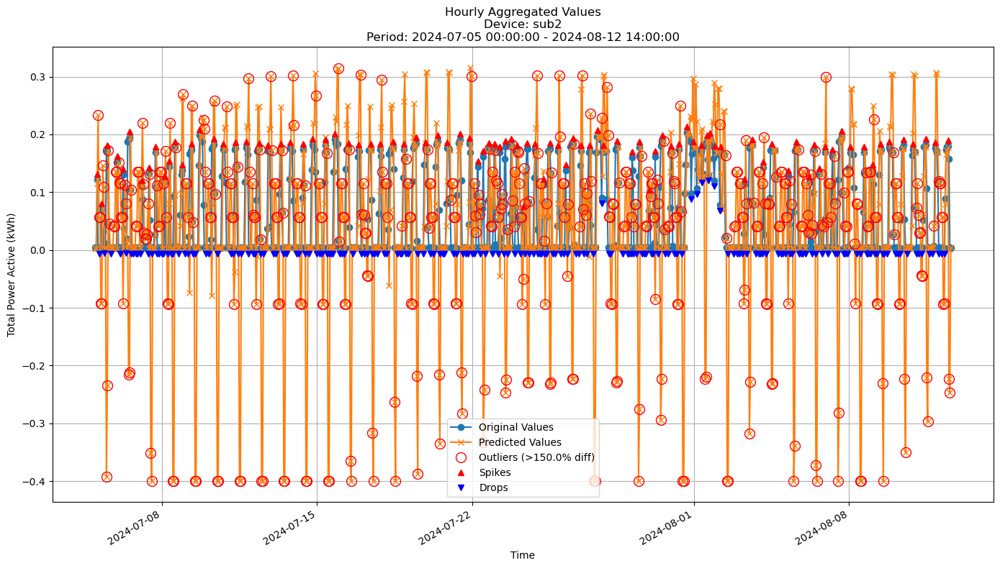


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.1435
MAE: 0.0914
MAPE: 1280.5526%

Directional Metrics:
Directional Accuracy: 43.7365%
First-Diff Correlation: 0.0430

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0370
  Recall: 0.0104
  F1 Score: 0.0163
Drops:
  Precision: 0.1111
  Recall: 0.0161
  F1 Score: 0.0282

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.7407
  Recall: 0.2083
  F1 Score: 0.3252
Drops:
  Precision: 0.7407
  Recall: 0.1075
  F1 Score: 0.1878


C:\Users\stros\AppData\Local\Temp\ipykernel_24896\4111314728.py:8: FutureWarning: The behavior of array concatenation with empty entries is deprecated. In a future version, this will no longer exclude empty items when determining the result dtype. To retain the old behavior, exclude the empty entries before the concat operation.
  y_valid = pd.concat([y_valid, incb_all_valid_preds[device_id][i]['y_true']], axis=0)
C:\Users\stros\AppData\Local\Temp\ipykernel_24896\4111314728.py:9: FutureWarning: The behavior of array concatenation with empty entries is deprecated. In a future version, this will no longer exclude empty items when determining the result dtype. To retain the old behavior, exclude the empty entries before the concat operation.
  y_pred_valid = pd.concat([y_pred_valid, incb_all_valid_preds[device_id][i]['y_pred']], axis=0)
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be removed in a future

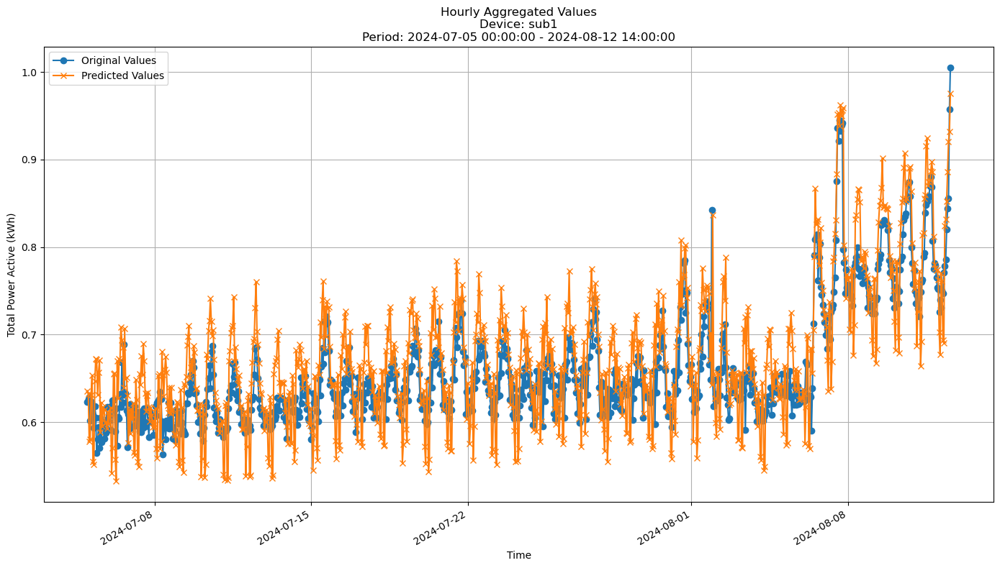


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0459
MAE: 0.0373
MAPE: 5.7299%

Directional Metrics:
Directional Accuracy: 40.0648%
First-Diff Correlation: -0.2038

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [106]:
join_periods = [-2, -1]
# Device iteration
for device_id in incb_all_valid_preds.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, incb_all_valid_preds[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, incb_all_valid_preds[device_id][i]['y_pred']], axis=0)

    plot_hourly_predictions(y_valid,
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id,
                            outlier_threshold=1.5)

In [117]:
update_freq = "1h"  # for incremental models put the same as the data frequency to recreate real world scenario:

elastic_weighted_ratio = IncubationBoost_experimental

elastic_weighted_ratio_params = {
    'length': 30, 
    'learning_rate': 0.01,
    'depth': 30,
    'grace_period': 24,
    'grace_period_depth': -1,
    'split_confidence': 0.1,
    'max_feature': 1,
    'tie_threshold': 0.05,
    'bin_type': 'adaptive',
    'max_bins': 32,
    'split_criterion': 'vr_rel',
    'verbose': False,
    'pruning_strategy': 'weighted_ratio',
    'wr_fixed_multiplier': 0.5,
    'wr_alpha': 1,
    'wr_beta': 0.1,
    'wr_gamma': 0.0,
    'wr_baseline': 0.0,
    'wr_min_keep': 1,
    'wr_error_agg': ['ema'],
    'wr_ema_decay': 0.95,
    'wr_gate_eps': 0.05,
    'wr_cooldown': 32}


In [118]:
elastic_weighted_ratio_all_train_preds, elastic_weighted_ratio_all_valid_preds, \
elastic_weighted_ratio_all_train_metrics, elastic_weighted_ratio_all_valid_metrics = all_valid_splits_seq_fit_predict(
    model_class=elastic_weighted_ratio, 
    model_params=elastic_weighted_ratio_params,
    train=train, 
    valid=valid, 
    use_residuals=USE_RESIDUAL,
    incremental=True, 
    data_freq=DATA_FREQUENCY,
    forecast_horizon=FORECAST_HORIZON,
    features=ALL_FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE, 
    start_split=0, 
    # end_split=1,  # Use only the third and fourth splits
    verbose=1
)

Processing splits:   0%|          | 0/2 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/3 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2024-06-07 01:00:00+02:00 to 2024-07-04 23:00:00+02:00


c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\elastic_boosting_experimental.py:172: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  self._partial_fit(X[i], y[i])


Model's memory usage: 0.229027 MB
Metrics for Device: sub3 | Period: 2024-07-05 00:00:00+02:00 - 2024-08-01 23:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0126
	MAE: 0.0070
	MAPE: 1.6570%

Directional Metrics:
	Directional Accuracy: 52.4590%
	First-Diff Correlation: 0.1218

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.1364
		Recall: 0.1250
		F1: 0.1304
	Drops:
		Precision: 0.0455
		Recall: 0.0400
		F1: 0.0426

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.9545
		Recall: 0.8750
		F1: 0.9130
	Drops:
		Precision: 0.6364
		Recall: 0.5600
		F1: 0.5957
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0089
	MAE: 0.0072
	MAPE: 0.0722%

Directional Metrics:
	Directional Accuracy: 100.0000%
	First-Diff Correlation:

c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\evaluation\metrics.py:356: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  if freq_td > pd.Timedelta(C.Freq.H1):
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  return x1.resample(freq).agg(aggregation), x2.resample(freq).agg(aggregation)
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\evaluation\metrics.py:356: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  if freq_td > pd.Timedelta(C.Freq.H1):
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  return x1.resample(freq).agg(aggregation), x2.resample(f

... (9 outputs left out)

Model's memory usage: 0.341187 MB
Metrics for Device: sub2 | Period: 2024-08-02 00:00:00+02:00 - 2024-08-12 14:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0519
	MAE: 0.0321
	MAPE: 316.2740%

Directional Metrics:
	Directional Accuracy: 49.2126%
	First-Diff Correlation: 0.1221

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0435
		Recall: 0.0417
		F1: 0.0426
	Drops:
		Precision: 0.4348
		Recall: 0.1887
		F1: 0.2632

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.8696
		Recall: 0.8333
		F1: 0.8511
	Drops:
		Precision: 1.0000
		Recall: 0.4340
		F1: 0.6053
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0994
	MAE: 0.0722
	MAPE: 5.4645%

Directional Metrics:
	Directional Accuracy: 100.0000%
	First-Diff Correlatio

c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\evaluation\metrics.py:356: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  if freq_td > pd.Timedelta(C.Freq.H1):
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  return x1.resample(freq).agg(aggregation), x2.resample(freq).agg(aggregation)
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\evaluation\metrics.py:356: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  if freq_td > pd.Timedelta(C.Freq.H1):
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  return x1.resample(freq).agg(aggregation), x2.resample(f

Model's memory usage: 0.278984 MB
Metrics for Device: sub1 | Period: 2024-08-02 00:00:00+02:00 - 2024-08-12 14:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0244
	MAE: 0.0172
	MAPE: 2.3832%

Directional Metrics:
	Directional Accuracy: 50.7874%
	First-Diff Correlation: 0.0377

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.5000
		Recall: 1.0000
		F1: 0.6667
	Drops:
		Precision: 0.5000
		Recall: 1.0000
		F1: 0.6667
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0948
	MAE: 0.0684
	MAPE: 0.4539%

Directional Metrics:
	Directional Accuracy: 100.0000%
	First-Diff Correlation:

c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\evaluation\metrics.py:356: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  if freq_td > pd.Timedelta(C.Freq.H1):
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  return x1.resample(freq).agg(aggregation), x2.resample(freq).agg(aggregation)
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\evaluation\metrics.py:356: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  if freq_td > pd.Timedelta(C.Freq.H1):
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  return x1.resample(freq).agg(aggregation), x2.resample(f

In [ ]:
print("\n\nTrain period metrics:")
elastic_weighted_ratio_all_time_train_metrics = all_time_aggregation_metrics(elastic_weighted_ratio_all_train_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\nValid period metrics:")
elastic_weighted_ratio_all_time_valid_metrics = all_time_aggregation_metrics(elastic_weighted_ratio_all_valid_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: sub3
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.0101 ± 0.0009
	MAE: 0.0060 ± 0.0004
	MAPE: 1.5320% ± 0.0498%

	Directional Metrics:
		Directional Accuracy: 49.9996% ± 0.5966%
		First-Diff Correlation: 0.2401 ± 0.0561

	Immediate Detection (delta=0):
		Spike Precision: 0.0676 ± 0.0676
		Spike Recall: 0.0625 ± 0.0625
		Spike F1: 0.0649 ± 0.0649
		Drop Precision: 0.0125 ± 0.0125
		Drop Recall: 0.0111 ± 0.0111
		Drop F1: 0.0118 ± 0.0118

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.9502 ± 0.0043
		Spike Recall: 0.9148 ± 0.0398
		Spike F1: 0.9318 ± 0.0227
		Drop Precision: 0.7670 ± 0.1420
		Drop Recall: 0.6944 ± 0.1389
		Drop F1: 0.7289 ± 0.1407
Daily Metrics:
	RMSE: 0.0144 ± 0.0017
	MAE: 0.0100 ± 0.0010
	MAPE: 0.1091% ± 0.0126%

	Directional Metrics:
		Directional Accuracy: 100.0000% ± 0.0000%
		First-Diff Correlation: 0.9970 ± 0.0008

	Immediate Detection (delta=0):
		Spike

In [126]:
update_freq = "1h"  # for incremental models put the same as the data frequency to recreate real world scenario:

elastic = IncubationBoost_experimental
elastic_params = {
    'length': 50, 
    'learning_rate': 0.001,
    'depth': 5,
    'grace_period': 48,
    'grace_period_depth': -1,
    'split_confidence': 0.1,
    'max_feature': 0.5,
    'tie_threshold': 0.05,
    'bin_type': 'adaptive',
    'max_bins': 32,
    'split_criterion': 'vr_rel',
    'verbose': False,
    'pruning_strategy': 'new_egbdt',
    'wr_fixed_multiplier': 2.0,
    'wr_alpha': 0,
    'wr_beta': 0,
    'wr_gamma': 0,
    'wr_baseline': 0.0,
    'wr_min_keep': 3,
    'wr_error_agg': 'ema',
    'wr_ema_decay': 0,
    'wr_gate_eps': 0,
    'wr_cooldown': 0
}

In [127]:
elastic_all_train_preds, elastic_all_valid_preds, \
elastic_all_train_metrics, elastic_all_valid_metrics = all_valid_splits_seq_fit_predict(
    model_class=elastic, 
    model_params=elastic_params,
    train=train, 
    valid=valid, 
    use_residuals=USE_RESIDUAL,
    incremental=True, 
    data_freq=DATA_FREQUENCY,
    forecast_horizon=FORECAST_HORIZON,
    features=ALL_FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE, 
    start_split=0, 
    # end_split=1,  # Use only the third and fourth splits
    verbose=1)

Processing splits:   0%|          | 0/2 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/3 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2024-06-07 01:00:00+02:00 to 2024-07-04 23:00:00+02:00


c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\elastic_boosting_experimental.py:172: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  self._partial_fit(X[i], y[i])


Model's memory usage: 0.165199 MB
Metrics for Device: sub3 | Period: 2024-07-05 00:00:00+02:00 - 2024-08-01 23:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0127
	MAE: 0.0072
	MAPE: 1.6919%

Directional Metrics:
	Directional Accuracy: 52.1610%
	First-Diff Correlation: 0.1139

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0455
		Recall: 0.0417
		F1: 0.0435
	Drops:
		Precision: 0.0455
		Recall: 0.0400
		F1: 0.0426

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.8636
		Recall: 0.7917
		F1: 0.8261
	Drops:
		Precision: 0.8636
		Recall: 0.7600
		F1: 0.8085
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0236
	MAE: 0.0194
	MAPE: 0.1938%

Directional Metrics:
	Directional Accuracy: 100.0000%
	First-Diff Correlation:

c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\evaluation\metrics.py:356: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  if freq_td > pd.Timedelta(C.Freq.H1):
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  return x1.resample(freq).agg(aggregation), x2.resample(freq).agg(aggregation)
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\evaluation\metrics.py:356: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  if freq_td > pd.Timedelta(C.Freq.H1):
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  return x1.resample(freq).agg(aggregation), x2.resample(f

... (9 outputs left out)

Model's memory usage: 0.144226 MB
Metrics for Device: sub2 | Period: 2024-08-02 00:00:00+02:00 - 2024-08-12 14:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0527
	MAE: 0.0336
	MAPE: 339.6238%

Directional Metrics:
	Directional Accuracy: 48.0315%
	First-Diff Correlation: 0.1143

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0833
		Recall: 0.0833
		F1: 0.0833
	Drops:
		Precision: 0.4583
		Recall: 0.2075
		F1: 0.2857

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.8333
		Recall: 0.8333
		F1: 0.8333
	Drops:
		Precision: 1.0000
		Recall: 0.4528
		F1: 0.6234
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0916
	MAE: 0.0713
	MAPE: 5.4566%

Directional Metrics:
	Directional Accuracy: 90.0000%
	First-Diff Correlation

c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\evaluation\metrics.py:356: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  if freq_td > pd.Timedelta(C.Freq.H1):
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  return x1.resample(freq).agg(aggregation), x2.resample(freq).agg(aggregation)
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\evaluation\metrics.py:356: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  if freq_td > pd.Timedelta(C.Freq.H1):
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  return x1.resample(freq).agg(aggregation), x2.resample(f

Model's memory usage: 0.145874 MB
Metrics for Device: sub1 | Period: 2024-08-02 00:00:00+02:00 - 2024-08-12 14:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0244
	MAE: 0.0170
	MAPE: 2.3630%

Directional Metrics:
	Directional Accuracy: 50.3937%
	First-Diff Correlation: 0.0282

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.5000
		Recall: 1.0000
		F1: 0.6667
	Drops:
		Precision: 0.5000
		Recall: 1.0000
		F1: 0.6667
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0861
	MAE: 0.0523
	MAPE: 0.3576%

Directional Metrics:
	Directional Accuracy: 100.0000%
	First-Diff Correlation:

c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\evaluation\metrics.py:356: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  if freq_td > pd.Timedelta(C.Freq.H1):
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  return x1.resample(freq).agg(aggregation), x2.resample(freq).agg(aggregation)
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\evaluation\metrics.py:356: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  if freq_td > pd.Timedelta(C.Freq.H1):
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  return x1.resample(freq).agg(aggregation), x2.resample(f

In [128]:
print("\n\nTrain period metrics:")
elastic_all_time_train_metrics = all_time_aggregation_metrics(elastic_all_train_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\nValid period metrics:")
elastic_all_time_valid_metrics = all_time_aggregation_metrics(elastic_all_valid_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: sub3
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.0104 ± 0.0008
	MAE: 0.0062 ± 0.0004
	MAPE: 1.5774% ± 0.0548%

	Directional Metrics:
		Directional Accuracy: 49.5897% ± 0.1867%
		First-Diff Correlation: 0.2424 ± 0.0535

	Immediate Detection (delta=0):
		Spike Precision: 0.0256 ± 0.0256
		Spike Recall: 0.0250 ± 0.0250
		Spike F1: 0.0253 ± 0.0253
		Drop Precision: 0.0000 ± 0.0000
		Drop Recall: 0.0000 ± 0.0000
		Drop F1: 0.0000 ± 0.0000

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.9872 ± 0.0128
		Spike Recall: 0.9750 ± 0.0250
		Spike F1: 0.9810 ± 0.0190
		Drop Precision: 0.9886 ± 0.0114
		Drop Recall: 0.9778 ± 0.0222
		Drop F1: 0.9831 ± 0.0169
Daily Metrics:
	RMSE: 0.0217 ± 0.0052
	MAE: 0.0173 ± 0.0059
	MAPE: 0.1890% ± 0.0613%

	Directional Metrics:
		Directional Accuracy: 100.0000% ± 0.0000%
		First-Diff Correlation: 0.9965 ± 0.0003

	Immediate Detection (delta=0):
		Spike

# Test-set Model Evaluation
(`train[-1]` + `valid[-1]`) vs `test`

In [ ]:
# Define model classes and params for test-set evaluation
models_classes = [bl_prev, bl_mean, gbdt, rf, hoef, arf_hf, fodt, arf, incb, elastic_weighted_ratio, elastic]
models_params = [
    bl_prev_params,
    bl_mean_params,
    gbdt_params,
    rf_params,
    hoef_params,
    arf_hf_params,
    fodt_params,
    arf_params,
    incb_params,
    elastic_weighted_ratio_params,
    elastic_params,
 ]

model_test_results = {}
for model_class, params in zip(models_classes, models_params):
    if model_class in [gbdt, rf, bl_mean]:
        incremental = False
        update_freq = "14D"
        print(f"Model: {model_class.__name__} - update_freq: {update_freq}")
    else:
        incremental = True
        update_freq = "1h"
        print(f"Model: {model_class.__name__} - update_freq: {update_freq}")

    _, test_preds, \
    _, test_metrics = test_set_seq_fit_predict(
        model_class=model_class,
        model_params=params,
        train=train,
        valid=valid,
        test=test,
        use_residuals=USE_RESIDUAL,
        incremental=incremental,
        data_freq=DATA_FREQUENCY,
        forecast_horizon=FORECAST_HORIZON,
        features=ALL_FEATURES,
        update_freq=update_freq,
        spike_prominence=SPIKE_PROMINENCE,
        normalize_robust=True,
        predict_train=False,
        verbose=True
    )
    model_test_results[model_class.__name__] = {
        "test_preds": test_preds,
        "test_metrics": test_metrics
    }

Model: PreviousValueRegressor - update_freq: 1h


Processing devices for test predictions:   0%|          | 0/3 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2024-06-07 01:00:00+02:00 to 2024-08-12 14:00:00+02:00
Model's memory usage: 0.000397 MB
Metrics for Device: sub1 | Period: 2024-08-12 16:00:00+02:00 - 2024-08-29 13:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0280
	MAE: 0.0174
	MAPE: 1.9633%

Directional Metrics:
	Directional Accuracy: 65.4321%
	First-Diff Correlation: 0.1884

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
	Drops:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
--------------------------------------------------
Daily

c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\evaluation\metrics.py:356: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  if freq_td > pd.Timedelta(C.Freq.H1):
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  return x1.resample(freq).agg(aggregation), x2.resample(freq).agg(aggregation)
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\evaluation\metrics.py:356: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  if freq_td > pd.Timedelta(C.Freq.H1):
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  return x1.resample(freq).agg(aggregation), x2.resample(f

Model's memory usage: 0.000389 MB
Metrics for Device: sub2 | Period: 2024-08-12 16:00:00+02:00 - 2024-08-29 13:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0620
	MAE: 0.0335
	MAPE: 255.4081%

Directional Metrics:
	Directional Accuracy: 45.1852%
	First-Diff Correlation: 0.1293

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
	Drops:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0756
	MAE: 0.0384
	MAPE: 3.7958%

Directional Metrics:
	Directional Accuracy: 100.0000%
	First-Diff Correlatio

c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\evaluation\metrics.py:356: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  if freq_td > pd.Timedelta(C.Freq.H1):
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  return x1.resample(freq).agg(aggregation), x2.resample(freq).agg(aggregation)
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\evaluation\metrics.py:356: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  if freq_td > pd.Timedelta(C.Freq.H1):
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  return x1.resample(freq).agg(aggregation), x2.resample(f

... (68 outputs left out)

Model's memory usage: 0.222214 MB
Metrics for Device: sub2 | Period: 2024-08-12 16:00:00+02:00 - 2024-08-29 13:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0562
	MAE: 0.0363
	MAPE: 352.5246%

Directional Metrics:
	Directional Accuracy: 53.0864%
	First-Diff Correlation: 0.1686

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.2619
		Recall: 0.2500
		F1: 0.2558
	Drops:
		Precision: 0.2927
		Recall: 0.1622
		F1: 0.2087

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.9048
		Recall: 0.8636
		F1: 0.8837
	Drops:
		Precision: 0.8537
		Recall: 0.4730
		F1: 0.6087
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0776
	MAE: 0.0636
	MAPE: 4.9258%

Directional Metrics:
	Directional Accuracy: 94.1176%
	First-Diff Correlation

c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\evaluation\metrics.py:356: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  if freq_td > pd.Timedelta(C.Freq.H1):
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  return x1.resample(freq).agg(aggregation), x2.resample(freq).agg(aggregation)
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\evaluation\metrics.py:356: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  if freq_td > pd.Timedelta(C.Freq.H1):
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  return x1.resample(freq).agg(aggregation), x2.resample(f

Model's memory usage: 0.187958 MB
Metrics for Device: sub3 | Period: 2024-08-12 16:00:00+02:00 - 2024-08-29 13:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0091
	MAE: 0.0060
	MAPE: 1.4767%

Directional Metrics:
	Directional Accuracy: 47.9012%
	First-Diff Correlation: 0.2090

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0769
		Recall: 0.0714
		F1: 0.0741
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.8462
		Recall: 0.7857
		F1: 0.8148
	Drops:
		Precision: 0.5714
		Recall: 0.4706
		F1: 0.5161
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0161
	MAE: 0.0131
	MAPE: 0.1815%

Directional Metrics:
	Directional Accuracy: 100.0000%
	First-Diff Correlation:

c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\evaluation\metrics.py:356: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  if freq_td > pd.Timedelta(C.Freq.H1):
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  return x1.resample(freq).agg(aggregation), x2.resample(freq).agg(aggregation)
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\evaluation\metrics.py:356: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  if freq_td > pd.Timedelta(C.Freq.H1):
c:\Users\stros\Documents\Mycroft\Incremental-Learning-MycroftMinds\src\utils\utils.py:80: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  return x1.resample(freq).agg(aggregation), x2.resample(f

In [132]:
for model in models_classes:
    print(f"\n\nModel: {model.__name__} - Test set metrics:")
    model_test_results[model.__name__]['test_metrics'] = all_time_aggregation_metrics(
        model_test_results[model.__name__]['test_metrics'],
        data_freq=DATA_FREQUENCY,
        verbose=False)



Model: PreviousValueRegressor - Test set metrics:


TypeError: string indices must be integers, not 'str'

# Model Comparison

In [ ]:
AGG_LEVEL = "hourly"
METRICS = ["rmse", "mae", "mape", "dir_accuracy", "first_diff_corr"]
PERC_METRICS = ["mape", "dir_accuracy", "first_diff_corr"]
# SPIKES_METRICS = ["spikes_immediate.precision", "spikes_immediate.recall", "spikes_immediate.f1",
#                   "spikes_delayed.precision", "spikes_delayed.recall", "spikes_delayed.f1",
#                   "drops_immediate.precision", "drops_immediate.recall", "drops_immediate.f1",
#                   "drops_delayed.precision", "drops_delayed.recall", "drops_delayed.f1"]
SPIKES_METRICS = ["spikes_immediate.f1", "spikes_delayed.f1",
                  "drops_immediate.f1", "drops_delayed.f1"]

METRICS.extend(SPIKES_METRICS)
PERC_METRICS.extend(SPIKES_METRICS)

## Test results

In [ ]:
MODEL_TEST_METRICS = {
    "BL_Prev": model_test_results[bl_prev.__name__]["test_metrics"],
    "BL_Mean": model_test_results[bl_mean.__name__]["test_metrics"],
    "GBDT": model_test_results[gbdt.__name__]["test_metrics"],
    "RandomForest": model_test_results[rf.__name__]["test_metrics"],
    "HoeffdingTree": model_test_results[hoef.__name__]["test_metrics"],
    "ARF_Hoeffding": model_test_results[arf_hf.__name__]["test_metrics"],
    "FastODT": model_test_results[fodt.__name__]["test_metrics"],
    "ARF_FastODT": model_test_results[arf.__name__]["test_metrics"],
    "IncubationBoostLastContributingPruning": model_test_results[incb.__name__]["test_metrics"],
    'IncubationBoostWeightedRatioPruning': model_test_results[elastic_weighted_ratio.__name__]["test_metrics"],
    'IncubationBoostElasticPrining': model_test_results[elastic.__name__]["test_metrics"]
}

In [ ]:
def format_metric(val, is_perc=False):
    if isinstance(val, dict) and "mean" in val and "std" in val:
        mean = val["mean"]
        std = val["std"]
        if is_perc:
            mean = mean * 100
            std = std * 100
        return f"{mean:.3f} ± {std:.3f}"
    if is_perc:
        return f"{val*100:.3f}" if val is not None else None
    return f"{val:.3f}" if val is not None else None

def display_aggregated_results(model_metrics, device_ids, agg_level):
    for device_id in device_ids:
        rows = []
        for model, mdict in model_metrics.items():
            if device_id in mdict and agg_level in mdict[device_id]:
                vals = mdict[device_id][agg_level]
                row = [model]
                for m in METRICS:
                    is_perc = (m in PERC_METRICS)
                    row.append(format_metric(vals.get(m, None), is_perc=is_perc))
                rows.append(row)
        df = pd.DataFrame(rows, columns=["Model", "RMSE", "MAE", "MAPE (%)", "Directional Accuracy (%)", "First Diff Corr (%)",
                                         "Spikes Immediate F1 (%)", "Spikes Delayed F1 (%)", "Drops Immediate F1 (%)", "Drops Delayed F1 (%)"])
        print(f"\n\nDevice: {device_id} | Aggregation: {agg_level}")
        display(df)

In [ ]:
device_ids = set()
for m in MODEL_TEST_METRICS.values():
    device_ids.update(m.keys())
device_ids = sorted(device_ids)

print("\n\n============================Hourly Test Results============================")
display_aggregated_results(MODEL_TEST_METRICS, device_ids, AGG_LEVEL)



============================Hourly Test Results============================


Device: sub1 | Aggregation: hourly


,Model,RMSE,MAE,MAPE (%),Directional Accuracy (%),First Diff Corr (%),Spikes Immediate F1 (%),Spikes Delayed F1 (%),Drops Immediate F1 (%),Drops Delayed F1 (%)
0,BL_Prev,0.028 ± 0.000,0.017 ± 0.000,1.963 ± 0.000,65.432 ± 0.000,18.836 ± 0.000,0.000 ± 0.000,100.000 ± 0.000,0.000 ± 0.000,100.000 ± 0.000
1,BL_Mean,0.029 ± 0.000,0.019 ± 0.000,2.127 ± 0.000,58.272 ± 0.000,15.840 ± 0.000,24.000 ± 0.000,56.000 ± 0.000,0.000 ± 0.000,69.231 ± 0.000
2,GBDT,0.050 ± 0.000,0.033 ± 0.000,3.623 ± 0.000,62.222 ± 0.000,14.360 ± 0.000,6.250 ± 0.000,37.500 ± 0.000,0.000 ± 0.000,35.294 ± 0.000
3,RandomForest,0.041 ± 0.000,0.028 ± 0.000,3.091 ± 0.000,63.210 ± 0.000,17.023 ± 0.000,15.385 ± 0.000,53.846 ± 0.000,7.143 ± 0.000,35.714 ± 0.000
4,HoeffdingTree,0.027 ± 0.000,0.017 ± 0.000,1.926 ± 0.000,63.951 ± 0.000,20.074 ± 0.000,8.000 ± 0.000,80.000 ± 0.000,0.000 ± 0.000,92.308 ± 0.000
5,ARF_Hoeffding,0.027 ± 0.000,0.016 ± 0.000,1.853 ± 0.000,62.716 ± 0.000,19.962 ± 0.000,8.333 ± 0.000,91.667 ± 0.000,7.692 ± 0.000,61.538 ± 0.000
6,FastODT,0.039 ± 0.000,0.026 ± 0.000,2.933 ± 0.000,57.531 ± 0.000,13.867 ± 0.000,12.903 ± 0.000,51.613 ± 0.000,6.061 ± 0.000,24.242 ± 0.000
7,ARF_FastODT,0.032 ± 0.000,0.022 ± 0.000,2.516 ± 0.000,57.778 ± 0.000,14.546 ± 0.000,7.143 ± 0.000,42.857 ± 0.000,0.000 ± 0.000,40.000 ± 0.000
8,IncubationBoost,0.045 ± 0.000,0.036 ± 0.000,4.149 ± 0.000,61.481 ± 0.000,23.092 ± 0.000,0.000 ± 0.000,44.444 ± 0.000,6.897 ± 0.000,41.379 ± 0.000
9,IncubationBoostExperimantal,0.028 ± 0.000,0.018 ± 0.000,1.991 ± 0.000,66.420 ± 0.000,18.966 ± 0.000,8.333 ± 0.000,91.667 ± 0.000,0.000 ± 0.000,100.000 ± 0.000




Device: sub2 | Aggregation: hourly


,Model,RMSE,MAE,MAPE (%),Directional Accuracy (%),First Diff Corr (%),Spikes Immediate F1 (%),Spikes Delayed F1 (%),Drops Immediate F1 (%),Drops Delayed F1 (%)
0,BL_Prev,0.062 ± 0.000,0.034 ± 0.000,255.408 ± 0.000,45.185 ± 0.000,12.933 ± 0.000,0.000 ± 0.000,100.000 ± 0.000,0.000 ± 0.000,100.000 ± 0.000
1,BL_Mean,0.066 ± 0.000,0.043 ± 0.000,414.709 ± 0.000,51.852 ± 0.000,8.196 ± 0.000,9.412 ± 0.000,68.235 ± 0.000,19.298 ± 0.000,45.614 ± 0.000
2,GBDT,0.049 ± 0.000,0.035 ± 0.000,322.762 ± 0.000,58.025 ± 0.000,29.377 ± 0.000,23.256 ± 0.000,76.744 ± 0.000,22.609 ± 0.000,60.870 ± 0.000
3,RandomForest,0.051 ± 0.000,0.035 ± 0.000,309.271 ± 0.000,55.309 ± 0.000,29.173 ± 0.000,27.273 ± 0.000,81.818 ± 0.000,22.222 ± 0.000,54.701 ± 0.000
4,HoeffdingTree,0.055 ± 0.000,0.038 ± 0.000,325.314 ± 0.000,52.593 ± 0.000,16.785 ± 0.000,20.930 ± 0.000,83.721 ± 0.000,22.414 ± 0.000,55.172 ± 0.000
5,ARF_Hoeffding,0.058 ± 0.000,0.037 ± 0.000,335.182 ± 0.000,51.111 ± 0.000,13.318 ± 0.000,16.471 ± 0.000,77.647 ± 0.000,15.789 ± 0.000,56.140 ± 0.000
6,FastODT,0.072 ± 0.000,0.045 ± 0.000,485.928 ± 0.000,54.815 ± 0.000,16.408 ± 0.000,18.868 ± 0.000,73.585 ± 0.000,13.235 ± 0.000,51.471 ± 0.000
7,ARF_FastODT,0.067 ± 0.000,0.047 ± 0.000,558.529 ± 0.000,55.556 ± 0.000,15.935 ± 0.000,21.053 ± 0.000,77.895 ± 0.000,22.581 ± 0.000,62.903 ± 0.000
8,IncubationBoost,0.150 ± 0.000,0.097 ± 0.000,1120.360 ± 0.000,44.444 ± 0.000,-9.987 ± 0.000,4.396 ± 0.000,79.121 ± 0.000,3.252 ± 0.000,52.033 ± 0.000
9,IncubationBoostExperimantal,0.061 ± 0.000,0.036 ± 0.000,306.735 ± 0.000,51.605 ± 0.000,12.847 ± 0.000,9.302 ± 0.000,88.372 ± 0.000,5.217 ± 0.000,50.435 ± 0.000




Device: sub3 | Aggregation: hourly


,Model,RMSE,MAE,MAPE (%),Directional Accuracy (%),First Diff Corr (%),Spikes Immediate F1 (%),Spikes Delayed F1 (%),Drops Immediate F1 (%),Drops Delayed F1 (%)
0,BL_Prev,0.010 ± 0.000,0.006 ± 0.000,1.528 ± 0.000,45.432 ± 0.000,19.885 ± 0.000,0.000 ± 0.000,100.000 ± 0.000,0.000 ± 0.000,100.000 ± 0.000
1,BL_Mean,0.008 ± 0.000,0.006 ± 0.000,1.425 ± 0.000,51.852 ± 0.000,28.765 ± 0.000,0.000 ± 0.000,50.000 ± 0.000,0.000 ± 0.000,56.250 ± 0.000
2,GBDT,0.008 ± 0.000,0.006 ± 0.000,1.444 ± 0.000,51.111 ± 0.000,26.856 ± 0.000,0.000 ± 0.000,51.852 ± 0.000,6.452 ± 0.000,45.161 ± 0.000
3,RandomForest,0.008 ± 0.000,0.006 ± 0.000,1.450 ± 0.000,50.864 ± 0.000,28.125 ± 0.000,0.000 ± 0.000,51.852 ± 0.000,6.452 ± 0.000,64.516 ± 0.000
4,HoeffdingTree,0.009 ± 0.000,0.006 ± 0.000,1.557 ± 0.000,47.160 ± 0.000,22.087 ± 0.000,0.000 ± 0.000,35.714 ± 0.000,6.250 ± 0.000,50.000 ± 0.000
5,ARF_Hoeffding,0.008 ± 0.000,0.006 ± 0.000,1.366 ± 0.000,48.889 ± 0.000,28.711 ± 0.000,7.407 ± 0.000,59.259 ± 0.000,0.000 ± 0.000,64.516 ± 0.000
6,FastODT,0.013 ± 0.000,0.007 ± 0.000,1.756 ± 0.000,49.136 ± 0.000,11.830 ± 0.000,19.355 ± 0.000,64.516 ± 0.000,0.000 ± 0.000,40.000 ± 0.000
7,ARF_FastODT,0.011 ± 0.000,0.008 ± 0.000,1.912 ± 0.000,50.123 ± 0.000,17.894 ± 0.000,12.903 ± 0.000,32.258 ± 0.000,11.765 ± 0.000,35.294 ± 0.000
8,IncubationBoost,0.012 ± 0.000,0.008 ± 0.000,1.913 ± 0.000,48.642 ± 0.000,10.999 ± 0.000,13.333 ± 0.000,66.667 ± 0.000,0.000 ± 0.000,47.059 ± 0.000
9,IncubationBoostExperimantal,0.009 ± 0.000,0.006 ± 0.000,1.513 ± 0.000,47.160 ± 0.000,20.813 ± 0.000,7.407 ± 0.000,96.296 ± 0.000,0.000 ± 0.000,51.613 ± 0.000


<div>
<style scoped>
    .dataframe tbody tr th:only-of-type {
        vertical-align: middle;
    }

    .dataframe tbody tr th {
        vertical-align: top;
    }

    .dataframe thead th {
        text-align: right;
    }
</style>
<table border="1" class="dataframe">
  <thead>
    <tr style="text-align: right;">
      <th></th>
      <th>Model</th>
      <th>RMSE</th>
      <th>MAE</th>
      <th>MAPE (%)</th>
      <th>Directional Accuracy (%)</th>
      <th>First Diff Corr (%)</th>
      <th>Spikes Immediate F1 (%)</th>
      <th>Spikes Delayed F1 (%)</th>
      <th>Drops Immediate F1 (%)</th>
      <th>Drops Delayed F1 (%)</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <th>0</th>
      <td>BL_Prev</td>
      <td>0.028 ± 0.000</td>
      <td>0.017 ± 0.000</td>
      <td>1.963 ± 0.000</td>
      <td>65.432 ± 0.000</td>
      <td>18.836 ± 0.000</td>
      <td>0.000 ± 0.000</td>
      <td>100.000 ± 0.000</td>
      <td>0.000 ± 0.000</td>
      <td>100.000 ± 0.000</td>
    </tr>
    <tr>
      <th>1</th>
      <td>BL_Mean</td>
      <td>0.029 ± 0.000</td>
      <td>0.019 ± 0.000</td>
      <td>2.127 ± 0.000</td>
      <td>58.272 ± 0.000</td>
      <td>15.840 ± 0.000</td>
      <td>24.000 ± 0.000</td>
      <td>56.000 ± 0.000</td>
      <td>0.000 ± 0.000</td>
      <td>69.231 ± 0.000</td>
    </tr>
    <tr>
      <th>2</th>
      <td>GBDT</td>
      <td>0.050 ± 0.000</td>
      <td>0.033 ± 0.000</td>
      <td>3.623 ± 0.000</td>
      <td>62.222 ± 0.000</td>
      <td>14.360 ± 0.000</td>
      <td>6.250 ± 0.000</td>
      <td>37.500 ± 0.000</td>
      <td>0.000 ± 0.000</td>
      <td>35.294 ± 0.000</td>
    </tr>
    <tr>
      <th>3</th>
      <td>RandomForest</td>
      <td>0.041 ± 0.000</td>
      <td>0.028 ± 0.000</td>
      <td>3.091 ± 0.000</td>
      <td>63.210 ± 0.000</td>
      <td>17.023 ± 0.000</td>
      <td>15.385 ± 0.000</td>
      <td>53.846 ± 0.000</td>
      <td>7.143 ± 0.000</td>
      <td>35.714 ± 0.000</td>
    </tr>
    <tr>
      <th>4</th>
      <td>HoeffdingTree</td>
      <td>0.027 ± 0.000</td>
      <td>0.017 ± 0.000</td>
      <td>1.926 ± 0.000</td>
      <td>63.951 ± 0.000</td>
      <td>20.074 ± 0.000</td>
      <td>8.000 ± 0.000</td>
      <td>80.000 ± 0.000</td>
      <td>0.000 ± 0.000</td>
      <td>92.308 ± 0.000</td>
    </tr>
    <tr>
      <th>5</th>
      <td>ARF_Hoeffding</td>
      <td>0.027 ± 0.000</td>
      <td>0.016 ± 0.000</td>
      <td>1.853 ± 0.000</td>
      <td>62.716 ± 0.000</td>
      <td>19.962 ± 0.000</td>
      <td>8.333 ± 0.000</td>
      <td>91.667 ± 0.000</td>
      <td>7.692 ± 0.000</td>
      <td>61.538 ± 0.000</td>
    </tr>
    <tr>
      <th>6</th>
      <td>FastODT</td>
      <td>0.039 ± 0.000</td>
      <td>0.027 ± 0.000</td>
      <td>3.078 ± 0.000</td>
      <td>58.272 ± 0.000</td>
      <td>11.352 ± 0.000</td>
      <td>6.667 ± 0.000</td>
      <td>40.000 ± 0.000</td>
      <td>12.121 ± 0.000</td>
      <td>42.424 ± 0.000</td>
    </tr>
    <tr>
      <th>7</th>
      <td>ARF_FastODT</td>
      <td>0.032 ± 0.000</td>
      <td>0.022 ± 0.000</td>
      <td>2.501 ± 0.000</td>
      <td>60.000 ± 0.000</td>
      <td>14.285 ± 0.000</td>
      <td>0.000 ± 0.000</td>
      <td>44.444 ± 0.000</td>
      <td>6.897 ± 0.000</td>
      <td>55.172 ± 0.000</td>
    </tr>
    <tr>
      <th>8</th>
      <td>IncubationBoost</td>
      <td>0.045 ± 0.000</td>
      <td>0.036 ± 0.000</td>
      <td>4.149 ± 0.000</td>
      <td>61.481 ± 0.000</td>
      <td>23.092 ± 0.000</td>
      <td>0.000 ± 0.000</td>
      <td>44.444 ± 0.000</td>
      <td>6.897 ± 0.000</td>
      <td>41.379 ± 0.000</td>
    </tr>
  </tbody>
</table>
</div>

<div>
<style scoped>
    .dataframe tbody tr th:only-of-type {
        vertical-align: middle;
    }

    .dataframe tbody tr th {
        vertical-align: top;
    }

    .dataframe thead th {
        text-align: right;
    }
</style>
<table border="1" class="dataframe">
  <thead>
    <tr style="text-align: right;">
      <th></th>
      <th>Model</th>
      <th>RMSE</th>
      <th>MAE</th>
      <th>MAPE (%)</th>
      <th>Directional Accuracy (%)</th>
      <th>First Diff Corr (%)</th>
      <th>Spikes Immediate F1 (%)</th>
      <th>Spikes Delayed F1 (%)</th>
      <th>Drops Immediate F1 (%)</th>
      <th>Drops Delayed F1 (%)</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <th>0</th>
      <td>BL_Prev</td>
      <td>0.062 ± 0.000</td>
      <td>0.034 ± 0.000</td>
      <td>255.408 ± 0.000</td>
      <td>45.185 ± 0.000</td>
      <td>12.933 ± 0.000</td>
      <td>0.000 ± 0.000</td>
      <td>100.000 ± 0.000</td>
      <td>0.000 ± 0.000</td>
      <td>100.000 ± 0.000</td>
    </tr>
    <tr>
      <th>1</th>
      <td>BL_Mean</td>
      <td>0.066 ± 0.000</td>
      <td>0.043 ± 0.000</td>
      <td>414.709 ± 0.000</td>
      <td>51.852 ± 0.000</td>
      <td>8.196 ± 0.000</td>
      <td>9.412 ± 0.000</td>
      <td>68.235 ± 0.000</td>
      <td>19.298 ± 0.000</td>
      <td>45.614 ± 0.000</td>
    </tr>
    <tr>
      <th>2</th>
      <td>GBDT</td>
      <td>0.049 ± 0.000</td>
      <td>0.035 ± 0.000</td>
      <td>322.762 ± 0.000</td>
      <td>58.025 ± 0.000</td>
      <td>29.377 ± 0.000</td>
      <td>23.256 ± 0.000</td>
      <td>76.744 ± 0.000</td>
      <td>22.609 ± 0.000</td>
      <td>60.870 ± 0.000</td>
    </tr>
    <tr>
      <th>3</th>
      <td>RandomForest</td>
      <td>0.051 ± 0.000</td>
      <td>0.035 ± 0.000</td>
      <td>309.271 ± 0.000</td>
      <td>55.309 ± 0.000</td>
      <td>29.173 ± 0.000</td>
      <td>27.273 ± 0.000</td>
      <td>81.818 ± 0.000</td>
      <td>22.222 ± 0.000</td>
      <td>54.701 ± 0.000</td>
    </tr>
    <tr>
      <th>4</th>
      <td>HoeffdingTree</td>
      <td>0.055 ± 0.000</td>
      <td>0.038 ± 0.000</td>
      <td>325.314 ± 0.000</td>
      <td>52.593 ± 0.000</td>
      <td>16.785 ± 0.000</td>
      <td>20.930 ± 0.000</td>
      <td>83.721 ± 0.000</td>
      <td>22.414 ± 0.000</td>
      <td>55.172 ± 0.000</td>
    </tr>
    <tr>
      <th>5</th>
      <td>ARF_Hoeffding</td>
      <td>0.058 ± 0.000</td>
      <td>0.037 ± 0.000</td>
      <td>335.182 ± 0.000</td>
      <td>51.111 ± 0.000</td>
      <td>13.318 ± 0.000</td>
      <td>16.471 ± 0.000</td>
      <td>77.647 ± 0.000</td>
      <td>15.789 ± 0.000</td>
      <td>56.140 ± 0.000</td>
    </tr>
    <tr>
      <th>6</th>
      <td>FastODT</td>
      <td>0.075 ± 0.000</td>
      <td>0.049 ± 0.000</td>
      <td>600.479 ± 0.000</td>
      <td>53.333 ± 0.000</td>
      <td>13.384 ± 0.000</td>
      <td>15.385 ± 0.000</td>
      <td>63.248 ± 0.000</td>
      <td>19.048 ± 0.000</td>
      <td>57.143 ± 0.000</td>
    </tr>
    <tr>
      <th>7</th>
      <td>ARF_FastODT</td>
      <td>0.072 ± 0.000</td>
      <td>0.048 ± 0.000</td>
      <td>591.106 ± 0.000</td>
      <td>55.062 ± 0.000</td>
      <td>15.226 ± 0.000</td>
      <td>19.469 ± 0.000</td>
      <td>70.796 ± 0.000</td>
      <td>23.776 ± 0.000</td>
      <td>61.538 ± 0.000</td>
    </tr>
    <tr>
      <th>8</th>
      <td>IncubationBoost</td>
      <td>0.150 ± 0.000</td>
      <td>0.097 ± 0.000</td>
      <td>1120.360 ± 0.000</td>
      <td>44.444 ± 0.000</td>
      <td>-9.987 ± 0.000</td>
      <td>4.396 ± 0.000</td>
      <td>79.121 ± 0.000</td>
      <td>3.252 ± 0.000</td>
      <td>52.033 ± 0.000</td>
    </tr>
  </tbody>
</table>
</div>

<div>
<style scoped>
    .dataframe tbody tr th:only-of-type {
        vertical-align: middle;
    }

    .dataframe tbody tr th {
        vertical-align: top;
    }

    .dataframe thead th {
        text-align: right;
    }
</style>
<table border="1" class="dataframe">
  <thead>
    <tr style="text-align: right;">
      <th></th>
      <th>Model</th>
      <th>RMSE</th>
      <th>MAE</th>
      <th>MAPE (%)</th>
      <th>Directional Accuracy (%)</th>
      <th>First Diff Corr (%)</th>
      <th>Spikes Immediate F1 (%)</th>
      <th>Spikes Delayed F1 (%)</th>
      <th>Drops Immediate F1 (%)</th>
      <th>Drops Delayed F1 (%)</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <th>0</th>
      <td>BL_Prev</td>
      <td>0.010 ± 0.000</td>
      <td>0.006 ± 0.000</td>
      <td>1.528 ± 0.000</td>
      <td>45.432 ± 0.000</td>
      <td>19.885 ± 0.000</td>
      <td>0.000 ± 0.000</td>
      <td>100.000 ± 0.000</td>
      <td>0.000 ± 0.000</td>
      <td>100.000 ± 0.000</td>
    </tr>
    <tr>
      <th>1</th>
      <td>BL_Mean</td>
      <td>0.008 ± 0.000</td>
      <td>0.006 ± 0.000</td>
      <td>1.425 ± 0.000</td>
      <td>51.852 ± 0.000</td>
      <td>28.765 ± 0.000</td>
      <td>0.000 ± 0.000</td>
      <td>50.000 ± 0.000</td>
      <td>0.000 ± 0.000</td>
      <td>56.250 ± 0.000</td>
    </tr>
    <tr>
      <th>2</th>
      <td>GBDT</td>
      <td>0.008 ± 0.000</td>
      <td>0.006 ± 0.000</td>
      <td>1.444 ± 0.000</td>
      <td>51.111 ± 0.000</td>
      <td>26.856 ± 0.000</td>
      <td>0.000 ± 0.000</td>
      <td>51.852 ± 0.000</td>
      <td>6.452 ± 0.000</td>
      <td>45.161 ± 0.000</td>
    </tr>
    <tr>
      <th>3</th>
      <td>RandomForest</td>
      <td>0.008 ± 0.000</td>
      <td>0.006 ± 0.000</td>
      <td>1.450 ± 0.000</td>
      <td>50.864 ± 0.000</td>
      <td>28.125 ± 0.000</td>
      <td>0.000 ± 0.000</td>
      <td>51.852 ± 0.000</td>
      <td>6.452 ± 0.000</td>
      <td>64.516 ± 0.000</td>
    </tr>
    <tr>
      <th>4</th>
      <td>HoeffdingTree</td>
      <td>0.009 ± 0.000</td>
      <td>0.006 ± 0.000</td>
      <td>1.557 ± 0.000</td>
      <td>47.160 ± 0.000</td>
      <td>22.087 ± 0.000</td>
      <td>0.000 ± 0.000</td>
      <td>35.714 ± 0.000</td>
      <td>6.250 ± 0.000</td>
      <td>50.000 ± 0.000</td>
    </tr>
    <tr>
      <th>5</th>
      <td>ARF_Hoeffding</td>
      <td>0.008 ± 0.000</td>
      <td>0.006 ± 0.000</td>
      <td>1.366 ± 0.000</td>
      <td>48.889 ± 0.000</td>
      <td>28.711 ± 0.000</td>
      <td>7.407 ± 0.000</td>
      <td>59.259 ± 0.000</td>
      <td>0.000 ± 0.000</td>
      <td>64.516 ± 0.000</td>
    </tr>
    <tr>
      <th>6</th>
      <td>FastODT</td>
      <td>0.013 ± 0.000</td>
      <td>0.008 ± 0.000</td>
      <td>2.038 ± 0.000</td>
      <td>47.901 ± 0.000</td>
      <td>13.609 ± 0.000</td>
      <td>6.452 ± 0.000</td>
      <td>38.710 ± 0.000</td>
      <td>0.000 ± 0.000</td>
      <td>40.000 ± 0.000</td>
    </tr>
    <tr>
      <th>7</th>
      <td>ARF_FastODT</td>
      <td>0.010 ± 0.000</td>
      <td>0.007 ± 0.000</td>
      <td>1.823 ± 0.000</td>
      <td>49.630 ± 0.000</td>
      <td>17.763 ± 0.000</td>
      <td>13.333 ± 0.000</td>
      <td>33.333 ± 0.000</td>
      <td>5.882 ± 0.000</td>
      <td>29.412 ± 0.000</td>
    </tr>
    <tr>
      <th>8</th>
      <td>IncubationBoost</td>
      <td>0.012 ± 0.000</td>
      <td>0.008 ± 0.000</td>
      <td>1.913 ± 0.000</td>
      <td>48.642 ± 0.000</td>
      <td>10.999 ± 0.000</td>
      <td>13.333 ± 0.000</td>
      <td>66.667 ± 0.000</td>
      <td>0.000 ± 0.000</td>
      <td>47.059 ± 0.000</td>
    </tr>
  </tbody>
</table>
</div>

## Validation results

In [80]:
MODEL_VALID_METRICS = {
    "BL_Prev": bl_prev_all_time_valid_metrics,
    "BL_Mean": bl_mean_all_time_valid_metrics,
    "GBDT": gbdt_all_time_valid_metrics,
    "RandomForest": rf_all_time_valid_metrics,
    "HoeffdingTree": hoef_all_time_valid_metrics,
    "ARF_Hoeffding": arf_hf_all_time_valid_metrics,
    "FastODT": fodt_all_time_valid_metrics,
    "ARF_FastODT": arf_all_time_valid_metrics,
    "IncubationBoost": incb_all_time_valid_metrics,
    'IncubationBoostExperimantal': incb_exp_all_time_valid_metrics
}


device_ids = set()
for m in MODEL_VALID_METRICS.values():
    device_ids.update(m.keys())
device_ids = sorted(device_ids)


print("\n\n============================Hourly Validation Results============================")
display_aggregated_results(MODEL_VALID_METRICS, device_ids, AGG_LEVEL)



============================Hourly Validation Results============================


Device: sub1 | Aggregation: hourly


,Model,RMSE,MAE,MAPE (%),Directional Accuracy (%),First Diff Corr (%),Spikes Immediate F1 (%),Spikes Delayed F1 (%),Drops Immediate F1 (%),Drops Delayed F1 (%)
0,BL_Prev,0.025 ± 0.000,0.018 ± 0.001,2.626 ± 0.268,41.266 ± 9.522,-25.975 ± 29.052,0.000 ± 0.000,99.275 ± 0.725,0.000 ± 0.000,100.000 ± 0.000
1,BL_Mean,0.025 ± 0.001,0.019 ± 0.001,2.746 ± 0.327,42.341 ± 6.872,-19.069 ± 24.319,2.500 ± 2.500,26.250 ± 26.250,1.250 ± 1.250,26.250 ± 26.250
2,GBDT,0.026 ± 0.001,0.019 ± 0.001,2.790 ± 0.070,42.080 ± 9.889,-24.202 ± 28.435,2.740 ± 2.740,73.059 ± 6.393,0.000 ± 0.000,36.986 ± 36.986
3,RandomForest,0.025 ± 0.000,0.018 ± 0.000,2.696 ± 0.158,41.888 ± 8.505,-24.826 ± 28.797,2.778 ± 2.778,87.500 ± 12.500,0.000 ± 0.000,40.278 ± 40.278
4,HoeffdingTree,0.024 ± 0.001,0.017 ± 0.001,2.576 ± 0.316,39.616 ± 8.022,-26.045 ± 28.695,2.941 ± 2.941,92.647 ± 7.353,0.000 ± 0.000,91.176 ± 8.824
5,ARF_Hoeffding,0.024 ± 0.001,0.017 ± 0.001,2.565 ± 0.329,41.531 ± 10.831,-24.440 ± 29.934,0.000 ± 0.000,92.857 ± 7.143,0.000 ± 0.000,41.429 ± 41.429
6,FastODT,0.036 ± 0.000,0.025 ± 0.000,3.744 ± 0.245,41.240 ± 4.429,-25.764 ± 21.463,1.754 ± 1.754,38.847 ± 10.276,0.877 ± 0.877,34.430 ± 9.430
7,ARF_FastODT,0.033 ± 0.002,0.023 ± 0.001,3.423 ± 0.105,39.925 ± 5.350,-22.661 ± 22.431,4.950 ± 4.950,43.399 ± 10.066,0.000 ± 0.000,44.979 ± 16.407
8,IncubationBoost,0.046 ± 0.001,0.037 ± 0.001,5.536 ± 0.431,43.841 ± 8.521,-12.924 ± 18.574,1.235 ± 1.235,21.111 ± 1.111,2.469 ± 2.469,24.815 ± 4.815
9,IncubationBoostExperimantal,0.025 ± 0.001,0.018 ± 0.001,2.644 ± 0.295,40.356 ± 8.463,-26.465 ± 28.364,0.000 ± 0.000,97.826 ± 2.174,0.000 ± 0.000,97.826 ± 2.174




Device: sub2 | Aggregation: hourly


,Model,RMSE,MAE,MAPE (%),Directional Accuracy (%),First Diff Corr (%),Spikes Immediate F1 (%),Spikes Delayed F1 (%),Drops Immediate F1 (%),Drops Delayed F1 (%)
0,BL_Prev,0.058 ± 0.002,0.031 ± 0.002,243.771 ± 15.178,41.167 ± 1.009,10.417 ± 0.178,0.000 ± 0.000,100.000 ± 0.000,0.000 ± 0.000,99.811 ± 0.189
1,BL_Mean,0.062 ± 0.003,0.041 ± 0.003,448.769 ± 20.835,52.070 ± 1.283,8.143 ± 0.778,10.122 ± 1.959,75.661 ± 2.191,20.304 ± 0.209,53.871 ± 2.589
2,GBDT,0.048 ± 0.001,0.034 ± 0.001,384.163 ± 31.106,57.971 ± 0.296,25.774 ± 2.463,32.581 ± 2.793,88.218 ± 1.143,26.551 ± 2.396,56.833 ± 3.693
3,RandomForest,0.049 ± 0.000,0.035 ± 0.001,386.271 ± 58.651,54.268 ± 0.725,25.920 ± 4.985,35.813 ± 1.771,87.748 ± 5.869,21.842 ± 1.842,58.358 ± 2.168
4,HoeffdingTree,0.053 ± 0.002,0.035 ± 0.002,293.368 ± 35.613,45.722 ± 2.415,13.247 ± 0.649,19.577 ± 6.811,94.031 ± 0.414,15.248 ± 0.542,53.122 ± 2.141
5,ARF_Hoeffding,0.054 ± 0.002,0.035 ± 0.002,328.894 ± 12.039,54.098 ± 1.342,11.165 ± 0.645,10.164 ± 2.164,85.836 ± 1.836,23.189 ± 0.112,60.207 ± 3.896
6,FastODT,0.069 ± 0.001,0.044 ± 0.001,506.918 ± 24.853,47.579 ± 3.091,10.056 ± 2.101,14.924 ± 6.816,63.690 ± 1.528,13.787 ± 4.172,57.272 ± 1.503
7,ARF_FastODT,0.065 ± 0.001,0.044 ± 0.001,529.011 ± 13.717,52.917 ± 2.523,10.425 ± 4.300,17.055 ± 8.359,66.691 ± 2.923,27.115 ± 5.538,61.923 ± 1.342
8,IncubationBoost,0.143 ± 0.002,0.090 ± 0.002,1269.635 ± 24.271,44.417 ± 1.646,6.072 ± 3.686,11.270 ± 0.159,68.757 ± 1.614,4.342 ± 0.420,45.868 ± 1.751
9,IncubationBoostExperimantal,0.053 ± 0.001,0.035 ± 0.002,341.590 ± 11.209,49.069 ± 0.931,13.800 ± 0.251,8.378 ± 4.122,88.387 ± 3.280,19.169 ± 3.380,56.553 ± 1.290




Device: sub3 | Aggregation: hourly


,Model,RMSE,MAE,MAPE (%),Directional Accuracy (%),First Diff Corr (%),Spikes Immediate F1 (%),Spikes Delayed F1 (%),Drops Immediate F1 (%),Drops Delayed F1 (%)
0,BL_Prev,0.012 ± 0.001,0.007 ± 0.000,1.650 ± 0.055,50.953 ± 0.165,24.979 ± 13.119,0.000 ± 0.000,98.936 ± 1.064,0.000 ± 0.000,100.000 ± 0.000
1,BL_Mean,0.011 ± 0.001,0.007 ± 0.000,1.540 ± 0.057,52.118 ± 0.937,27.484 ± 9.844,8.696 ± 8.696,79.766 ± 2.843,20.669 ± 7.903,61.246 ± 10.182
2,GBDT,0.015 ± 0.002,0.011 ± 0.003,2.545 ± 0.693,49.059 ± 2.208,17.388 ± 5.913,10.370 ± 2.963,51.852 ± 14.815,7.919 ± 0.776,35.248 ± 0.466
3,RandomForest,0.014 ± 0.001,0.009 ± 0.002,2.171 ± 0.386,51.469 ± 0.500,23.192 ± 10.001,12.549 ± 0.784,62.745 ± 3.922,12.077 ± 0.966,35.024 ± 12.802
4,HoeffdingTree,0.011 ± 0.001,0.007 ± 0.000,1.631 ± 0.032,51.272 ± 0.303,25.864 ± 12.602,6.522 ± 6.522,78.623 ± 4.710,0.000 ± 0.000,60.556 ± 0.982
5,ARF_Hoeffding,0.011 ± 0.001,0.007 ± 0.000,1.498 ± 0.028,51.719 ± 0.144,26.821 ± 11.169,6.522 ± 6.522,89.130 ± 10.870,2.128 ± 2.128,58.429 ± 3.110
6,FastODT,0.015 ± 0.000,0.010 ± 0.000,2.274 ± 0.057,51.990 ± 0.022,17.491 ± 8.832,25.810 ± 9.484,62.065 ± 3.241,9.345 ± 1.182,40.279 ± 8.700
7,ARF_FastODT,0.015 ± 0.001,0.009 ± 0.000,2.054 ± 0.000,51.618 ± 0.351,17.133 ± 4.288,12.005 ± 0.240,48.259 ± 12.965,16.993 ± 5.229,47.386 ± 8.170
8,IncubationBoost,0.015 ± 0.000,0.009 ± 0.000,2.070 ± 0.009,50.288 ± 0.681,19.102 ± 9.147,8.333 ± 8.333,61.806 ± 17.361,6.122 ± 6.122,43.179 ± 22.127
9,IncubationBoostExperimantal,0.013 ± 0.000,0.007 ± 0.000,1.694 ± 0.037,52.804 ± 0.345,21.083 ± 8.903,6.522 ± 6.522,91.806 ± 0.502,2.128 ± 2.128,65.502 ± 5.927


### By-period validation results

In [81]:
MODEL_VALID_PERIOD_METRICS = {
    "BL_Prev": bl_prev_valid_period_metrics,
    "BL_Mean": bl_mean_valid_period_metrics,
    "GBDT": gbdt_valid_period_metrics,
    "RandomForest": rf_valid_period_metrics,
    "HoeffdingTree": hoef_all_valid_metrics,
    "ARF_Hoeffding": arf_hf_all_valid_metrics,
    "FastODT": fodt_all_valid_metrics,
    "ARF_FastODT": arf_all_valid_metrics,
    "IncubationBoost": incb_all_valid_metrics,
    "IncubationBoostExperimental": incb_exp_all_valid_metrics
}

def show_per_period_metric_tables(device_ids, MODEL_VALID_PERIOD_METRICS, AGG_LEVEL, metric_name, display_gain=True):
    """
    Display per-period metric tables and gain/drop tables for a given metric.
    Args:
        device_ids: List of device IDs to display metrics for.
        MODEL_VALID_PERIOD_METRICS: Dictionary containing model period metrics.
        AGG_LEVEL: Aggregation level (e.g., "hourly").
        metric_name: The name of the metric to display.
        display_gain: Whether to display gain/drop tables.
    """
    for device_id in device_ids:
        period_vals = {}
        n_periods = None
        for model, mdict in MODEL_VALID_PERIOD_METRICS.items():
                if metric_name in PERC_METRICS:
                    vals = [period[AGG_LEVEL][metric_name]*100 for period in mdict[device_id]]
                    period_vals[model] = [f"{v:.3f}" for v in vals]
                else:
                    vals = [period[AGG_LEVEL][metric_name] for period in mdict[device_id]]
                    period_vals[model] = [f"{v:.3f}" for v in vals]
                n_periods = len(vals)
        if not period_vals:
            continue

        df_metric = pd.DataFrame(period_vals)
        df_metric.index = [f"Period {i+1}" for i in range(n_periods)]
        df_metric['Agg. Per Period'] = df_metric.astype(float).mean(axis=1)

        metric_label = f"{metric_name.upper()} (%)" if metric_name in PERC_METRICS else metric_name.upper()
        print(f"\nDevice: {device_id} | Aggregation: {AGG_LEVEL} | {metric_label} per period")
        display(df_metric)


        if display_gain:
            # Absolute gain/drop
            abs_gain = df_metric.astype(float).diff().iloc[1:]
            abs_gain = abs_gain.applymap(lambda v: f"{v:.3f}")
            abs_gain.index = [f"{df_metric.index[i]} - {df_metric.index[i-1]}" for i in range(1, len(df_metric))]
            print(f"\nAbsolute gain/drop in {metric_label}:")
            display(abs_gain)
            # Percentage gain/drop
            # pct_gain = df_metric.astype(float).pct_change().iloc[1:] * 100
            # pct_gain = pct_gain.applymap(lambda v: f"{v:.3f}")
            # pct_gain.index = abs_gain.index
            # print(f"\nPercentage gain/drop in {metric_label} (lower is better):")
            # display(pct_gain)

#### Directional accuracy (higher is better)

In [82]:
# MAPE per period and gain/drop
show_per_period_metric_tables(
    device_ids=device_ids,
    MODEL_VALID_PERIOD_METRICS=MODEL_VALID_PERIOD_METRICS,
    AGG_LEVEL=AGG_LEVEL,
    metric_name="dir_accuracy",
    display_gain=True
)


Device: sub1 | Aggregation: hourly | DIR_ACCURACY (%) per period


,BL_Prev,BL_Mean,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,IncubationBoostExperimental,Agg. Per Period
Period 1,31.744,35.469,32.191,33.383,31.595,30.700,36.811,34.575,35.320,31.893,33.3681
Period 2,50.787,49.213,51.969,50.394,47.638,52.362,45.669,45.276,52.362,48.819,49.4489



Absolute gain/drop in DIR_ACCURACY (%):


C:\Users\stros\AppData\Local\Temp\ipykernel_24896\731612515.py:50: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  abs_gain = abs_gain.applymap(lambda v: f"{v:.3f}")


,BL_Prev,BL_Mean,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,IncubationBoostExperimental,Agg. Per Period
Period 2 - Period 1,19.043,13.744,19.778,17.011,16.043,21.662,8.858,10.701,17.042,16.926,16.081



Device: sub2 | Aggregation: hourly | DIR_ACCURACY (%) per period


... (5 outputs left out)

,BL_Prev,BL_Mean,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,IncubationBoostExperimental,Agg. Per Period
Period 1,51.118,53.055,51.267,50.969,50.969,51.863,52.012,51.267,50.969,52.459,51.5948
Period 2,50.787,51.181,46.850,51.969,51.575,51.575,51.969,51.969,49.606,53.150,51.0631



Absolute gain/drop in DIR_ACCURACY (%):


C:\Users\stros\AppData\Local\Temp\ipykernel_24896\731612515.py:50: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  abs_gain = abs_gain.applymap(lambda v: f"{v:.3f}")


,BL_Prev,BL_Mean,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,IncubationBoostExperimental,Agg. Per Period
Period 2 - Period 1,-0.331,-1.874,-4.417,1.000,0.606,-0.288,-0.043,0.702,-1.363,0.691,-0.532


#### MAPE (lower is better)

In [83]:
# MAPE per period and gain/drop
show_per_period_metric_tables(
    device_ids=device_ids,
    MODEL_VALID_PERIOD_METRICS=MODEL_VALID_PERIOD_METRICS,
    AGG_LEVEL=AGG_LEVEL,
    metric_name="mape",
    display_gain=True
)


Device: sub1 | Aggregation: hourly | MAPE (%) per period


,BL_Prev,BL_Mean,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,IncubationBoostExperimental,Agg. Per Period
Period 1,2.894,3.072,2.860,2.854,2.892,2.893,3.989,3.528,5.967,2.939,3.3888
Period 2,2.358,2.419,2.720,2.538,2.260,2.236,3.499,3.318,5.105,2.350,2.8803



Absolute gain/drop in MAPE (%):


C:\Users\stros\AppData\Local\Temp\ipykernel_24896\731612515.py:50: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  abs_gain = abs_gain.applymap(lambda v: f"{v:.3f}")


,BL_Prev,BL_Mean,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,IncubationBoostExperimental,Agg. Per Period
Period 2 - Period 1,-0.536,-0.653,-0.140,-0.316,-0.632,-0.657,-0.490,-0.210,-0.862,-0.589,-0.508



Device: sub2 | Aggregation: hourly | MAPE (%) per period


... (5 outputs left out)

,BL_Prev,BL_Mean,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,IncubationBoostExperimental,Agg. Per Period
Period 1,1.704,1.597,1.852,1.785,1.663,1.526,2.217,2.053,2.079,1.657,1.8133
Period 2,1.595,1.483,3.238,2.557,1.600,1.470,2.330,2.054,2.061,1.731,2.0119



Absolute gain/drop in MAPE (%):


C:\Users\stros\AppData\Local\Temp\ipykernel_24896\731612515.py:50: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  abs_gain = abs_gain.applymap(lambda v: f"{v:.3f}")


,BL_Prev,BL_Mean,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,IncubationBoostExperimental,Agg. Per Period
Period 2 - Period 1,-0.109,-0.114,1.386,0.772,-0.063,-0.056,0.113,0.001,-0.018,0.074,0.199


#### RMSE (lower is better)

In [84]:
# RMSE per period and gain/drop
show_per_period_metric_tables(
    device_ids=device_ids,
    MODEL_VALID_PERIOD_METRICS=MODEL_VALID_PERIOD_METRICS,
    AGG_LEVEL=AGG_LEVEL,
    metric_name="rmse",
    display_gain=True
)


Device: sub1 | Aggregation: hourly | RMSE per period


,BL_Prev,BL_Mean,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,IncubationBoostExperimental,Agg. Per Period
Period 1,0.025,0.027,0.025,0.025,0.025,0.025,0.037,0.031,0.046,0.026,0.0292
Period 2,0.024,0.024,0.027,0.026,0.024,0.023,0.036,0.034,0.045,0.024,0.0287



Absolute gain/drop in RMSE:


C:\Users\stros\AppData\Local\Temp\ipykernel_24896\731612515.py:50: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  abs_gain = abs_gain.applymap(lambda v: f"{v:.3f}")


,BL_Prev,BL_Mean,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,IncubationBoostExperimental,Agg. Per Period
Period 2 - Period 1,-0.001,-0.003,0.002,0.001,-0.001,-0.002,-0.001,0.003,-0.001,-0.002,-0.001



Device: sub2 | Aggregation: hourly | RMSE per period


... (5 outputs left out)

,BL_Prev,BL_Mean,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,IncubationBoostExperimental,Agg. Per Period
Period 1,0.013,0.012,0.013,0.012,0.012,0.012,0.015,0.014,0.015,0.013,0.0131
Period 2,0.012,0.010,0.018,0.015,0.010,0.010,0.015,0.016,0.014,0.013,0.0133



Absolute gain/drop in RMSE:


C:\Users\stros\AppData\Local\Temp\ipykernel_24896\731612515.py:50: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  abs_gain = abs_gain.applymap(lambda v: f"{v:.3f}")


,BL_Prev,BL_Mean,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,IncubationBoostExperimental,Agg. Per Period
Period 2 - Period 1,-0.001,-0.002,0.005,0.003,-0.002,-0.002,0.000,0.002,-0.001,0.000,0.000
